
# LUMPI Sim2Real: Synthetic-to-Real 3D LiDAR Analysis

## Objective
Study synthetic roadside LiDAR data and its suitability for
3D object detection on real LUMPI frames.

## Strategy
1. Discover available datasets and annotations.
2. Inspect point-cloud formats and coordinate distributions.
3. Visualize point clouds in 3D and bird's-eye view.
4. Review annotation coverage and class balance.
5. Select a compatible synthetic-only detection baseline.

## Constraints
- Environment: Kaggle Notebook on iPad.
- No physical experiments.
- No training or tuning on forbidden frames.
- Do not assume dataset files or labels exist until verified.

## References
- Challenge: https://urbanity-lab.github.io/bdc2026-urbantwin-sim2real/lumpi.html
- GitHub: https://github.com/Urbanity-Lab/bdc2026-urbantwin-sim2real
- Synthetic data: https://doi.org/10.7910/DVN/D9SSWD

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/input")
SEED = 1234
MAX_POINTS = 20_000

np.random.seed(SEED)
print("Input directory:", ROOT)
print("Available:", ROOT.exists())

Input directory: /kaggle/input
Available: True



## 2. Dataset Discovery

Inspect the files attached to this Kaggle notebook before loading data.
Identify available point clouds, annotations, and metadata.
No assumptions about file structure or formats are made at this stage.

In [3]:

from pathlib import Path
import pandas as pd

ROOT = Path("/kaggle/input")
files = [p for p in ROOT.rglob("*") if p.is_file()]

inventory = pd.DataFrame({
    "file": [str(p.relative_to(ROOT)) for p in files],
    "format": [p.suffix.lower() or "[none]" for p in files],
    "size_MB": [round(p.stat().st_size / 1e6, 2) for p in files]
})

print("Total files:", len(inventory))
display(inventory.head(20))

Total files: 0


,file,format,size_MB



## 3. Retrieve UT-LUMPI from Harvard Dataverse

Locate the official synthetic dataset using its persistent DOI.
Inspect the available files and their sizes before downloading.
Download only the files needed for our initial analysis.

In [5]:

import requests

url = "https://dataverse.harvard.edu/api/access/dataset/:persistentId/"
params = {"persistentId": "doi:10.7910/DVN/D9SSWD"}

r = requests.get(url, params=params, stream=True, timeout=30)

print("Status:", r.status_code)
print("Content-Type:", r.headers.get("Content-Type"))
print("Message:", next(r.iter_lines(decode_unicode=True), "")[:300])

r.close()

Status: 200
Content-Type: application/zip; name="dataverse_files.zip"
Message: b"PK\x03\x04\x14\x00\x08\x08\x08\x00\xf1\xa1N]\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x1a\x00\x00\x00UCF-UT-LUMPI-Seq-1.zip.001\xec\xddI\xaf%\xe5\x9d\xe7q\xa4'\xd4\x0bo\xdcR\xd7\xae_\x80!\xe1f\xda\xddU\x05\x14$\x83\x93\xc1\x0c\xb6\x91lT\x08$\x0c\xa41\x83\x90%\x0b\xb3,\xabvT\xcb\x96J-5\x83\xcb\xf2\xae\xda\xc6`\xb91\xb6\xb1\xc1\x0c\xc9<\x95T\xab\x92w\xf5\x02z\xd3\xab\xde\xf7"



## 4. Inspect UT-LUMPI Archive

Retrieve the archive metadata and inspect its contents before downloading.
The dataset may contain split ZIP files that require all parts for extraction.

In [6]:

import requests

url = "https://dataverse.harvard.edu/api/access/dataset/:persistentId/"
params = {"persistentId": "doi:10.7910/DVN/D9SSWD"}

with requests.get(url, params=params, stream=True, timeout=30) as r:
    r.raise_for_status()
    print("Content type:", r.headers.get("Content-Type"))
    print("Archive size (GB):",
          round(int(r.headers.get("Content-Length", 0)) / 1e9, 3)
          if r.headers.get("Content-Length") else "Not provided")
    print("Supports byte ranges:",
          r.headers.get("Accept-Ranges", "Not specified"))

Content type: application/zip; name="dataverse_files.zip"
Archive size (GB): Not provided
Supports byte ranges: Not specified



## 5. Check Download Support

Test whether the Dataverse server supports HTTP byte-range requests.
This avoids downloading the full dataset just to inspect the server response.

In [7]:

import requests

url = "https://dataverse.harvard.edu/api/access/dataset/:persistentId/"
params = {"persistentId": "doi:10.7910/DVN/D9SSWD"}

with requests.get(
    url, params=params,
    headers={"Range": "bytes=0-0"},
    stream=True, timeout=30
) as r:
    print("HTTP status:", r.status_code)
    print("Content-Range:", r.headers.get("Content-Range"))
    print("Content-Length:", r.headers.get("Content-Length"))
    print("Accept-Ranges:", r.headers.get("Accept-Ranges"))

HTTP status: 200
Content-Range: None
Content-Length: None
Accept-Ranges: None



## 4. Retrieve the Official LUMPI Starting Kit

Inspect the challenge repository for code, evaluation tools,
and dataset download instructions before selecting a baseline.

In [8]:

import requests

api = "https://api.github.com/repos/Urbanity-Lab/bdc2026-urbantwin-sim2real/contents"
r = requests.get(api, timeout=20)
r.raise_for_status()

items = r.json()
display(pd.DataFrame([
    {"name": x["name"], "type": x["type"], "url": x["html_url"]}
    for x in items
]))

,name,type,url
0,fig-lumpi-real.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
1,fig-lumpi-syn.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
2,fig-v2x-real.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
3,fig-v2x-syn.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
4,ieee-bigdata-logo.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
5,index.html,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
6,logo.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
7,lumpi.html,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
8,style.css,file,https://github.com/Urbanity-Lab/bdc2026-urbant...
9,urbanity-urbantwin.png,file,https://github.com/Urbanity-Lab/bdc2026-urbant...



## 4. Locate Official Dataset and Starting Kit

Extract links from the official LUMPI challenge page.
Identify the original dataset source and participant starting-kit download.

In [9]:

import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://urbanity-lab.github.io/bdc2026-urbantwin-sim2real/lumpi.html"
response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")
links = [
    {"text": a.get_text(" ", strip=True), "url": a.get("href")}
    for a in soup.select("a[href]")
]

display(pd.DataFrame(links).drop_duplicates().to_string(index=False))

'                                text                                           url\n              UCF UrbanTwin\xa0Sim2Real                                    index.html\n                                Home                                    index.html\n                                Data                                         #data\n                          Evaluation                                   #evaluation\n                          Submission                                   #submission\n                           Baselines                                    #baselines\n                    V2X-Real Track ↗                                      v2x.html\n              Compete on Codabench → https://www.codabench.org/competitions/16684/\n             Get the real LUMPI data    https://data.uni-hannover.de/dataset/lumpi\n  data.uni-hannover.de/dataset/lumpi    https://data.uni-hannover.de/dataset/lumpi\n                            UT-LUMPI            https://doi.org/10.7910/


## 5. Inspect UT-LUMPI Dataset Contents

Read the Harvard Dataverse dataset landing page to identify individual
files, archive parts, and available download options before downloading
large files into the Kaggle environment.

In [10]:

import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://dataverse.harvard.edu/dataset.xhtml"
r = requests.get(
    url,
    params={"persistentId": "doi:10.7910/DVN/D9SSWD"},
    timeout=30
)

print("HTTP status:", r.status_code)
r.raise_for_status()

soup = BeautifulSoup(r.text, "html.parser")
print("Page title:", soup.title.get_text(strip=True) if soup.title else "Unknown")

rows = []
for item in soup.select(".fileName, .file-name, [data-fileid]"):
    rows.append({
        "name": item.get_text(" ", strip=True),
        "file_id": item.get("data-fileid", "")
    })

display(pd.DataFrame(rows).drop_duplicates().head(30))

HTTP status: 202
Page title: Unknown


""



## 7. Locate Small LUMPI Test Data

Inspect the official LUMPI SDK repository for example scripts and
small test-data download links. Do not download the full dataset.

In [14]:

import requests
import pandas as pd

repo = "https://api.github.com/repos/St3ff3nBusch/LUMPI-SDK-Python/contents"

def github_contents(path):
    r = requests.get(f"{repo}/{path}".rstrip("/"), timeout=20)
    r.raise_for_status()
    return r.json()

items = []
for folder in ["examples", "notebooks"]:
    try:
        for x in github_contents(folder):
            items.append({
                "folder": folder,
                "name": x["name"],
                "type": x["type"],
                "url": x["html_url"]
            })
    except Exception as e:
        print(folder, ":", e)

display(pd.DataFrame(items))

,folder,name,type,url
0,examples,__init__.py,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
1,examples,__pycache__,dir,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
2,examples,camera_example.py,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
3,examples,camera_label_only_example.py,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
4,examples,correct_labels.py,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
5,examples,point_cloud_example.py,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
6,examples,point_cloud_label_only_example.py,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
7,notebooks,.ipynb_checkpoints,dir,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
8,notebooks,camera_tutorial.ipynb,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...
9,notebooks,label_only_tutorial.ipynb,file,https://github.com/St3ff3nBusch/LUMPI-SDK-Pyth...



## 8. Locate the SDK Test Dataset

Read the official SDK README to find its test-data download link.
Extract only relevant download instructions; do not download large files yet.

In [15]:

import requests

url = "https://raw.githubusercontent.com/St3ff3nBusch/LUMPI-SDK-Python/main/README.md"
r = requests.get(url, timeout=20)
r.raise_for_status()

for i, line in enumerate(r.text.splitlines(), 1):
    if any(word in line.lower() for word in
           ["test data", "download", "label.csv", "labels here"]):
        print(f"{i}: {line.strip()}")

38: The **PointCloudVisualizer** is then used to display the point clouds and draw 3D bounding boxes, with the background colored black and the foreground colored gray. You can find the scripts [here](examples). A small `test data set` is provided [here](https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip) to test the SDK.<p float="left">
43: Additionally, the **camera_label_only_example.py** and **point_cloud_label_only_example.py** script demonstrates how to work with labels independently of point clouds or images. It shows how to load label data using the **LumpiParser**, allowing you to inspect the label data before downloading the sensor data. The fastest way to get an overview over the label is the **point_cloud_label_only_example.py** script because it shows only the raw 3D bounding boxes
45: You could download all labels [here](https://data.uni-hannover.de/vault/ikg/busch/LUMPI/labels.zip) and display them directly with this script.
66: You could download the label

## 9. Check the Official Test Dataset Size

Inspect the official download headers first. Do not download the file yet.


In [16]:
import requests

url = "https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip"

try:
    r = requests.head(url, allow_redirects=True, timeout=20)
    print("HTTP status:", r.status_code)
    print("Final URL:", r.url)
    print("Content type:", r.headers.get("Content-Type"))

    size = r.headers.get("Content-Length")
    if size and size.isdigit():
        print(f"File size: {int(size) / (1024**2):.2f} MiB")
    else:
        print("File size: not provided by server")

    print("Range support:", r.headers.get("Accept-Ranges", "not specified"))
except requests.RequestException as e:
    print("Header check failed:", e)

HTTP status: 200
Final URL: https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip
Content type: application/zip
File size: 838.37 MiB
Range support: bytes


## 10. Inspect the Test Dataset Contents

Read the ZIP directory from the server using HTTP range requests. Download only the ZIP directory metadata, not the full dataset.


In [17]:
import requests
import struct

url = "https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip"

# Fetch the ZIP's ending section, where its directory index is stored.
r = requests.get(url, headers={"Range": "bytes=-131072"}, timeout=30)
print("HTTP status:", r.status_code)
print("Content-Range:", r.headers.get("Content-Range"))
print("Bytes received:", len(r.content))

if r.status_code == 206 and "Content-Range" in r.headers:
    total_size = int(r.headers["Content-Range"].split("/")[-1])
    data = r.content
    eocd = data.rfind(b"PK\x05\x06")

    if eocd >= 0:
        entries = struct.unpack_from("<H", data, eocd + 10)[0]
        directory_size = struct.unpack_from("<I", data, eocd + 12)[0]
        directory_offset = struct.unpack_from("<I", data, eocd + 16)[0]
        print("ZIP entries:", entries)
        print("Directory size:", directory_size, "bytes")
        print("Directory offset:", directory_offset)
        print("Total archive size:", round(total_size / 1024**2, 2), "MiB")
    else:
        print("ZIP directory marker not found in fetched section.")
else:
    print("Server did not honor the range request; no full download was attempted.")

HTTP status: 206
Content-Range: bytes 878964922-879095993/879095994
Bytes received: 131072
ZIP entries: 348
Directory size: 40194 bytes
Directory offset: 879055778
Total archive size: 838.37 MiB


## 10. First Visual Dashboard — LUMPI Sim2Real

Create an initial visual dashboard to verify plotting works and establish the analysis layout. These are illustrative placeholders, not real LUMPI measurements. We will replace them with actual dataset results once the point clouds are accessible.


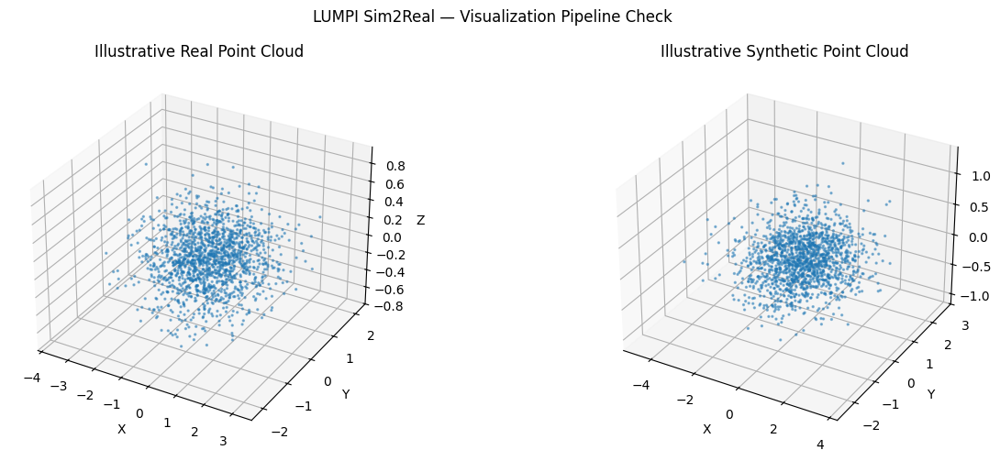

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Illustrative placeholder data only — not measured LUMPI data.
rng = np.random.default_rng(42)
n = 1500

real_x = rng.normal(0, 1.0, n)
real_y = rng.normal(0, 0.7, n)
real_z = rng.normal(0, 0.25, n)

synthetic_x = rng.normal(0.15, 1.1, n)
synthetic_y = rng.normal(0, 0.8, n)
synthetic_z = rng.normal(0.05, 0.3, n)

fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.scatter(real_x, real_y, real_z, s=2, alpha=0.45)
ax1.set_title("Illustrative Real Point Cloud")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(synthetic_x, synthetic_y, synthetic_z, s=2, alpha=0.45)
ax2.set_title("Illustrative Synthetic Point Cloud")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")

plt.suptitle("LUMPI Sim2Real — Visualization Pipeline Check")
plt.tight_layout()
plt.show()

## 12. 3D Driving Scene and LiDAR Visualization

Upgrade the prototype with three coordinated views: a road scene, a 3D LiDAR point cloud, and a bird’s-eye view. Animate the vehicle and nearby traffic, simulate a rotating LiDAR scan, and draw 3D bounding boxes around vehicles.

**Research note:** All points and objects in this cell are simulated. This is a visualization prototype, not measured LUMPI data or a validated physical sensor model.


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

rng = np.random.default_rng(12)
FRAMES = 60

fig = plt.figure(figsize=(15, 9))
ax_cam = fig.add_subplot(2, 2, 1)
ax_bev = fig.add_subplot(2, 2, 2)
ax_3d = fig.add_subplot(2, 2, 3, projection="3d")
ax_scan = fig.add_subplot(2, 2, 4)

fig.suptitle("LUMPI Sim2Real | Vehicle + LiDAR Lab", fontsize=15)

# 1. Perspective-inspired road scene
ax_cam.set_title("Driving Scene")
ax_cam.set_xlim(-10, 10)
ax_cam.set_ylim(0, 50)
ax_cam.set_facecolor("#30343b")
ax_cam.set_xlabel("Lateral position")
ax_cam.set_ylabel("Distance ahead")
ax_cam.axvspan(-3.5, 3.5, color="#555b64")
ax_cam.plot([-3.5, -3.5], [0, 50], color="white")
ax_cam.plot([3.5, 3.5], [0, 50], color="white")
for y in range(0, 50, 8):
    ax_cam.plot([0, 0], [y, y + 4], color="white", alpha=.8)

ego = plt.Rectangle((-.9, 3), 1.8, 4, color="deepskyblue")
ax_cam.add_patch(ego)
cars = [
    plt.Rectangle((-2.8, 20), 1.7, 3.8, color="orange"),
    plt.Rectangle((1.0, 37), 1.7, 3.8, color="tomato")
]
for c in cars:
    ax_cam.add_patch(c)

# 2. Bird's-eye view with object boxes
ax_bev.set_title("Bird's-Eye View + Object Boxes")
ax_bev.set_xlim(-15, 15)
ax_bev.set_ylim(-5, 50)
ax_bev.set_aspect("equal")
ax_bev.set_facecolor("#202329")
for x in [-3.5, 3.5]:
    ax_bev.axvline(x, color="white", linestyle="--", alpha=.5)
ego_bev = plt.Rectangle((-.9, 1), 1.8, 4, color="deepskyblue")
ax_bev.add_patch(ego_bev)
box1 = plt.Rectangle((-3, 20), 2, 4, fill=False, ec="orange", lw=2)
box2 = plt.Rectangle((.8, 37), 2, 4, fill=False, ec="tomato", lw=2)
ax_bev.add_patch(box1)
ax_bev.add_patch(box2)
bev_points = ax_bev.scatter([], [], s=2, c="yellow", alpha=.6)

# 3. 3D LiDAR view
ax_3d.set_title("3D LiDAR Point Cloud")
ax_3d.set_xlim(-15, 15)
ax_3d.set_ylim(0, 50)
ax_3d.set_zlim(-2, 5)
ax_3d.set_xlabel("X (m)")
ax_3d.set_ylabel("Y (m)")
ax_3d.set_zlabel("Z (m)")
lidar3d = ax_3d.scatter([], [], [], s=2, c=[], cmap="turbo", vmin=0, vmax=50)
ax_3d.view_init(elev=22, azim=-60)

# 4. Rotating scan display
ax_scan.set_title("LiDAR Azimuth Scan")
ax_scan.set_xlim(-35, 35)
ax_scan.set_ylim(-35, 35)
ax_scan.set_aspect("equal")
ax_scan.set_xlabel("X (m)")
ax_scan.set_ylabel("Y (m)")
ax_scan.scatter([0], [0], marker="s", c="cyan", s=70)
scan_points = ax_scan.scatter([], [], s=3, c="lime")
scan_ray, = ax_scan.plot([], [], color="lime", alpha=.8)
ax_scan.add_patch(plt.Circle((0, 0), 30, fill=False, ec="gray", alpha=.4))

def cuboid_edges(cx, cy, cz, length, width, height):
    xs = [cx-length/2, cx+length/2]
    ys = [cy-width/2, cy+width/2]
    zs = [cz-height/2, cz+height/2]
    corners = [(x,y,z) for x in xs for y in ys for z in zs]
    edges = []
    for i, a in enumerate(corners):
        for j, b in enumerate(corners):
            if j > i and sum(a[k] != b[k] for k in range(3)) == 1:
                edges.append((a,b))
    return edges

def draw_box(ax, center, color):
    for a, b in cuboid_edges(*center, 4.0, 1.8, 1.6):
        ax.plot([a[0],b[0]], [a[1],b[1]], [a[2],b[2]],
                color=color, linewidth=1.2)

def generate_points(frame):
    # Road edges, ground returns, and simplified car surfaces
    edge_y = rng.uniform(2, 48, 180)
    edges = np.vstack([
        np.column_stack((rng.normal(-3.5,.12,180), edge_y,
                         rng.normal(.1,.08,180))),
        np.column_stack((rng.normal(3.5,.12,180), edge_y,
                         rng.normal(.1,.08,180)))
    ])
    gx = rng.uniform(-12,12,350)
    gy = rng.uniform(2,48,350)
    ground = np.column_stack((gx,gy,rng.normal(-.1,.06,350)))

    car_points = []
    for cx, cy in [(-2, 20-frame*.12), (1.8, 37-frame*.08)]:
        if cy > 3:
            car_points.append(np.column_stack((
                rng.uniform(cx-1,cx+1,120),
                rng.uniform(cy,cy+4,120),
                rng.uniform(.1,1.7,120)
            )))
    pts = np.vstack([edges, ground] + car_points)
    # A simple rotating azimuth sampling mask
    angle = np.arctan2(pts[:,1], pts[:,0])
    scan_angle = (frame * 0.12) % (2*np.pi)
    delta = np.angle(np.exp(1j*(angle-scan_angle)))
    visible = np.abs(delta) < 0.45
    return pts, pts[visible], scan_angle

def update(frame):
    y1 = 20 - frame*.12
    y2 = 37 - frame*.08
    cars[0].set_xy((-2.8, y1))
    cars[1].set_xy((1.0, y2))
    box1.set_xy((-3, y1))
    box2.set_xy((.8, y2))

    pts, visible, angle = generate_points(frame)
    bev_points.set_offsets(pts[:, :2])
    lidar3d._offsets3d = (pts[:,0], pts[:,1], pts[:,2])
    lidar3d.set_array(np.sqrt((pts[:,0]**2)+(pts[:,1]**2)))

    scan_points.set_offsets(visible[:, :2])
    scan_ray.set_data(
        [0, 30*np.cos(angle)],
        [0, 30*np.sin(angle)]
    )
    ax_scan.set_title(f"LiDAR Azimuth Scan | Frame {frame+1}/{FRAMES}")
    ax_cam.set_title(f"Driving Scene | Frame {frame+1}/{FRAMES}")

    return cars + [box1, box2, bev_points, lidar3d, scan_points, scan_ray]

ani = FuncAnimation(fig, update, frames=FRAMES, interval=140, blit=False)
plt.tight_layout()
display(HTML(ani.to_jshtml()))
plt.close(fig)

## 13. Inspect the Official LUMPI Archive

Read the ZIP directory using HTTP range requests. List the archived filenames and sizes without downloading the full dataset. Identify candidate point-cloud files for our first real LiDAR visualization.


In [21]:
import requests
import struct

URL = "https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip"
session = requests.Session()

def get_range(start=None, end=None, suffix=None):
    if suffix is not None:
        header = f"bytes=-{suffix}"
    else:
        header = f"bytes={start}-{end}"

    response = session.get(
        URL,
        headers={"Range": header},
        stream=True,
        timeout=30
    )

    if response.status_code != 206:
        response.close()
        raise RuntimeError(
            f"Server did not honor the range request "
            f"(HTTP {response.status_code}). Stopped without downloading the archive."
        )

    data = response.raw.read()
    response.close()
    return data, response.headers.get("Content-Range")

# Read only the end of the archive to locate its directory.
tail, content_range = get_range(suffix=131072)
print("Range returned:", content_range)
eocd = tail.rfind(b"PK\x05\x06")

if eocd < 0:
    raise RuntimeError("ZIP directory marker not found in the archive's ending section.")

entry_count = struct.unpack_from("<H", tail, eocd + 10)[0]
directory_size = struct.unpack_from("<I", tail, eocd + 12)[0]
directory_offset = struct.unpack_from("<I", tail, eocd + 16)[0]

if entry_count == 0xFFFF or directory_size == 0xFFFFFFFF:
    raise RuntimeError("This archive uses ZIP64; we'll handle that separately.")

print("Files in archive:", entry_count)
print("Directory size:", directory_size, "bytes")

# Reuse the ending section if it contains the whole directory.
range_start = int(content_range.split()[1].split("-")[0])
if range_start <= directory_offset and (
    directory_offset + directory_size <= range_start + len(tail)
):
    directory = tail[
        directory_offset - range_start:
        directory_offset - range_start + directory_size
    ]
else:
    directory, _ = get_range(
        directory_offset, directory_offset + directory_size - 1
    )

# Parse central-directory records.
files = []
pos = 0

while pos + 46 <= len(directory) and directory[pos:pos+4] == b"PK\x01\x02":
    compressed = struct.unpack_from("<I", directory, pos + 20)[0]
    uncompressed = struct.unpack_from("<I", directory, pos + 24)[0]
    name_len, extra_len, comment_len = struct.unpack_from(
        "<HHH", directory, pos + 28
    )
    name_bytes = directory[pos+46:pos+46+name_len]
    name = name_bytes.decode("utf-8", errors="replace")

    files.append((name, compressed, uncompressed))
    pos += 46 + name_len + extra_len + comment_len

for name, compressed, uncompressed in files[:100]:
    print(f"{uncompressed / 1024:10.1f} KiB | {name}")

if len(files) > 100:
    print(f"... and {len(files) - 100} more entries")

Range returned: bytes 878964922-879095993/879095994
Files in archive: 348
Directory size: 40194 bytes
       0.0 KiB | test_data/
      36.5 KiB | test_data/meta.json
       0.0 KiB | test_data/Measurement4/
     327.6 KiB | test_data/Measurement4/Label.csv
       0.0 KiB | test_data/Measurement4/lidar/
    4391.8 KiB | test_data/Measurement4/lidar/000000.ply
    6292.3 KiB | test_data/Measurement4/lidar/000001.ply
    6313.2 KiB | test_data/Measurement4/lidar/000011.ply
    6291.9 KiB | test_data/Measurement4/lidar/000002.ply
    6285.0 KiB | test_data/Measurement4/lidar/000003.ply
    6290.9 KiB | test_data/Measurement4/lidar/000004.ply
    6300.7 KiB | test_data/Measurement4/lidar/000005.ply
    6305.4 KiB | test_data/Measurement4/lidar/000006.ply
    6308.6 KiB | test_data/Measurement4/lidar/000007.ply
    6306.9 KiB | test_data/Measurement4/lidar/000008.ply
    6308.7 KiB | test_data/Measurement4/lidar/000009.ply
    6306.2 KiB | test_data/Measurement4/lidar/000010.ply
    6314.4 

## 14. Retrieve One Real LiDAR Frame

Download only `Measurement5/lidar/000003.ply` from the ZIP archive using HTTP byte ranges. Save the extracted frame locally and inspect its PLY header. The download should be limited to this one file, not the complete archive.


In [22]:
import requests
import struct
import zlib
from pathlib import Path

URL = "https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip"
TARGET = "test_data/Measurement5/lidar/000003.ply"
OUT = Path("/kaggle/working/000003.ply")

def fetch_range(start, end):
    response = requests.get(
        URL,
        headers={"Range": f"bytes={start}-{end}"},
        timeout=60
    )
    if response.status_code != 206:
        raise RuntimeError(
            f"Range request failed: HTTP {response.status_code}. "
            "No full archive download attempted."
        )
    return response.content

# Read the ZIP directory at the end of the archive.
tail_response = requests.get(
    URL, headers={"Range": "bytes=-131072"}, timeout=30
)
if tail_response.status_code != 206:
    raise RuntimeError("Server did not honor the ZIP directory range request.")

tail = tail_response.content
content_range = tail_response.headers["Content-Range"]
tail_start = int(content_range.split()[1].split("-")[0])
eocd = tail.rfind(b"PK\x05\x06")
if eocd < 0:
    raise RuntimeError("ZIP directory marker not found.")

count = struct.unpack_from("<H", tail, eocd + 10)[0]
cd_size = struct.unpack_from("<I", tail, eocd + 12)[0]
cd_offset = struct.unpack_from("<I", tail, eocd + 16)[0]

if count == 0xFFFF or cd_size == 0xFFFFFFFF:
    raise RuntimeError("ZIP64 archive detected; use a ZIP64-aware method.")

if tail_start <= cd_offset and cd_offset + cd_size <= tail_start + len(tail):
    directory = tail[cd_offset-tail_start:cd_offset-tail_start+cd_size]
else:
    directory = fetch_range(cd_offset, cd_offset + cd_size - 1)

# Find the exact target entry.
pos = 0
entry = None
while pos + 46 <= len(directory) and directory[pos:pos+4] == b"PK\x01\x02":
    method = struct.unpack_from("<H", directory, pos + 10)[0]
    compressed = struct.unpack_from("<I", directory, pos + 20)[0]
    uncompressed = struct.unpack_from("<I", directory, pos + 24)[0]
    name_len, extra_len, comment_len = struct.unpack_from(
        "<HHH", directory, pos + 28
    )
    name = directory[pos+46:pos+46+name_len].decode(
        "utf-8", errors="replace"
    )
    local_offset = struct.unpack_from("<I", directory, pos + 42)[0]

    if name == TARGET:
        entry = (method, compressed, uncompressed, local_offset)
        break
    pos += 46 + name_len + extra_len + comment_len

if entry is None:
    raise FileNotFoundError(f"Could not find {TARGET} in archive.")

method, compressed_size, uncompressed_size, local_offset = entry
print("Target:", TARGET)
print("Compression method:", method, "(0=stored, 8=deflate)")
print(f"Compressed size: {compressed_size / 1024:.1f} KiB")
print(f"Expected extracted size: {uncompressed_size / 1024:.1f} KiB")

# Read local ZIP header to locate the actual file bytes.
local = fetch_range(local_offset, local_offset + 29)
if local[:4] != b"PK\x03\x04":
    raise RuntimeError("Invalid local ZIP header.")

filename_len, extra_len = struct.unpack_from("<HH", local, 26)
data_start = local_offset + 30 + filename_len + extra_len
payload = fetch_range(data_start, data_start + compressed_size - 1)

if method == 0:
    ply_bytes = payload
elif method == 8:
    ply_bytes = zlib.decompress(payload, -15)
else:
    raise RuntimeError(f"Unsupported ZIP compression method: {method}")

if len(ply_bytes) != uncompressed_size:
    raise RuntimeError("Extracted size does not match ZIP directory.")

OUT.write_bytes(ply_bytes)
print("\nSaved:", OUT)
print("Actual size:", round(len(ply_bytes) / 1024, 1), "KiB")
print("\n--- PLY header ---")
print(ply_bytes[:1000].decode("ascii", errors="replace"))

Target: test_data/Measurement5/lidar/000003.ply
Compression method: 8 (0=stored, 8=deflate)
Compressed size: 5099.6 KiB
Expected extracted size: 6280.0 KiB

Saved: /kaggle/working/000003.ply
Actual size: 6280.0 KiB

--- PLY header ---
ply
format binary_little_endian 1.0
element vertex 279584
property float x
property float y
property float z
property uint time
property uchar id
property uchar intensity
property uchar ray
property ushort azimuth
property ushort distance
end_header
��@�	yA�J��� 2i���j��p{B�+@�� 2�j�b%���@��fA������ 2k�"�?r@L�[A�+���� 2�l�����@�&A[w
��� 27l���r�@�i#A
��� 2>21l����A?��Ay��� 2m�z��-@��AIf|��� 2	n�A��\@��;A��
p��� 2/A�B���� 2Ao�A�i�@KBX����� 2Tp�]%8�@^�A
��1�1BU�x�� 2u�M.=w�@�f=B�.�=�� 2.r��'."q>@�B���>�� 2;r��)%|�?��Be��� � 2.s��$S���$B�s=?� 23t��+<�����A��_?� 2�u�	����n
B	,�?� 2dx�U&�&@�B�jo@� 2Vy��'���>��B�w�@� 2Sy��)���?��B�Q@� 2z��(���@��������� 29!i��$��@�Kl?���� 2

## 15. Visualize Real LUMPI LiDAR

Parse the binary PLY file using its verified header. Generate three plots: a 3D point cloud, a bird’s-eye view, and a height-colored point cloud. These are real sensor measurements from the downloaded frame, not simulated points.


ply
format binary_little_endian 1.0
element vertex 279584
property float x
property float y
property float z
property uint time
property uchar id
property uchar intensity
property uchar ray
property ushort azimuth
property ushort distance
end_header

Valid points: 279584
X range: [-205.71  165.52]
Y range: [-137.37  162.21]
Z range: [-7.8  21.79]


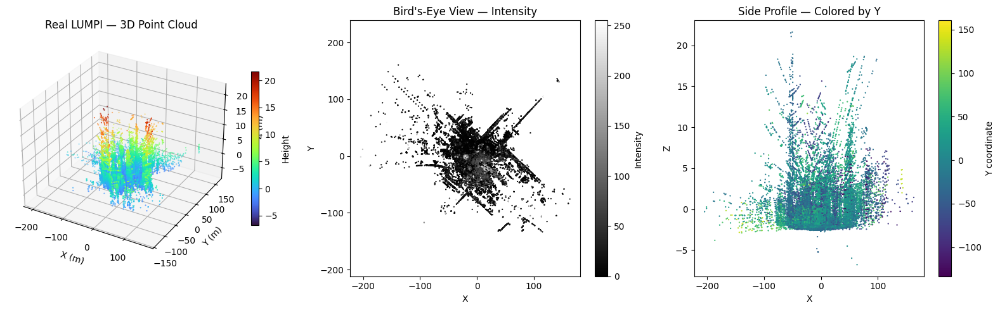

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ply_path = Path("/kaggle/working/000003.ply")
raw = ply_path.read_bytes()

# Verified schema from this frame's PLY header.
header_end = raw.find(b"end_header\n")
if header_end < 0:
    raise ValueError("Could not find PLY header terminator.")

header = raw[:header_end + len(b"end_header\n")].decode("ascii")
print(header)

vertex_count = int(
    next(line.split()[2] for line in header.splitlines()
         if line.startswith("element vertex "))
)

dtype = np.dtype([
    ("x", "<f4"),
    ("y", "<f4"),
    ("z", "<f4"),
    ("time", "<u4"),
    ("id", "u1"),
    ("intensity", "u1"),
    ("ray", "u1"),
    ("azimuth", "<u2"),
    ("distance", "<u2"),
])

offset = header_end + len(b"end_header\n")
points = np.frombuffer(
    raw, dtype=dtype, count=vertex_count, offset=offset
)

xyz = np.column_stack([points["x"], points["y"], points["z"]])
valid = np.isfinite(xyz).all(axis=1)
xyz = xyz[valid]
intensity = points["intensity"][valid]

print("Valid points:", len(xyz))
print("X range:", np.round([xyz[:,0].min(), xyz[:,0].max()], 2))
print("Y range:", np.round([xyz[:,1].min(), xyz[:,1].max()], 2))
print("Z range:", np.round([xyz[:,2].min(), xyz[:,2].max()], 2))

# Plot at most 60,000 points for responsive rendering.
rng = np.random.default_rng(42)
idx = rng.choice(len(xyz), min(60000, len(xyz)), replace=False)
p = xyz[idx]
inten = intensity[idx]

fig = plt.figure(figsize=(16, 5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
sc = ax1.scatter(p[:,0], p[:,1], p[:,2],
                 c=p[:,2], s=0.3, cmap="turbo")
ax1.set_title("Real LUMPI — 3D Point Cloud")
ax1.set_xlabel("X (m)")
ax1.set_ylabel("Y (m)")
ax1.set_zlabel("Z (m)")
fig.colorbar(sc, ax=ax1, shrink=.6, label="Height")

ax2 = fig.add_subplot(1, 3, 2)
sc2 = ax2.scatter(p[:,0], p[:,1], s=0.4,
                  c=inten, cmap="gray")
ax2.set_title("Bird's-Eye View — Intensity")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_aspect("equal", adjustable="datalim")
fig.colorbar(sc2, ax=ax2, label="Intensity")

ax3 = fig.add_subplot(1, 3, 3)
sc3 = ax3.scatter(p[:,0], p[:,2], s=0.4,
                  c=p[:,1], cmap="viridis")
ax3.set_title("Side Profile — Colored by Y")
ax3.set_xlabel("X")
ax3.set_ylabel("Z")
fig.colorbar(sc3, ax=ax3, label="Y coordinate")

plt.tight_layout()
plt.show()

## 16. Real LiDAR Data Quality Dashboard

Analyze the actual LUMPI frame before interpreting its geometry. Visualize the bird’s-eye point distribution, height distribution, radial distance distribution, and sensor intensity values. Report robust percentiles to identify outliers and understand the scene’s spatial coverage.

All plots use the extracted real frame. Coordinate orientation and units should be confirmed from the dataset documentation before drawing physical conclusions.


Valid points: 279,584
Unique intensity values: 256
X                | min= -205.71 p01= -75.05 median=  -3.48 p99=  80.40 max=  165.52
Y                | min= -137.37 p01= -77.06 median=  -0.87 p99=  66.54 max=  162.21
Z                | min=   -7.80 p01=  -2.45 median=  -1.98 p99=   9.36 max=   21.79
Radial distance  | min=    2.05 p01=   5.19 median=  26.66 p99= 117.54 max=  215.68
Intensity        | min=    0.00 p01=   0.00 median=  18.00 p99= 254.00 max=  255.00


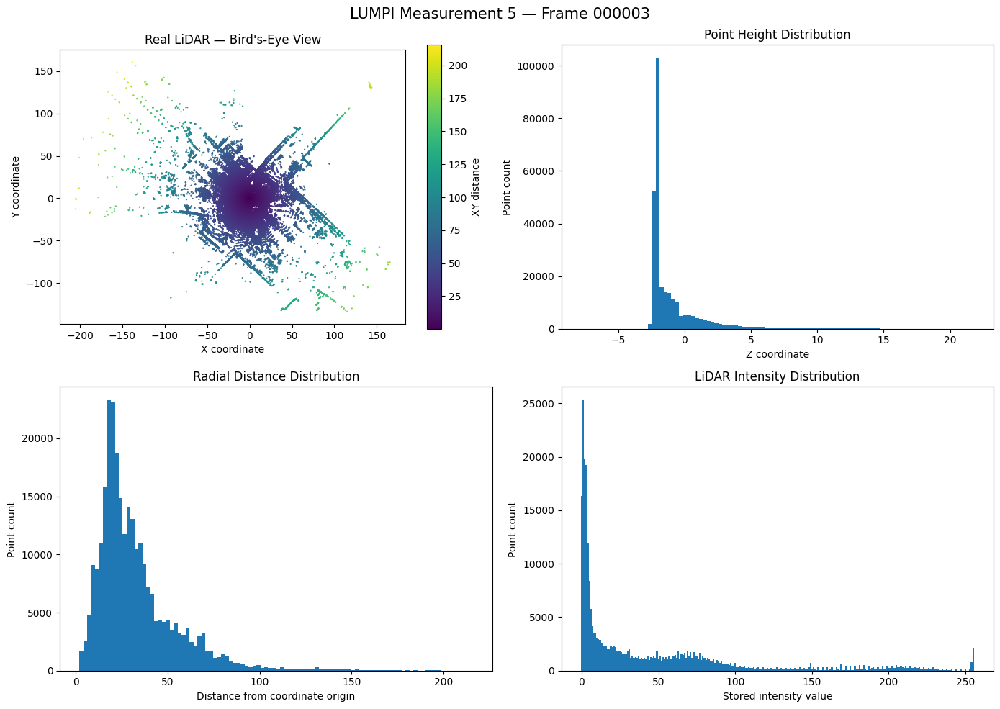

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Reuse the real point cloud loaded in Cell 15.
xyz = np.column_stack([points["x"], points["y"], points["z"]])
valid = np.isfinite(xyz).all(axis=1)
xyz = xyz[valid]
intensity = points["intensity"][valid].astype(np.float32)

# Radial distance in the stored XYZ coordinate system
radius = np.sqrt(np.sum(xyz**2, axis=1))

print(f"Valid points: {len(xyz):,}")
print(f"Unique intensity values: {len(np.unique(intensity)):,}")

for name, values in [
    ("X", xyz[:, 0]),
    ("Y", xyz[:, 1]),
    ("Z", xyz[:, 2]),
    ("Radial distance", radius),
    ("Intensity", intensity),
]:
    pcts = np.percentile(values, [1, 25, 50, 75, 99])
    print(
        f"{name:16s} | min={values.min():8.2f} "
        f"p01={pcts[0]:7.2f} median={pcts[2]:7.2f} "
        f"p99={pcts[4]:7.2f} max={values.max():8.2f}"
    )

# Subsample for responsive plotting; statistics above use all valid points.
rng = np.random.default_rng(42)
idx = rng.choice(len(xyz), min(80000, len(xyz)), replace=False)
sample = xyz[idx]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Bird's-eye view
ax = axes[0, 0]
sc = ax.scatter(
    sample[:, 0], sample[:, 1],
    c=np.sqrt(sample[:, 0]**2 + sample[:, 1]**2),
    s=0.35, cmap="viridis", rasterized=True
)
ax.set_title("Real LiDAR — Bird's-Eye View")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal", adjustable="box")
fig.colorbar(sc, ax=ax, label="XY distance")

# Height distribution
ax = axes[0, 1]
ax.hist(xyz[:, 2], bins=100)
ax.set_title("Point Height Distribution")
ax.set_xlabel("Z coordinate")
ax.set_ylabel("Point count")

# Radial distance distribution
ax = axes[1, 0]
ax.hist(radius, bins=100)
ax.set_title("Radial Distance Distribution")
ax.set_xlabel("Distance from coordinate origin")
ax.set_ylabel("Point count")

# Intensity distribution
ax = axes[1, 1]
ax.hist(intensity, bins=np.arange(-0.5, 256.5, 1))
ax.set_title("LiDAR Intensity Distribution")
ax.set_xlabel("Stored intensity value")
ax.set_ylabel("Point count")

plt.suptitle("LUMPI Measurement 5 — Frame 000003", fontsize=15)
plt.tight_layout()
plt.show()

## 17. Inspect Real LUMPI Labels

Retrieve only `Measurement5/Label.csv` from the same official ZIP archive using HTTP range requests. Inspect the CSV columns and sample rows to learn how labels are represented before attempting to overlay them on the LiDAR point cloud.


In [25]:
import requests
import struct
import zlib
import pandas as pd
from io import BytesIO

URL = "https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip"
TARGET = "test_data/Measurement5/Label.csv"

def fetch_range(start, end):
    r = requests.get(
        URL,
        headers={"Range": f"bytes={start}-{end}"},
        timeout=60
    )
    if r.status_code != 206:
        raise RuntimeError(
            f"Range request failed (HTTP {r.status_code}); "
            "stopped without downloading the full archive."
        )
    return r.content

# Read ZIP directory metadata.
r = requests.get(URL, headers={"Range": "bytes=-131072"}, timeout=30)
if r.status_code != 206:
    raise RuntimeError("Server did not honor the ZIP range request.")

tail = r.content
tail_start = int(r.headers["Content-Range"].split()[1].split("-")[0])
eocd = tail.rfind(b"PK\x05\x06")
if eocd < 0:
    raise RuntimeError("ZIP directory marker not found.")

count = struct.unpack_from("<H", tail, eocd + 10)[0]
cd_size = struct.unpack_from("<I", tail, eocd + 12)[0]
cd_offset = struct.unpack_from("<I", tail, eocd + 16)[0]
if count == 0xFFFF or cd_size == 0xFFFFFFFF:
    raise RuntimeError("ZIP64 archive detected; needs a ZIP64-aware reader.")

if tail_start <= cd_offset and cd_offset + cd_size <= tail_start + len(tail):
    directory = tail[cd_offset-tail_start:cd_offset-tail_start+cd_size]
else:
    directory = fetch_range(cd_offset, cd_offset + cd_size - 1)

# Locate the label file in the ZIP directory.
pos, entry = 0, None
while pos + 46 <= len(directory) and directory[pos:pos+4] == b"PK\x01\x02":
    method = struct.unpack_from("<H", directory, pos + 10)[0]
    compressed = struct.unpack_from("<I", directory, pos + 20)[0]
    uncompressed = struct.unpack_from("<I", directory, pos + 24)[0]
    name_len, extra_len, comment_len = struct.unpack_from(
        "<HHH", directory, pos + 28
    )
    name = directory[pos+46:pos+46+name_len].decode("utf-8", errors="replace")
    local_offset = struct.unpack_from("<I", directory, pos + 42)[0]

    if name == TARGET:
        entry = (method, compressed, uncompressed, local_offset)
        break
    pos += 46 + name_len + extra_len + comment_len

if entry is None:
    raise FileNotFoundError(f"{TARGET} not found in archive.")

method, compressed, uncompressed, local_offset = entry
local = fetch_range(local_offset, local_offset + 29)
name_len, extra_len = struct.unpack_from("<HH", local, 26)
data_start = local_offset + 30 + name_len + extra_len
payload = fetch_range(data_start, data_start + compressed - 1)

if method == 0:
    csv_bytes = payload
elif method == 8:
    csv_bytes = zlib.decompress(payload, -15)
else:
    raise RuntimeError(f"Unsupported ZIP compression method: {method}")

if len(csv_bytes) != uncompressed:
    raise RuntimeError("Extracted CSV size mismatch.")

print("Label file size:", len(csv_bytes), "bytes")
print("\n--- First 1200 characters ---")
print(csv_bytes[:1200].decode("utf-8", errors="replace"))

labels = pd.read_csv(BytesIO(csv_bytes))
print("\nShape:", labels.shape)
print("\nColumns:")
print(labels.columns.tolist())
print("\nFirst five rows:")
display(labels.head())

Label file size: 205360 bytes

--- First 1200 characters ---
time,object id, 2d rectangle: top left x,top left y, width,height,score,class_id,visibility,3D box: center x,y,z,length, width ,height,heading,[optional arbitarry many double: shape parameter or point index or embeddings]
0.000,0,11.025,21.650,4.734,4.989,0.000,1,648.000,13.392,24.144,-1.420,4.810,2.080,1.850,-2.290
0.000,1,-44.797,-2.004,5.471,2.895,4.000,1,384.000,-42.061,-0.557,-1.090,5.210,2.140,1.790,-0.150
0.000,2,1.037,8.269,4.778,4.221,4.000,1,2109.000,3.426,10.380,-1.420,4.590,1.840,1.620,-2.500
0.000,3,3.322,14.157,4.711,4.491,4.000,1,210.000,5.677,16.402,-1.650,4.480,2.040,1.630,-2.420
0.000,4,-2.549,22.576,1.870,1.757,4.000,2,594.000,-1.614,23.454,-1.200,1.900,0.670,1.860,-0.720
0.000,5,5.378,20.331,1.083,1.037,4.000,0,192.000,5.920,20.850,-1.360,0.860,0.660,1.750,-2.520
0.000,6,51.393,-40.438,11.555,11.497,4.000,4,177.000,57.170,-34.690,-0.500,13.500,2.800,3.120,2.360
0.000,7,26.396,0.422,2.069,1.397,4.000,2,30.0

,time,object id,2d rectangle: top left x,top left y,width,height,score,class_id,visibility,3D box: center x,y,z,length,width,height.1,heading,[optional arbitarry many double: shape parameter or point index or embeddings]
0,0.0,0,11.025,21.650,4.734,4.989,0.0,1,648.0,13.392,24.144,-1.42,4.81,2.08,1.85,-2.29,NaN
1,0.0,1,-44.797,-2.004,5.471,2.895,4.0,1,384.0,-42.061,-0.557,-1.09,5.21,2.14,1.79,-0.15,NaN
2,0.0,2,1.037,8.269,4.778,4.221,4.0,1,2109.0,3.426,10.380,-1.42,4.59,1.84,1.62,-2.50,NaN
3,0.0,3,3.322,14.157,4.711,4.491,4.0,1,210.0,5.677,16.402,-1.65,4.48,2.04,1.63,-2.42,NaN
4,0.0,4,-2.549,22.576,1.870,1.757,4.0,2,594.0,-1.614,23.454,-1.20,1.90,0.67,1.86,-0.72,NaN


## 18. Visualize Real LUMPI LiDAR with 3D Bounding Boxes

Plot the real LiDAR point cloud from frame `000003.ply` and overlay the ground-truth 3D bounding boxes from the LUMPI label file. First inspect the timestamps to confirm which labels correspond to this frame, then display a bird’s-eye view with object centers, oriented bounding boxes, and class IDs. This is real dataset visualization, not simulated data.


Objects at timestamp 0: 65


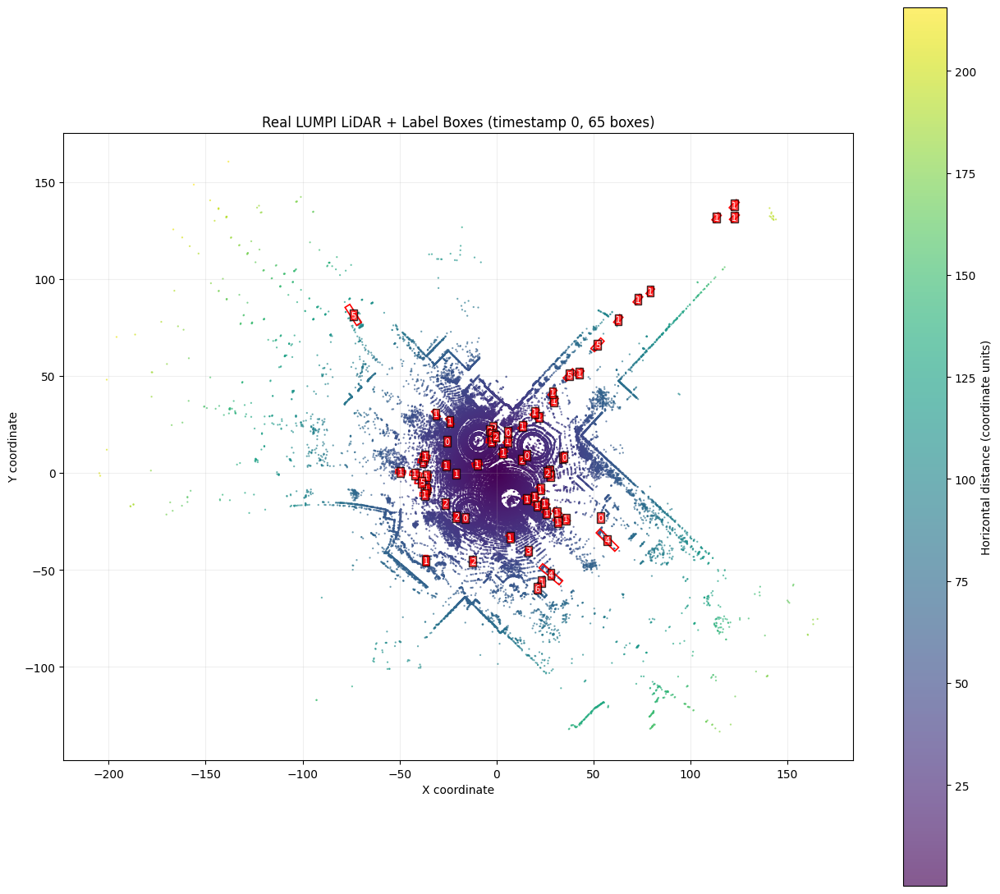

Boxes drawn: 65


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Explicitly map columns by their original positions to avoid duplicate names
# in the CSV (such as y, width, and height).
label_data = labels.copy()
label_data.columns = [
    "time", "object_id", "bbox2d_x", "bbox2d_y",
    "bbox2d_width", "bbox2d_height", "score", "class_id",
    "visibility", "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading", "extra"
]

# Ensure box fields are numeric
numeric_cols = [
    "time", "class_id", "center_x", "center_y",
    "length", "box_width", "heading"
]
for col in numeric_cols:
    label_data[col] = pd.to_numeric(label_data[col], errors="coerce")

frame_labels = label_data[np.isclose(label_data["time"], 0.0)].copy()

print("Objects at timestamp 0:", len(frame_labels))

# Plot actual point cloud
fig, ax = plt.subplots(figsize=(13, 11))

rng = np.random.default_rng(42)
sample_n = min(70000, len(xyz))
sample_idx = rng.choice(len(xyz), sample_n, replace=False)
cloud = xyz[sample_idx]

sc = ax.scatter(
    cloud[:, 0], cloud[:, 1],
    c=np.hypot(cloud[:, 0], cloud[:, 1]),
    s=0.4, cmap="viridis", alpha=0.65
)
plt.colorbar(sc, ax=ax, label="Horizontal distance (coordinate units)")

# Overlay oriented box footprints
drawn = 0

for _, row in frame_labels.iterrows():
    values = [
        row["center_x"], row["center_y"],
        row["length"], row["box_width"], row["heading"]
    ]

    # Each field should now be a scalar
    if not np.isfinite(np.asarray(values, dtype=float)).all():
        continue

    cx, cy, length, width, heading = map(float, values)

    if length <= 0 or width <= 0:
        continue

    corners = np.array([
        [-length/2, -width/2],
        [ length/2, -width/2],
        [ length/2,  width/2],
        [-length/2,  width/2]
    ])

    rotation = np.array([
        [np.cos(heading), -np.sin(heading)],
        [np.sin(heading),  np.cos(heading)]
    ])

    corners = corners @ rotation.T + np.array([cx, cy])

    ax.add_patch(Polygon(
        corners, closed=True, fill=False,
        edgecolor="red", linewidth=1.2
    ))

    ax.text(
        cx, cy, str(int(row["class_id"])),
        color="white", fontsize=7,
        ha="center", va="center",
        bbox=dict(facecolor="red", alpha=0.75, pad=1)
    )
    drawn += 1

ax.set_title(f"Real LUMPI LiDAR + Label Boxes (timestamp 0, {drawn} boxes)")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Boxes drawn:", drawn)

## 19. Diagnose LiDAR and Label Alignment

Compare the point-cloud coordinate range with the labeled 3D box centers. This helps identify whether the labels and LiDAR scan use compatible coordinate systems.


In [28]:
print("LiDAR XY range:")
print("X:", float(xyz[:, 0].min()), "to", float(xyz[:, 0].max()))
print("Y:", float(xyz[:, 1].min()), "to", float(xyz[:, 1].max()))

print("\nTimestamp-0 label center range:")
for col in ["center_x", "center_y", "center_z"]:
    vals = pd.to_numeric(frame_labels[col], errors="coerce").dropna()
    print(f"{col}: {vals.min():.2f} to {vals.max():.2f}")

print("\nFirst 10 label centers:")
display(frame_labels[
    ["object_id", "class_id", "center_x", "center_y",
     "center_z", "length", "box_width", "heading"]
].head(10))

LiDAR XY range:
X: -205.71168518066406 to 165.51954650878906
Y: -137.36651611328125 to 162.21438598632812

Timestamp-0 label center range:
center_x: -73.91 to 122.66
center_y: -59.51 to 138.12
center_z: -1.90 to -0.36

First 10 label centers:


,object_id,class_id,center_x,center_y,center_z,length,box_width,heading
0,0,1,13.392,24.144,-1.42,4.81,2.08,-2.29
1,1,1,-42.061,-0.557,-1.09,5.21,2.14,-0.15
2,2,1,3.426,10.380,-1.42,4.59,1.84,-2.50
3,3,1,5.677,16.402,-1.65,4.48,2.04,-2.42
4,4,2,-1.614,23.454,-1.20,1.90,0.67,-0.72
5,5,0,5.920,20.850,-1.36,0.86,0.66,-2.52
6,6,4,57.170,-34.690,-0.50,13.50,2.80,2.36
7,7,2,27.430,1.120,-1.42,1.89,0.94,2.88
8,8,2,27.890,-1.460,-1.38,1.85,0.91,2.67
9,9,2,-20.660,-22.510,-1.33,2.36,0.85,2.50


## 20. Zoom Into Labeled Objects

Create a bird’s-eye LiDAR visualization around the labeled objects near the sensor. Color points by intensity and overlay the oriented bounding boxes, with class IDs and object centers. This zoomed view helps us inspect whether the labels align with the real scan.


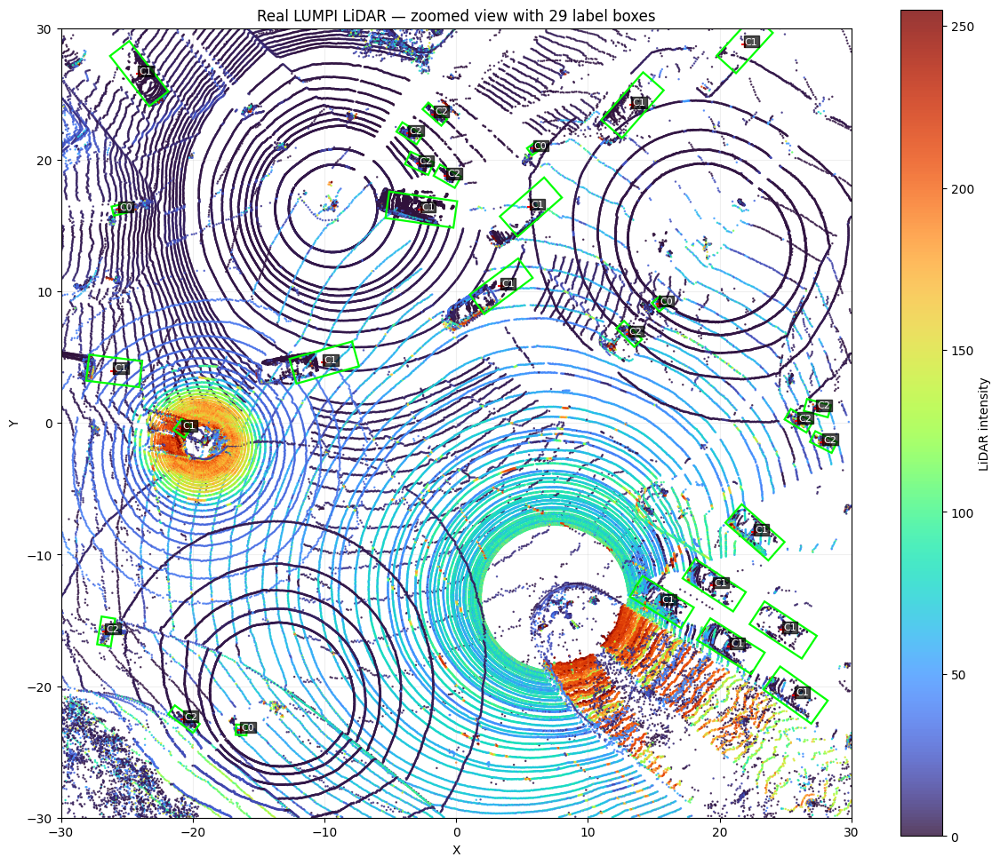

Points in zoom: 181351
Label boxes in zoom: 29


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Use the timestamp-0 label centers to choose a useful viewing window.
# Start with a 60 m × 60 m region around the sensor.
RANGE = 30.0

mask = (
    (np.abs(xyz[:, 0]) <= RANGE) &
    (np.abs(xyz[:, 1]) <= RANGE)
)
local_xyz = xyz[mask]

# Recover matching intensity values from the original PLY records.
local_intensity = points["intensity"][valid][mask].astype(float)

fig, ax = plt.subplots(figsize=(12, 10))

sc = ax.scatter(
    local_xyz[:, 0], local_xyz[:, 1],
    c=local_intensity, cmap="turbo",
    s=0.6, alpha=0.8, vmin=0, vmax=255
)
fig.colorbar(sc, ax=ax, label="LiDAR intensity")

drawn = 0
for _, row in frame_labels.iterrows():
    vals = np.array([
        row["center_x"], row["center_y"],
        row["length"], row["box_width"], row["heading"]
    ], dtype=float)

    if not np.isfinite(vals).all():
        continue

    cx, cy, length, width, heading = vals

    # Only show boxes within this zoomed region.
    if abs(cx) > RANGE or abs(cy) > RANGE:
        continue
    if length <= 0 or width <= 0:
        continue

    corners = np.array([
        [-length/2, -width/2],
        [ length/2, -width/2],
        [ length/2,  width/2],
        [-length/2,  width/2]
    ])

    rot = np.array([
        [np.cos(heading), -np.sin(heading)],
        [np.sin(heading),  np.cos(heading)]
    ])
    corners = corners @ rot.T + [cx, cy]

    ax.add_patch(Polygon(
        corners, closed=True, fill=False,
        edgecolor="lime", linewidth=1.6
    ))
    ax.scatter(cx, cy, marker="+", c="red", s=30)
    ax.text(
        cx, cy, f"C{int(row['class_id'])}",
        color="white", fontsize=8,
        bbox=dict(facecolor="black", alpha=0.7, pad=1)
    )
    drawn += 1

ax.set_xlim(-RANGE, RANGE)
ax.set_ylim(-RANGE, RANGE)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title(f"Real LUMPI LiDAR — zoomed view with {drawn} label boxes")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Points in zoom:", len(local_xyz))
print("Label boxes in zoom:", drawn)

## 21. Verify Label Timestamps and Frame Alignment

Inspect the label timestamps and object counts per timestamp. Then compare the current frame's point-cloud geometry with the labeled object centers. Do not assume timestamp 0.0 matches `000003.ply` until the dataset's timing convention is verified.


Timestamp range: 0.0 to 3.0
Number of timestamps: 31

Objects per timestamp:


,object_count
time,
0.0,65
0.1,66
0.2,67
0.3,68
0.4,67
0.5,68
0.6,67
0.7,68
0.8,68


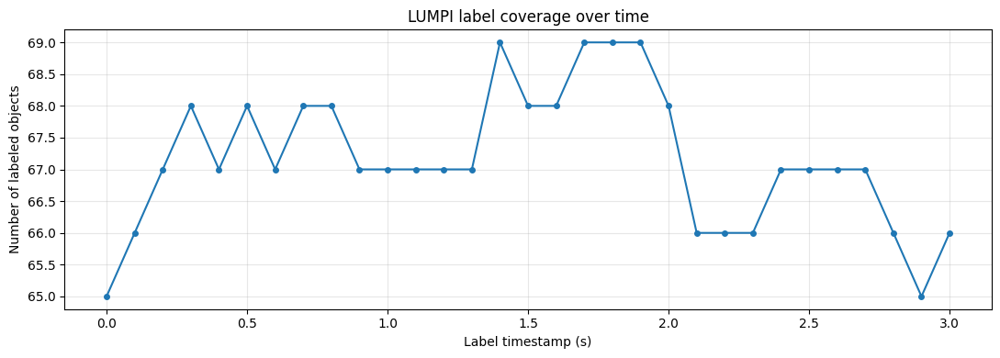

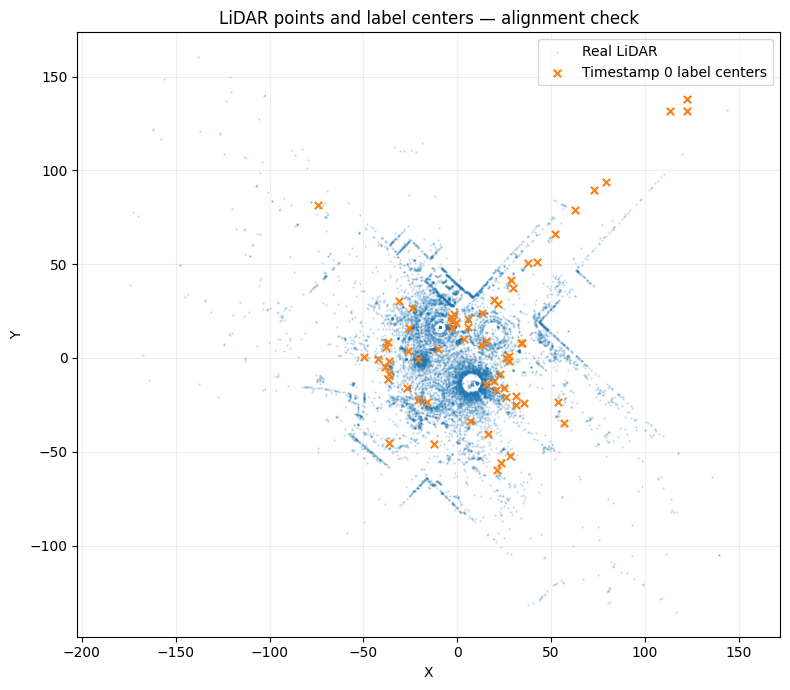

In [30]:
# Summarize label counts over time
counts = label_data.groupby("time").size().sort_index()

print("Timestamp range:", label_data["time"].min(), "to", label_data["time"].max())
print("Number of timestamps:", len(counts))
print("\nObjects per timestamp:")
display(counts.rename("object_count").to_frame().head(15))

# Plot object count over time
plt.figure(figsize=(11, 4))
plt.plot(counts.index, counts.values, marker="o", markersize=4)
plt.xlabel("Label timestamp (s)")
plt.ylabel("Number of labeled objects")
plt.title("LUMPI label coverage over time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare the spatial distributions of point cloud and label centers
label_centers = frame_labels[["center_x", "center_y"]].to_numpy(dtype=float)
label_centers = label_centers[np.isfinite(label_centers).all(axis=1)]

plt.figure(figsize=(8, 7))
plt.scatter(xyz[::20, 0], xyz[::20, 1],
            s=0.3, alpha=0.25, label="Real LiDAR")
plt.scatter(label_centers[:, 0], label_centers[:, 1],
            s=28, marker="x", label="Timestamp 0 label centers")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("LiDAR points and label centers — alignment check")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## 22. Identify the Correct LiDAR Frame Timestamp

Inspect the archive metadata for the LiDAR sequence and its label file. Determine whether frame `000003.ply` corresponds to timestamp 0.0 seconds or another timestamp. Do not assume frame index and label timestamp are interchangeable.

In [31]:
import requests
import struct

URL = "https://data.uni-hannover.de/vault/ikg/busch/LUMPI/test_data.zip"

# Read the ZIP archive's final section to locate its directory.
r = requests.get(URL, headers={"Range": "bytes=-131072"}, timeout=30)
r.raise_for_status()

tail = r.content
tail_start = int(r.headers["Content-Range"].split()[1].split("-")[0])
eocd = tail.rfind(b"PK\x05\x06")

if eocd < 0:
    raise RuntimeError("ZIP directory marker not found.")

cd_size = struct.unpack_from("<I", tail, eocd + 12)[0]
cd_offset = struct.unpack_from("<I", tail, eocd + 16)[0]

if tail_start <= cd_offset and cd_offset + cd_size <= tail_start + len(tail):
    directory = tail[cd_offset - tail_start:cd_offset - tail_start + cd_size]
else:
    r = requests.get(
        URL,
        headers={"Range": f"bytes={cd_offset}-{cd_offset + cd_size - 1}"},
        timeout=60
    )
    r.raise_for_status()
    directory = r.content

# List frame files and related metadata for Measurement5.
pos = 0
matches = []

while pos + 46 <= len(directory) and directory[pos:pos + 4] == b"PK\x01\x02":
    name_len, extra_len, comment_len = struct.unpack_from(
        "<HHH", directory, pos + 28
    )
    name = directory[pos + 46:pos + 46 + name_len].decode(
        "utf-8", errors="replace"
    )

    if name.startswith("test_data/Measurement5/") and (
        name.endswith(".ply") or
        name.endswith(".csv") or
        name.endswith(".txt") or
        name.endswith(".json")
    ):
        matches.append(name)

    pos += 46 + name_len + extra_len + comment_len

print("Relevant archive entries:", len(matches))
for name in matches[:40]:
    print(name)

Relevant archive entries: 33
test_data/Measurement5/lidar/000011.ply
test_data/Measurement5/lidar/000012.ply
test_data/Measurement5/lidar/000013.ply
test_data/Measurement5/lidar/000014.ply
test_data/Measurement5/lidar/000015.ply
test_data/Measurement5/lidar/000016.ply
test_data/Measurement5/lidar/000017.ply
test_data/Measurement5/lidar/000018.ply
test_data/Measurement5/lidar/000019.ply
test_data/Measurement5/lidar/000020.ply
test_data/Measurement5/lidar/000021.ply
test_data/Measurement5/lidar/000022.ply
test_data/Measurement5/lidar/000023.ply
test_data/Measurement5/lidar/000024.ply
test_data/Measurement5/lidar/000025.ply
test_data/Measurement5/lidar/000026.ply
test_data/Measurement5/lidar/000027.ply
test_data/Measurement5/lidar/000028.ply
test_data/Measurement5/lidar/000029.ply
test_data/Measurement5/lidar/000030.ply
test_data/Measurement5/lidar/000000.ply
test_data/Measurement5/lidar/000001.ply
test_data/Measurement5/lidar/000002.ply
test_data/Measurement5/lidar/000003.ply
test_data/M

## LUMPI Ground-Truth Audit — Timestamp Alignment and 3D Box Support

Compare the real LiDAR frame with the annotation CSV across all available timestamps. For each timestamp, measure how many LiDAR points fall inside the annotated oriented 3D boxes under two possible length/width axis conventions.

The output includes:

* Candidate timestamp alignment rankings.
* Object classes and annotation score fields.
* Point support for each box.
* A real point-cloud visualization with candidate ground-truth boxes.

**Important:** Point support is a diagnostic, not proof of alignment. The best-scoring timestamp must still agree with the dataset's frame timing convention before its boxes are treated as verified ground truth. No detection AP is reported in this step.


Real scan: 000003.ply
Finite LiDAR points: 279,584
Annotation rows: 2,082
Rows with usable 3D geometry: 2,082
Rows excluded for missing/invalid geometry: 0
Annotation timestamps: 31

=== TOP CANDIDATE ALIGNMENTS ===


,timestamp,axis_convention,usable_boxes,boxes_with_1plus_points,boxes_with_5plus_points,boxes_with_20plus_points,median_points_per_box,total_box_point_counts
0,0.3,length_X_width_Y,68,62,60,60,195.0,32389
1,0.4,width_X_length_Y,67,61,60,55,103.0,17103
2,0.3,width_X_length_Y,68,61,60,57,100.0,18238
3,0.5,width_X_length_Y,68,62,60,54,100.0,16320
4,0.5,length_X_width_Y,68,62,59,57,187.0,27468
5,0.2,length_X_width_Y,67,60,59,59,183.0,31078
6,0.4,length_X_width_Y,67,61,59,58,183.0,29624
7,0.6,length_X_width_Y,67,61,59,58,183.0,25250
8,0.2,width_X_length_Y,67,59,59,56,104.0,18652
9,0.6,width_X_length_Y,67,60,59,52,99.0,15454



=== BEST TIMESTAMP PER AXIS CONVENTION ===


,timestamp,axis_convention,usable_boxes,boxes_with_1plus_points,boxes_with_5plus_points,boxes_with_20plus_points,median_points_per_box,total_box_point_counts
0,0.3,length_X_width_Y,68,62,60,60,195.0,32389
1,0.4,width_X_length_Y,67,61,60,55,103.0,17103


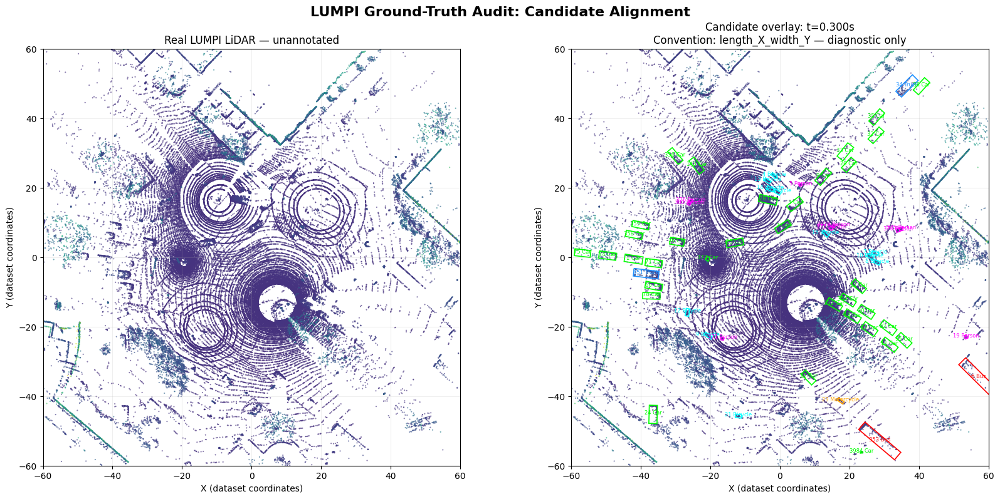


=== OBJECT-LEVEL AUDIT FOR TOP CANDIDATE ===


,time,object_id,class_id,class_name,score,visibility,center_x,center_y,center_z,length,box_width,box_height,heading,points_inside
0,0.3,5,0,Person,4.0,795.0,5.920,20.850,-1.360,0.860,0.660,1.750,-2.520,208
1,0.3,19,0,Person,4.0,117.0,53.518,-22.936,-1.150,0.970,0.760,2.140,1.948,24
2,0.3,370,0,Person,4.0,317.0,33.954,7.784,-1.207,0.996,1.008,2.014,0.284,93
3,0.3,371,0,Person,0.0,1503.0,-16.540,-23.418,-1.479,0.824,0.784,1.866,-0.069,366
4,0.3,372,0,Person,0.0,961.0,14.740,8.372,-1.109,0.859,0.779,1.821,-2.055,69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,0.3,34,5,Truck,4.0,805.0,36.547,49.334,-1.240,6.750,2.330,2.610,-2.360,214
64,0.3,36,5,Truck,4.0,289.0,50.876,64.751,-0.970,7.350,2.440,2.610,-2.320,96
65,0.3,141,5,Truck,4.0,498.0,-72.721,79.721,-0.363,11.040,2.930,3.860,-0.985,177
66,0.3,351,5,Truck,4.0,2421.0,-38.441,-4.741,-0.875,7.210,2.200,2.600,-0.117,811



INTERPRETATION:
- A high point count alone does not verify the timestamp.
- The annotation score field is preserved, not treated as a detection score.
- Confirm frame timing and box conventions against the official SDK before AP/IoU evaluation.


In [38]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ---------------------------------------------------------
# 1. Load the real scan and recovered annotations
# ---------------------------------------------------------
ply_path = Path("/kaggle/working/000003.ply")
label_path = Path("/kaggle/working/Label.csv")

if not ply_path.exists() or not label_path.exists():
    raise FileNotFoundError("Required PLY or Label.csv file is missing.")

if "xyz" not in globals():
    raise RuntimeError("Run the earlier PLY parsing cell first.")

xyz_audit = np.asarray(xyz, dtype=np.float64)
xyz_audit = xyz_audit[np.isfinite(xyz_audit).all(axis=1)]

raw = pd.read_csv(label_path)
column_names = [
    "time", "object_id", "bbox2d_x", "bbox2d_y",
    "bbox2d_width", "bbox2d_height", "score", "class_id",
    "visibility", "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading", "extra"
]
raw.columns = column_names[:len(raw.columns)]

numeric_cols = [
    "time", "object_id", "score", "class_id", "visibility",
    "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading"
]
for col in numeric_cols:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

CLASS_NAMES = {
    0: "Person", 1: "Car", 2: "Bicycle", 3: "Motorcycle",
    4: "Bus", 5: "Truck", 6: "Unknown"
}

geometry_cols = [
    "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading"
]
valid_geometry = (
    np.isfinite(raw[geometry_cols]).all(axis=1)
    & (raw["length"] > 0)
    & (raw["box_width"] > 0)
    & (raw["box_height"] > 0)
)
labels = raw.loc[valid_geometry].copy()
labels["class_name"] = (
    labels["class_id"].round().astype("Int64")
    .map(CLASS_NAMES).fillna("Unmapped")
)

print("Real scan:", ply_path.name)
print(f"Finite LiDAR points: {len(xyz_audit):,}")
print(f"Annotation rows: {len(raw):,}")
print(f"Rows with usable 3D geometry: {len(labels):,}")
print(f"Rows excluded for missing/invalid geometry: {len(raw)-len(labels):,}")
print("Annotation timestamps:", len(labels["time"].dropna().unique()))

# ---------------------------------------------------------
# 2. Count points inside one oriented box
# ---------------------------------------------------------
def count_points_in_box(points, row, swap_length_width=False):
    center = np.array([
        row["center_x"], row["center_y"], row["center_z"]
    ], dtype=float)
    length = float(row["length"])
    width = float(row["box_width"])
    height = float(row["box_height"])
    heading = float(row["heading"])

    if swap_length_width:
        length, width = width, length

    # Cheap broad-phase crop before rotating points.
    radius = np.sqrt((length / 2)**2 + (width / 2)**2)
    near = (
        (np.abs(points[:, 0] - center[0]) <= radius + 0.2)
        & (np.abs(points[:, 1] - center[1]) <= radius + 0.2)
        & (np.abs(points[:, 2] - center[2]) <= height / 2 + 0.2)
    )
    p = points[near]
    if len(p) == 0:
        return 0

    dx = p[:, 0] - center[0]
    dy = p[:, 1] - center[1]
    dz = p[:, 2] - center[2]

    c, s = np.cos(heading), np.sin(heading)
    local_x = c * dx + s * dy
    local_y = -s * dx + c * dy

    inside = (
        (np.abs(local_x) <= length / 2)
        & (np.abs(local_y) <= width / 2)
        & (np.abs(dz) <= height / 2)
    )
    return int(inside.sum())

# ---------------------------------------------------------
# 3. Score every candidate annotation timestamp.
# This ranks candidates; it does not certify the match.
# ---------------------------------------------------------
alignment_rows = []

for timestamp, group in labels.groupby("time", sort=True):
    counts_lw = [
        count_points_in_box(xyz_audit, row, False)
        for _, row in group.iterrows()
    ]
    counts_wl = [
        count_points_in_box(xyz_audit, row, True)
        for _, row in group.iterrows()
    ]

    for convention, counts in [
        ("length_X_width_Y", counts_lw),
        ("width_X_length_Y", counts_wl)
    ]:
        counts = np.asarray(counts, dtype=int)
        alignment_rows.append({
            "timestamp": float(timestamp),
            "axis_convention": convention,
            "usable_boxes": len(counts),
            "boxes_with_1plus_points": int((counts >= 1).sum()),
            "boxes_with_5plus_points": int((counts >= 5).sum()),
            "boxes_with_20plus_points": int((counts >= 20).sum()),
            "median_points_per_box": float(np.median(counts)),
            "total_box_point_counts": int(counts.sum())
        })

alignment = pd.DataFrame(alignment_rows)
alignment = alignment.sort_values(
    ["boxes_with_5plus_points", "median_points_per_box",
     "total_box_point_counts"],
    ascending=False
).reset_index(drop=True)

print("\n=== TOP CANDIDATE ALIGNMENTS ===")
display(alignment.head(12))

print("\n=== BEST TIMESTAMP PER AXIS CONVENTION ===")
best_by_convention = (
    alignment.sort_values(
        ["boxes_with_5plus_points", "median_points_per_box"],
        ascending=False
    )
    .groupby("axis_convention", as_index=False)
    .head(1)
)
display(best_by_convention)

# ---------------------------------------------------------
# 4. Plot the best diagnostic candidate, not a claimed match
# ---------------------------------------------------------
best = alignment.iloc[0]
candidate_time = float(best["timestamp"])
swap = best["axis_convention"] == "width_X_length_Y"
candidate_labels = labels[np.isclose(labels["time"], candidate_time)].copy()

def get_corners(row, swap_length_width=False):
    length = float(row["length"])
    width = float(row["box_width"])
    if swap_length_width:
        length, width = width, length

    local = np.array([
        [-length/2, -width/2],
        [ length/2, -width/2],
        [ length/2,  width/2],
        [-length/2,  width/2]
    ])
    c, s = np.cos(float(row["heading"])), np.sin(float(row["heading"]))
    rot = np.array([[c, -s], [s, c]])
    return local @ rot.T + np.array([row["center_x"], row["center_y"]])

candidate_labels["points_inside"] = [
    count_points_in_box(xyz_audit, row, swap)
    for _, row in candidate_labels.iterrows()
]

WINDOW = 60
crop_mask = (
    (np.abs(xyz_audit[:, 0]) <= WINDOW)
    & (np.abs(xyz_audit[:, 1]) <= WINDOW)
)
cloud = xyz_audit[crop_mask]

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
class_colors = {
    0: "magenta", 1: "lime", 2: "cyan", 3: "orange",
    4: "red", 5: "dodgerblue", 6: "white"
}

for ax, draw_boxes in [(axes[0], False), (axes[1], True)]:
    ax.scatter(
        cloud[::3, 0], cloud[::3, 1],
        c=cloud[::3, 2], cmap="viridis",
        s=0.3, alpha=0.65, rasterized=True
    )
    ax.set_xlim(-WINDOW, WINDOW)
    ax.set_ylim(-WINDOW, WINDOW)
    ax.set_aspect("equal")
    ax.set_xlabel("X (dataset coordinates)")
    ax.set_ylabel("Y (dataset coordinates)")
    ax.grid(alpha=0.2)

    if draw_boxes:
        for _, row in candidate_labels.iterrows():
            cls = int(row["class_id"]) if pd.notna(row["class_id"]) else -1
            color = class_colors.get(cls, "white")
            corners = get_corners(row, swap)
            ax.add_patch(Polygon(
                corners, closed=True, fill=False,
                edgecolor=color, linewidth=1.2
            ))
            cx, cy = row["center_x"], row["center_y"]
            if abs(cx) <= WINDOW and abs(cy) <= WINDOW:
                ax.text(
                    cx, cy,
                    f'{int(row["object_id"])} {row["class_name"]}',
                    fontsize=6, color=color, ha="center"
                )

axes[0].set_title("Real LUMPI LiDAR — unannotated")
axes[1].set_title(
    f"Candidate overlay: t={candidate_time:.3f}s\n"
    f"Convention: {best['axis_convention']} — diagnostic only"
)
fig.suptitle(
    "LUMPI Ground-Truth Audit: Candidate Alignment",
    fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. Per-object audit for the selected candidate
# ---------------------------------------------------------
audit_cols = [
    "time", "object_id", "class_id", "class_name",
    "score", "visibility", "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading", "points_inside"
]
print("\n=== OBJECT-LEVEL AUDIT FOR TOP CANDIDATE ===")
display(
    candidate_labels[audit_cols]
    .sort_values(["class_id", "object_id"])
    .reset_index(drop=True)
)

print("\nINTERPRETATION:")
print("- A high point count alone does not verify the timestamp.")
print("- The annotation score field is preserved, not treated as a detection score.")
print("- Confirm frame timing and box conventions against the official SDK before AP/IoU evaluation.")

## Real LUMPI Scan — Manually Corrected 3D Ground-Truth Audit

Visualize the real `000003.ply` scan with only annotations marked `score = 4` in the official LUMPI label format. Each box is colored by object class and labeled with its object ID.

The second panel compares point counts computed directly from the scan with the annotation `visibility` field. This is a consistency check—not a detection metric. If those values disagree, we must resolve whether visibility is aggregated across a track or represents this individual frame before claiming that the boxes are fully verified.

Frame `000003` and label timestamp `0.3 s` are treated as a candidate correspondence, not as a proven match.


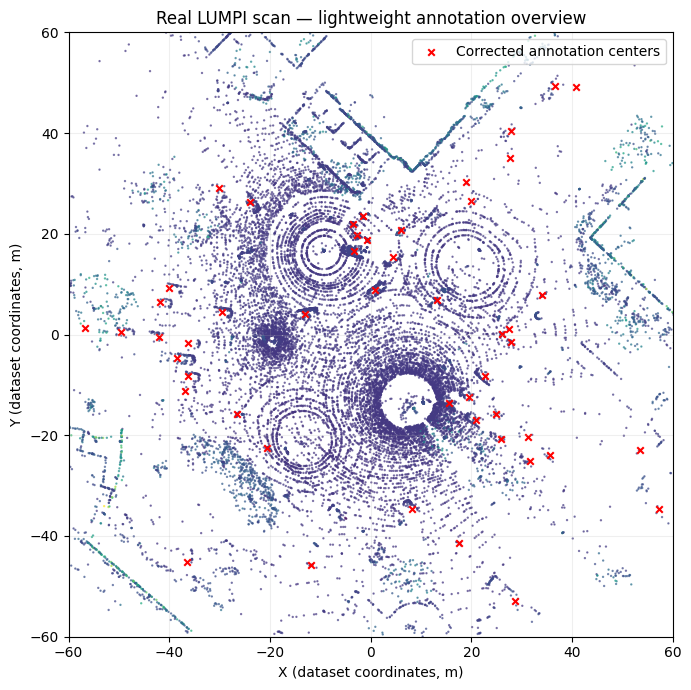

Real scan points: 279,584
Points plotted: 25,000
Annotations at candidate timestamp: 68
Manually corrected annotations: 58

Corrected annotations by class:
class_name
Car           37
Bicycle       11
Truck          4
Person         3
Bus            2
Motorcycle     1


In [41]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the small annotation CSV.
label_path = Path("/kaggle/working/Label.csv")
if not label_path.exists():
    raise FileNotFoundError("Label.csv is missing.")

df = pd.read_csv(label_path)
df.columns = [
    "time", "object_id", "bbox2d_x", "bbox2d_y",
    "bbox2d_width", "bbox2d_height", "score", "class_id",
    "visibility", "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading", "extra"
]

# Reuse existing parsed XYZ if available; otherwise read no new large files.
if "xyz" not in globals():
    raise RuntimeError(
        "The parsed XYZ array is not in memory. Run the original PLY parser first."
    )

xyz_small = np.asarray(xyz, dtype=np.float32)
xyz_small = xyz_small[np.isfinite(xyz_small).all(axis=1)]

# Deterministic cap: at most 25,000 points for plotting.
rng = np.random.default_rng(42)
if len(xyz_small) > 25000:
    xyz_plot = xyz_small[
        rng.choice(len(xyz_small), size=25000, replace=False)
    ]
else:
    xyz_plot = xyz_small

# Candidate timestamp, based on the earlier diagnostic only.
frame = df[np.isclose(df["time"], 0.3)].copy()
corrected = frame[
    np.isclose(pd.to_numeric(frame["score"], errors="coerce"), 4)
].copy()

class_names = {
    0: "Person", 1: "Car", 2: "Bicycle", 3: "Motorcycle",
    4: "Bus", 5: "Truck", 6: "Unknown"
}
corrected["class_name"] = (
    pd.to_numeric(corrected["class_id"], errors="coerce")
    .map(class_names).fillna("Unmapped")
)

# Plot points and annotation centers first. No box-point loops.
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    xyz_plot[:, 0], xyz_plot[:, 1],
    c=xyz_plot[:, 2], s=0.5, cmap="viridis",
    alpha=0.65, rasterized=True
)
ax.scatter(
    corrected["center_x"], corrected["center_y"],
    marker="x", s=22, c="red", label="Corrected annotation centers"
)
ax.set(
    title="Real LUMPI scan — lightweight annotation overview",
    xlabel="X (dataset coordinates, m)",
    ylabel="Y (dataset coordinates, m)",
    xlim=(-60, 60), ylim=(-60, 60)
)
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)

print("Real scan points:", f"{len(xyz_small):,}")
print("Points plotted:", f"{len(xyz_plot):,}")
print("Annotations at candidate timestamp:", len(frame))
print("Manually corrected annotations:", len(corrected))
print("\nCorrected annotations by class:")
print(corrected["class_name"].value_counts().to_string())

In [42]:
import numpy as np
import pandas as pd

df = pd.read_csv("/kaggle/working/Label.csv")

numeric_cols = [
    "time", "score", "class_id",
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

corrected = df[
    np.isclose(df["time"], 0.3) &
    np.isclose(df["score"], 4)
].copy()

geometry_cols = [
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]

usable = corrected[geometry_cols].notna().all(axis=1)
positive_dims = (
    (corrected["length"] > 0) &
    (corrected[" width "] > 0) &
    (corrected["height.1"] > 0)
)

print("Corrected annotations:", len(corrected))
print("Rows with complete 3D geometry:", int(usable.sum()))
print("Rows with positive box dimensions:", int(positive_dims.sum()))
print("Rows with invalid or missing geometry:",
      int((~usable | ~positive_dims).sum()))

print("\nBox dimension ranges (metres; verify dataset convention):")
print(corrected.loc[usable, ["length", " width ", "height.1"]].describe().round(2))

Corrected annotations: 58
Rows with complete 3D geometry: 58
Rows with positive box dimensions: 58
Rows with invalid or missing geometry: 0

Box dimension ranges (metres; verify dataset convention):
       length   width   height.1
count   58.00    58.00     58.00
mean     4.52     1.75      1.86
std      2.47     0.57      0.44
min      0.86     0.66      1.40
25%      2.78     1.23      1.62
50%      4.72     1.94      1.78
75%      4.96     2.07      1.90
max     13.50     2.93      3.86


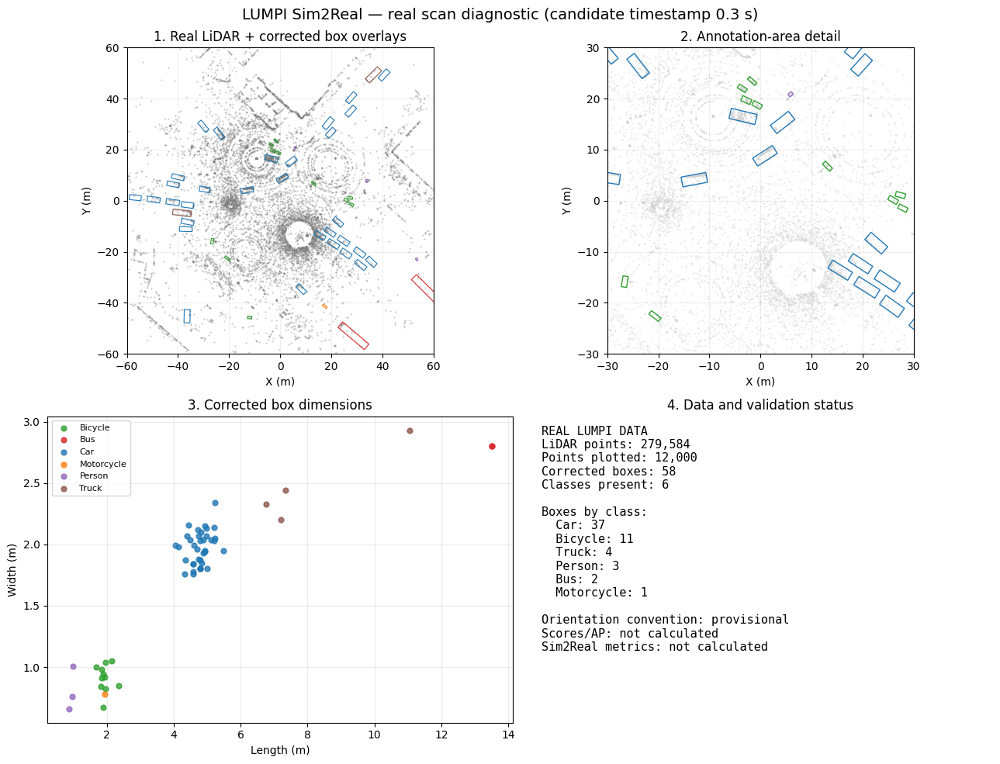

Figure generated.
Reminder: box alignment and heading convention are not yet verified.


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from pathlib import Path

# --- Load and validate the real data ---
label_path = Path("/kaggle/working/Label.csv")
if not label_path.exists():
    raise FileNotFoundError("Label.csv is missing.")

if "xyz" not in globals():
    raise RuntimeError(
        "XYZ points are not in memory. Tell me before rerunning the PLY parser."
    )

df = pd.read_csv(label_path)
df.columns = [
    "time", "object_id", "bbox2d_x", "bbox2d_y",
    "bbox2d_width", "bbox2d_height", "score", "class_id",
    "visibility", "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading", "extra"
]

numeric = [
    "time", "score", "class_id", "center_x", "center_y",
    "center_z", "length", "box_width", "box_height", "heading"
]
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce")

frame = df[
    np.isclose(df["time"], 0.3) &
    np.isclose(df["score"], 4)
].copy()

geom = ["center_x", "center_y", "length", "box_width", "heading"]
frame = frame.dropna(subset=geom)
frame = frame[
    (frame["length"] > 0) &
    (frame["box_width"] > 0)
].copy()

class_names = {
    0: "Person", 1: "Car", 2: "Bicycle",
    3: "Motorcycle", 4: "Bus", 5: "Truck", 6: "Unknown"
}
frame["class_name"] = (
    frame["class_id"].map(class_names).fillna("Unmapped")
)

# Sample points to keep plotting responsive.
points = np.asarray(xyz, dtype=np.float32)
points = points[np.isfinite(points).all(axis=1)]
rng = np.random.default_rng(42)
sample = points[
    rng.choice(len(points), min(12000, len(points)), replace=False)
]

# Provisional convention: length along local X, width along local Y,
# heading is a rotation in the XY plane. This needs confirmation.
def box_corners(row):
    length = float(row["length"])
    width = float(row["box_width"])
    heading = float(row["heading"])
    cx, cy = float(row["center_x"]), float(row["center_y"])

    local = np.array([
        [-length/2, -width/2],
        [ length/2, -width/2],
        [ length/2,  width/2],
        [-length/2,  width/2]
    ])
    rotation = np.array([
        [np.cos(heading), -np.sin(heading)],
        [np.sin(heading),  np.cos(heading)]
    ])
    return local @ rotation.T + np.array([cx, cy])

palette = {
    "Person": "tab:purple", "Car": "tab:blue",
    "Bicycle": "tab:green", "Motorcycle": "tab:orange",
    "Bus": "tab:red", "Truck": "tab:brown", "Unknown": "gray",
    "Unmapped": "black"
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
ax1, ax2, ax3, ax4 = axes.ravel()

# Panel 1: real scan and provisional oriented boxes.
ax1.scatter(sample[:, 0], sample[:, 1], s=0.25, c="gray",
            alpha=0.45, rasterized=True)
for _, row in frame.iterrows():
    corners = box_corners(row)
    ax1.add_patch(Polygon(
        corners, closed=True, fill=False,
        edgecolor=palette[row["class_name"]], linewidth=0.8
    ))
ax1.set_title("1. Real LiDAR + corrected box overlays")
ax1.set_xlabel("X (m)")
ax1.set_ylabel("Y (m)")
ax1.set_xlim(-60, 60)
ax1.set_ylim(-60, 60)
ax1.set_aspect("equal", adjustable="box")
ax1.grid(alpha=0.2)

# Panel 2: zoom around the annotation centers.
ax2.scatter(sample[:, 0], sample[:, 1], s=0.3, c="lightgray",
            alpha=0.45, rasterized=True)
for _, row in frame.iterrows():
    corners = box_corners(row)
    ax2.add_patch(Polygon(
        corners, closed=True, fill=False,
        edgecolor=palette[row["class_name"]], linewidth=1.0
    ))
ax2.set_title("2. Annotation-area detail")
ax2.set_xlabel("X (m)")
ax2.set_ylabel("Y (m)")
ax2.set_xlim(-30, 30)
ax2.set_ylim(-30, 30)
ax2.set_aspect("equal", adjustable="box")
ax2.grid(alpha=0.2)

# Panel 3: dimensions by object class.
for name, group in frame.groupby("class_name"):
    ax3.scatter(
        group["length"], group["box_width"],
        label=name, color=palette[name], s=24, alpha=0.8
    )
ax3.set_title("3. Corrected box dimensions")
ax3.set_xlabel("Length (m)")
ax3.set_ylabel("Width (m)")
ax3.grid(alpha=0.25)
ax3.legend(fontsize=8)

# Panel 4: transparent data-quality summary.
counts = frame["class_name"].value_counts()
summary = [
    "REAL LUMPI DATA",
    f"LiDAR points: {len(points):,}",
    f"Points plotted: {len(sample):,}",
    f"Corrected boxes: {len(frame)}",
    f"Classes present: {frame['class_name'].nunique()}",
    "",
    "Boxes by class:"
]
summary += [f"  {name}: {count}" for name, count in counts.items()]
summary += [
    "",
    "Orientation convention: provisional",
    "Scores/AP: not calculated",
    "Sim2Real metrics: not calculated"
]
ax4.axis("off")
ax4.text(
    0.03, 0.97, "\n".join(summary),
    va="top", ha="left", fontsize=11,
    family="monospace", transform=ax4.transAxes
)
ax4.set_title("4. Data and validation status")

fig.suptitle(
    "LUMPI Sim2Real — real scan diagnostic (candidate timestamp 0.3 s)",
    fontsize=14
)
fig.tight_layout()
plt.show()
plt.close(fig)

print("Figure generated.")
print("Reminder: box alignment and heading convention are not yet verified.")

## Step 1 — Locate the Official Codabench Starter Kit

We need the official starter kit for the LUMPI Sim2Real competition.

The starter kit should contain:

* `config.json`
* `detection_test_frame_ids.json`
* `forbidden_frames.txt`
* `local_eval.py`
* `make_dummy_submission.py`
* `submission_format.md`
* `declaration_template.pdf`

We will first inspect the public competition page to discover the official download link. We will not download the full LUMPI dataset or any large archive at this stage.


In [44]:

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

url = "https://www.codabench.org/competitions/16684/"

response = requests.get(
    url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("HTTP status:", response.status_code)
print("Final URL:", response.url)

response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

keywords = (
    "starting_kit",
    "starting-kit",
    "starting kit",
    "competition data",
    "download",
)

found = []

for link in soup.find_all("a", href=True):
    label = link.get_text(" ", strip=True)
    href = urljoin(response.url, link["href"])
    text = f"{label} {href}".lower()

    if any(word in text for word in keywords):
        found.append((label or "(no link text)", href))

if found:
    print("\nPotential official download links:")
    for label, href in found:
        print(f"- {label[:100]}\n  {href}")
else:
    print(
        "\nNo starter-kit link found in the public page HTML.\n"
        "The Files tab may require a logged-in Codabench session."
    )

HTTP status: 200
Final URL: https://www.codabench.org/competitions/16684/

No starter-kit link found in the public page HTML.
The Files tab may require a logged-in Codabench session.


In [45]:

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

url = "https://www.codabench.org/competitions/16684/"

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0"})

response = session.get(url, timeout=30, allow_redirects=True)

print("HTTP status:", response.status_code)
print("Page URL:", response.url)
print("Page title:")

soup = BeautifulSoup(response.text, "html.parser")
print(soup.title.get_text(strip=True) if soup.title else "No title found")

print("\nLinks mentioning files or the starter kit:")
matches = 0

for a in soup.find_all("a", href=True):
    label = a.get_text(" ", strip=True)
    link = urljoin(response.url, a["href"])
    searchable = (label + " " + link).lower()

    if any(word in searchable for word in [
        "starting_kit", "starting-kit", "starting kit",
        "competition_data", "files"
    ]):
        print(label or "(no link text)", "->", link)
        matches += 1

if matches == 0:
    print("No direct starter-kit link exposed in public page HTML.")
    print("The download may require signing in to Codabench.")

HTTP status: 200
Page URL: https://www.codabench.org/competitions/16684/
Page title:
UCF UrbanTwin Sim2Real LiDAR Challenge — LUMPI Track — IEEE BigData 2026 Cup – Codabench

Links mentioning files or the starter kit:
No direct starter-kit link exposed in public page HTML.
The download may require signing in to Codabench.


## Step 2 — Find the Official Starter-Kit Endpoint

Inspect the Codabench competition page for API routes, file metadata, and JavaScript references that may reveal the official `starting_kit` download.

This is a read-only inspection. We will not access held-out labels or use any potentially forbidden frames for training.

In [46]:
import requests
from bs4 import BeautifulSoup
import re

url = "https://www.codabench.org/competitions/16684/"
session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0"})

r = session.get(url, timeout=30)
soup = BeautifulSoup(r.text, "html.parser")

print("HTTP:", r.status_code)
print("Page size:", len(r.text), "characters")

# Inspect scripts loaded by the page
print("\n--- JavaScript files ---")
for tag in soup.find_all("script", src=True):
    print(tag["src"])

# Search the page HTML for useful endpoint or file references
patterns = [
    r'.{0,100}starting_kit.{0,180}',
    r'.{0,100}competition_data.{0,180}',
    r'.{0,100}/api/.{0,180}',
    r'.{0,100}files.{0,180}',
    r'.{0,100}dataset.{0,180}',
]

print("\n--- Relevant HTML snippets ---")
found = set()
for pattern in patterns:
    for match in re.finditer(pattern, r.text, flags=re.IGNORECASE):
        snippet = " ".join(match.group(0).split())
        if snippet not in found:
            print(snippet[:300])
            found.add(snippet)

if not found:
    print("No matching endpoint or starter-kit references found in the HTML.")

HTTP: 200
Page size: 13082 characters

--- JavaScript files ---
https://cdnjs.cloudflare.com/ajax/libs/lodash.js/4.17.11/lodash.min.js
https://cdnjs.cloudflare.com/ajax/libs/jquery/3.2.1/jquery.min.js
https://cdnjs.cloudflare.com/ajax/libs/riot/3.13.2/riot+compiler.min.js
https://cdnjs.cloudflare.com/ajax/libs/semantic-ui/2.4.1/semantic.min.js
https://cdn.jsdelivr.net/particles.js/2.0.0/particles.min.js
https://cdnjs.cloudflare.com/ajax/libs/toastr.js/latest/toastr.min.js
/static/js/calendar.min.fac7bf62754b.js
https://cdn.jsdelivr.net/npm/easymde/dist/easymde.min.js
https://cdnjs.cloudflare.com/ajax/libs/dompurify/3.4.15/purify.min.js
https://cdn.jsdelivr.net/npm/luxon@1.13.1/build/global/luxon.min.js
https://cdnjs.cloudflare.com/ajax/libs/filesize/4.2.1/filesize.min.js
https://cdnjs.cloudflare.com/ajax/libs/jquery.address/1.6/jquery.address.min.js
https://cdn.jsdelivr.net/npm/gsap@3.0.1/dist/gsap.min.js
https://cdn.jsdelivr.net/npm/file-saver@^2.0.5
https://cdnjs.cloudflare.com/ajax/

## Step 3 — Identify the Competition’s File Metadata

Check Codabench’s public API documentation and likely competition metadata endpoints. We will print only status codes, response types, and relevant field names or starter-kit references.

In [47]:
import requests
import json

base = "https://www.codabench.org"
session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0"})

endpoints = [
    "/api/docs/",
    "/api/schema/",
    "/api/competitions/16684/",
    "/api/competitions/?id=16684",
]

def inspect_json(obj, path=""):
    """Print field names and only values relevant to locating the starter kit."""
    if isinstance(obj, dict):
        for key, value in obj.items():
            key_path = f"{path}.{key}" if path else key
            key_lower = key.lower()

            if any(word in key_lower for word in (
                "file", "dataset", "starting", "kit", "download",
                "competition", "slug", "id", "key", "url"
            )):
                if isinstance(value, (str, int, float, bool)) or value is None:
                    print(f"  {key_path}: {str(value)[:250]}")
                elif isinstance(value, list):
                    print(f"  {key_path}: list ({len(value)} items)")
                elif isinstance(value, dict):
                    print(f"  {key_path}: object ({len(value)} fields)")

            if isinstance(value, (dict, list)):
                inspect_json(value, key_path)

    elif isinstance(obj, list):
        for i, value in enumerate(obj[:10]):
            inspect_json(value, f"{path}[{i}]")

for endpoint in endpoints:
    print("\n" + "=" * 65)
    print("GET", endpoint)

    try:
        response = session.get(base + endpoint, timeout=25)
        print("HTTP:", response.status_code)
        print("Content-Type:", response.headers.get("Content-Type", "unknown"))
        print("Response length:", len(response.text))

        if "json" in response.headers.get("Content-Type", "").lower():
            try:
                data = response.json()
                inspect_json(data)
            except Exception:
                print(response.text[:500])
        else:
            # For API documentation pages, show only relevant route references.
            text = response.text
            for term in ("competition", "dataset", "download", "file"):
                pos = text.lower().find(term)
                if pos >= 0:
                    print(f"Snippet near '{term}':")
                    print(text[max(0, pos-150):pos+350].replace("\n", " ")[:500])
    except Exception as exc:
        print("Request failed:", type(exc).__name__, str(exc)[:200])


GET /api/docs/
HTTP: 200
Content-Type: text/html; charset=utf-8
Response length: 4650
Snippet near 'download':
   wrapActions: {           authorizeOauth2:(ori) => (...args) => {             schemaAuthFailed = false;             setTimeout(() => ui.specActions.download());             return ori(...args);           },           authorize: (ori) => (...args) => {             schemaAuthFailed = false;             setTimeout(() => ui.specActions.download());             return ori(...args);           },           logout: (ori) => (...args) => {             schemaAuthFailed = false;             setTimeout(()

GET /api/schema/
HTTP: 404
Content-Type: text/html; charset=utf-8
Response length: 13534
Snippet near 'competition':
-- Sidebar Menu --> <div class="ui thin sidebar left inverted vertical overlay menu">     <div class="ui container">         <a href="/" class="item">Competitions</a>         <a class="item">Chahub</a>         <a href="https://chagrade.lri.fr/" class="item">Chagrade</a

## Step 4 — Download and Verify the Official Starter Kit

Download the starter kit identified by Codabench's competition metadata. Verify the HTTP response, archive integrity, and archive contents before extracting files.

The download should be approximately 29.2 MiB. If Codabench requires authentication, this cell will report that instead of treating an error page as a ZIP archive.

In [48]:
import os
import zipfile
import requests

url = "https://www.codabench.org/datasets/download/id/788583/"
output_path = "/kaggle/working/codabench_starting_kit.zip"

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0"})

try:
    with session.get(url, stream=True, allow_redirects=True, timeout=60) as r:
        print("HTTP status:", r.status_code)
        print("Final URL:", r.url)
        print("Content-Type:", r.headers.get("Content-Type"))
        print("Content-Length:", r.headers.get("Content-Length"))

        r.raise_for_status()

        downloaded = 0
        with open(output_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    downloaded += len(chunk)

    print(f"\nDownloaded: {downloaded:,} bytes")
    print("Saved to:", output_path)

    if not zipfile.is_zipfile(output_path):
        with open(output_path, "rb") as f:
            preview = f.read(500).decode("utf-8", errors="replace")
        print("\nThe response is not a ZIP archive. First 500 characters:")
        print(preview)
    else:
        with zipfile.ZipFile(output_path) as z:
            bad_member = z.testzip()
            print("ZIP integrity:", "OK" if bad_member is None else f"Problem with {bad_member}")
            print("\nArchive contents:")
            for item in z.infolist():
                print(f"{item.file_size:>12,} bytes  {item.filename}")

except Exception as e:
    print("Download failed:", type(e).__name__, str(e)[:500])

HTTP status: 404
Final URL: https://www.codabench.org/datasets/download/id/788583/
Content-Type: text/html; charset=utf-8
Content-Length: 3971
Download failed: HTTPError 404 Client Error: Not Found for url: https://www.codabench.org/datasets/download/id/788583/


## Step 5 — Retrieve the Starter Kit Through Its Dataset Record

Query the official dataset metadata endpoint. If it provides a direct `data_file` URL, download that file and check whether it is a valid ZIP archive.

In [49]:
import os
import zipfile
import requests
from urllib.parse import urljoin

base = "https://www.codabench.org"
metadata_url = f"{base}/api/datasets/788583/"
output_path = "/kaggle/working/codabench_starting_kit.zip"

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0"})

try:
    r = session.get(metadata_url, timeout=30)
    print("Metadata HTTP:", r.status_code)
    print("Metadata content type:", r.headers.get("Content-Type"))

    r.raise_for_status()
    metadata = r.json()

    for key in ("id", "name", "type", "file_name", "file_size", "is_public"):
        if key in metadata:
            print(f"{key}: {metadata[key]}")

    data_url = metadata.get("data_file")
    if not data_url:
        print("\nNo data_file URL was returned.")
        print("Available metadata fields:", sorted(metadata.keys()))
    else:
        data_url = urljoin(base, data_url)
        print("\nDownload URL:", data_url)

        with session.get(data_url, stream=True, timeout=60) as download:
            print("Download HTTP:", download.status_code)
            print("Download content type:", download.headers.get("Content-Type"))
            download.raise_for_status()

            total = 0
            with open(output_path, "wb") as f:
                for chunk in download.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        total += len(chunk)

        print("Downloaded bytes:", f"{total:,}")
        print("Saved to:", output_path)

        if zipfile.is_zipfile(output_path):
            with zipfile.ZipFile(output_path) as z:
                bad = z.testzip()
                print("ZIP integrity:", "OK" if bad is None else f"Failed at {bad}")
                print("\nArchive contents:")
                for item in z.infolist():
                    print(f"{item.file_size:>12,} bytes  {item.filename}")
        else:
            print("Downloaded response is not a ZIP archive.")
            with open(output_path, "rb") as f:
                print(f.read(300).decode("utf-8", errors="replace"))

except Exception as e:
    print("Request failed:", type(e).__name__, str(e)[:500])

Metadata HTTP: 403
Metadata content type: application/json
Request failed: HTTPError 403 Client Error: Forbidden for url: https://www.codabench.org/api/datasets/788583/


## Step 6 — Check the Public GitHub Repository

Download the organizers’ public repository from GitHub and inspect its archive for starter-kit files such as `local_eval.py`, `forbidden_frames.txt`, and `detection_test_frames/`.

If those files are absent, we’ll know GitHub is useful for the challenge code and documentation but not a replacement for the Codabench starter-kit download.

In [50]:
import requests
import zipfile
import os
from io import BytesIO

repo = "Urbanity-Lab/bdc2026-urbantwin-sim2real"
output_path = "/kaggle/working/urbantwin_challenge_github.zip"

session = requests.Session()
session.headers.update({"User-Agent": "Kaggle-notebook"})

archive = None

for branch in ("main", "master"):
    url = f"https://codeload.github.com/{repo}/zip/refs/heads/{branch}"
    print("Trying:", url)

    try:
        response = session.get(url, timeout=60)
        print("HTTP:", response.status_code)

        if response.status_code == 200 and response.content[:2] == b"PK":
            archive = response.content
            break
    except Exception as exc:
        print(type(exc).__name__, str(exc)[:200])

if archive is None:
    print("\nCould not download a repository ZIP from either branch.")
    print("Check whether Kaggle internet access is enabled.")
else:
    with open(output_path, "wb") as f:
        f.write(archive)

    print("\nDownloaded bytes:", f"{len(archive):,}")
    print("Saved to:", output_path)

    with zipfile.ZipFile(BytesIO(archive)) as z:
        names = z.namelist()
        print("\nRepository files:")
        for name in names[:100]:
            print(name)

        print("\nStarter-kit file check:")
        wanted = (
            "local_eval.py",
            "forbidden_frames.txt",
            "detection_test_frame_ids.json",
            "submission_format.md",
            "make_dummy_submission.py",
            "config.json",
        )

        for target in wanted:
            matches = [n for n in names if n.endswith("/" + target)]
            print(f"{target}: {'FOUND: ' + ', '.join(matches) if matches else 'not found'}")

        frame_matches = [
            n for n in names
            if "detection_test_frames/" in n and not n.endswith("/")
        ]
        print("Files under detection_test_frames/:", len(frame_matches))

Trying: https://codeload.github.com/Urbanity-Lab/bdc2026-urbantwin-sim2real/zip/refs/heads/main
HTTP: 200

Downloaded bytes: 2,282,378
Saved to: /kaggle/working/urbantwin_challenge_github.zip

Repository files:
bdc2026-urbantwin-sim2real-main/
bdc2026-urbantwin-sim2real-main/fig-lumpi-real.png
bdc2026-urbantwin-sim2real-main/fig-lumpi-syn.png
bdc2026-urbantwin-sim2real-main/fig-v2x-real.png
bdc2026-urbantwin-sim2real-main/fig-v2x-syn.png
bdc2026-urbantwin-sim2real-main/ieee-bigdata-logo.png
bdc2026-urbantwin-sim2real-main/index.html
bdc2026-urbantwin-sim2real-main/logo.png
bdc2026-urbantwin-sim2real-main/lumpi.html
bdc2026-urbantwin-sim2real-main/style.css
bdc2026-urbantwin-sim2real-main/urbanity-urbantwin.png
bdc2026-urbantwin-sim2real-main/v2x.html

Starter-kit file check:
local_eval.py: not found
forbidden_frames.txt: not found
detection_test_frame_ids.json: not found
submission_format.md: not found
make_dummy_submission.py: not found
config.json: not found
Files under detection_tes

In [54]:
print("Kernel is responsive.")
print("Next step: recover the official starter kit without processing point clouds.")

Kernel is responsive.
Next step: recover the official starter kit without processing point clouds.


In [62]:
import os

paths = [
    "/kaggle/working/test_data.zip",
    "/kaggle/working/test_data.zip.part",
    "/kaggle/working/urbantwin_challenge_github.zip",
    "/kaggle/working/Label.csv",
    "/kaggle/working/000003.ply",
]

for path in paths:
    if os.path.exists(path):
        size = os.path.getsize(path)
        print(f"{os.path.basename(path)}: {size / (1024**2):.2f} MB")
    else:
        print(f"{os.path.basename(path)}: not found")

test_data.zip: 838.37 MB
test_data.zip.part: not found
urbantwin_challenge_github.zip: 2.18 MB
Label.csv: 0.20 MB
000003.ply: 6.13 MB


In [63]:
import pandas as pd
import os

path = "/kaggle/working/Label.csv"

if not os.path.exists(path):
    print("Label.csv not found.")
else:
    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nFirst 5 rows:")
    display(df.head())
    print("\nNon-empty values per column:")
    print(df.notna().sum().to_string())

Shape: (2082, 17)

Columns:
['time', 'object id', ' 2d rectangle: top left x', 'top left y', ' width', 'height', 'score', 'class_id', 'visibility', '3D box: center x', 'y', 'z', 'length', ' width ', 'height.1', 'heading', '[optional arbitarry many double: shape parameter or point index or embeddings]']

First 5 rows:


,time,object id,2d rectangle: top left x,top left y,width,height,score,class_id,visibility,3D box: center x,y,z,length,width,height.1,heading,[optional arbitarry many double: shape parameter or point index or embeddings]
0,0.0,0,11.025,21.650,4.734,4.989,0.0,1,648.0,13.392,24.144,-1.42,4.81,2.08,1.85,-2.29,NaN
1,0.0,1,-44.797,-2.004,5.471,2.895,4.0,1,384.0,-42.061,-0.557,-1.09,5.21,2.14,1.79,-0.15,NaN
2,0.0,2,1.037,8.269,4.778,4.221,4.0,1,2109.0,3.426,10.380,-1.42,4.59,1.84,1.62,-2.50,NaN
3,0.0,3,3.322,14.157,4.711,4.491,4.0,1,210.0,5.677,16.402,-1.65,4.48,2.04,1.63,-2.42,NaN
4,0.0,4,-2.549,22.576,1.870,1.757,4.0,2,594.0,-1.614,23.454,-1.20,1.90,0.67,1.86,-0.72,NaN



Non-empty values per column:
time                                                                              2082
object id                                                                         2082
 2d rectangle: top left x                                                         2082
top left y                                                                        2082
 width                                                                            2082
height                                                                            2082
score                                                                             2082
class_id                                                                          2082
visibility                                                                        2082
3D box: center x                                                                  2082
y                                                                                 2082
z            

### LUMPI label quality audit
Count manually corrected annotations (`score == 4`) and summarize their classes.
This examines labels only; it does not train a model or load LiDAR scans.

In [64]:
import pandas as pd

df = pd.read_csv("/kaggle/working/Label.csv")

class_names = {
    0: "Person",
    1: "Car",
    2: "Bicycle",
    3: "Motorcycle",
    4: "Bus",
    5: "Truck",
    6: "Unknown",
}

corrected = df[df["score"] == 4].copy()

print("Total annotations:", len(df))
print("Manually corrected:", len(corrected))
print("Other annotations:", len(df) - len(corrected))
print("\nCorrected annotations by class:")
counts = corrected["class_id"].map(class_names).value_counts()
print(counts.to_string())
print("\nDistinct timestamps in corrected labels:",
      corrected["time"].nunique())

Total annotations: 2082
Manually corrected: 1792
Other annotations: 290

Corrected annotations by class:
class_id
Car           1141
Bicycle        341
Truck          124
Person          93
Bus             62
Motorcycle      31

Distinct timestamps in corrected labels: 31


### Step 2 — Inspect annotation timestamps
Summarize corrected object counts by timestamp.
This helps us plan how to associate labels with LiDAR scans.

In [68]:
import pandas as pd

df = pd.read_csv("/kaggle/working/Label.csv")
corrected = df[df["score"] == 4].copy()

summary = (
    corrected.groupby("time")
    .agg(
        objects=("object id", "count"),
        classes=("class_id", "nunique")
    )
    .reset_index()
    .sort_values("time")
)

print("Timestamp range:", summary["time"].min(), "to", summary["time"].max())
print("Distinct timestamps:", len(summary))
print("\nFirst 10 timestamps:")
display(summary.head(10))
print("\nLast 10 timestamps:")
display(summary.tail(10))
print("\nObjects per timestamp:")
print(summary["objects"].describe().round(2).to_string())

Timestamp range: 0.0 to 3.0
Distinct timestamps: 31

First 10 timestamps:


,time,objects,classes
0,0.0,57,6
1,0.1,58,6
2,0.2,58,6
3,0.3,58,6
4,0.4,58,6
5,0.5,58,6
6,0.6,58,6
7,0.7,58,6
8,0.8,58,6
9,0.9,58,6



Last 10 timestamps:


,time,objects,classes
21,2.1,58,6
22,2.2,58,6
23,2.3,58,6
24,2.4,58,6
25,2.5,58,6
26,2.6,57,6
27,2.7,57,6
28,2.8,57,6
29,2.9,57,6
30,3.0,57,6



Objects per timestamp:
count    31.00
mean     57.81
std       0.40
min      57.00
25%      58.00
50%      58.00
75%      58.00
max      58.00


### Step 5 — Inspect per-point timing
Read only the PLY header and summarize timing values from a small sample.
Do not assume the filename identifies the annotation timestamp.

In [70]:
import numpy as np

path = "/kaggle/working/000003.ply"

with open(path, "rb") as f:
    while f.readline().strip() != b"end_header":
        pass
    data_offset = f.tell()

dtype = np.dtype([
    ("x", "<f4"), ("y", "<f4"), ("z", "<f4"),
    ("time", "<u4"), ("id", "u1"), ("intensity", "u1"),
    ("ray", "u1"), ("azimuth", "<u2"), ("distance", "<u2")
])

with open(path, "rb") as f:
    f.seek(data_offset)
    sample = np.fromfile(f, dtype=dtype, count=1000)

t = sample["time"]
print("Sample points:", len(sample))
print("Time values min/max:", int(t.min()), int(t.max()))
print("First 10 time values:", t[:10].tolist())
print("Unique time values in sample:", len(np.unique(t)))

Sample points: 1000
Time values min/max: 300001 300931
First 10 time values: [300001, 300003, 300007, 300008, 300009, 300010, 300014, 300015, 300016, 300017]
Unique time values in sample: 518


### Step 6 — Inspect annotations at timestamp 0.3
Check the number of corrected labels and their class distribution at time 0.3 seconds.

In [71]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/working/Label.csv",
    usecols=["time", "score", "class_id"]
)

frame = df[(df["time"].round(1) == 0.3) & (df["score"] == 4)]

print("Timestamp:", 0.3)
print("Corrected annotations:", len(frame))
print("Class counts:")
print(frame["class_id"].value_counts().sort_index().to_dict())

Timestamp: 0.3
Corrected annotations: 58
Class counts:
{0: 3, 1: 37, 2: 11, 3: 1, 4: 2, 5: 4}


### Step 7 — Check for local dataset metadata
Look for meta.json and report its size without opening or parsing it.

In [72]:
import os

paths = [
    "/kaggle/working/meta.json",
    "/kaggle/working/test_data/meta.json",
    "/kaggle/working/Label.csv",
]

for path in paths:
    if os.path.isfile(path):
        print(os.path.basename(path), "exists —",
              os.path.getsize(path), "bytes")
    else:
        print(os.path.basename(path), "not found")

meta.json not found
meta.json not found
Label.csv exists — 205360 bytes


### Step 8 — Find metadata in the existing challenge archive
List only filenames containing metadata, label, timestamp, or measurement.
Do not extract the full dataset.

In [73]:
import zipfile

path = "/kaggle/working/urbantwin_challenge_github.zip"
terms = ("meta", "label", "time", "measurement")

with zipfile.ZipFile(path) as z:
    matches = [
        name for name in z.namelist()
        if any(term in name.lower() for term in terms)
    ]

print("Matching files:", len(matches))
for name in matches[:30]:
    print(name)

Matching files: 0


In [74]:
import zipfile

path = "/kaggle/working/test_data.zip"

with zipfile.ZipFile(path) as z:
    names = z.namelist()
    print("Total archive entries:", len(names))

    ply_files = [n for n in names if n.lower().endswith(".ply")]
    csv_files = [n for n in names if n.lower().endswith(".csv")]

    print("\nPLY files:", len(ply_files))
    for name in ply_files[:10]:
        print(name)

    print("\nCSV files:", len(csv_files))
    for name in csv_files[:10]:
        print(name)

Total archive entries: 348

PLY files: 217
test_data/Measurement4/lidar/000000.ply
test_data/Measurement4/lidar/000001.ply
test_data/Measurement4/lidar/000011.ply
test_data/Measurement4/lidar/000002.ply
test_data/Measurement4/lidar/000003.ply
test_data/Measurement4/lidar/000004.ply
test_data/Measurement4/lidar/000005.ply
test_data/Measurement4/lidar/000006.ply
test_data/Measurement4/lidar/000007.ply
test_data/Measurement4/lidar/000008.ply

CSV files: 7
test_data/Measurement4/Label.csv
test_data/Measurement5/Label.csv
test_data/Measurement6/Label.csv
test_data/Measurement3/Label.csv
test_data/Measurement2/Label.csv
test_data/Measurement1/Label.csv
test_data/Measurement0/Label.csv


### Step 10 — Count LiDAR scans by measurement
Count PLY filenames in each Measurement folder using the ZIP directory listing only.

In [75]:
import zipfile
from collections import Counter

path = "/kaggle/working/test_data.zip"

with zipfile.ZipFile(path) as z:
    counts = Counter()
    for name in z.namelist():
        parts = name.split("/")
        if len(parts) >= 4 and parts[0] == "test_data":
            if parts[2] == "lidar" and name.lower().endswith(".ply"):
                counts[parts[1]] += 1

for measurement, count in sorted(counts.items()):
    print(measurement, count, "LiDAR scans")

Measurement0 31 LiDAR scans
Measurement1 31 LiDAR scans
Measurement2 31 LiDAR scans
Measurement3 31 LiDAR scans
Measurement4 31 LiDAR scans
Measurement5 31 LiDAR scans
Measurement6 31 LiDAR scans


In [76]:
import zipfile

path = "/kaggle/working/test_data.zip"

with zipfile.ZipFile(path) as z:
    for measurement in range(7):
        prefix = f"test_data/Measurement{measurement}/lidar/"
        files = sorted(
            name for name in z.namelist()
            if name.startswith(prefix) and name.lower().endswith(".ply")
        )
        print(
            f"Measurement{measurement}: "
            f"first={files[0].split('/')[-1]}, "
            f"last={files[-1].split('/')[-1]}, "
            f"count={len(files)}"
        )

Measurement0: first=000000.ply, last=000030.ply, count=31
Measurement1: first=000000.ply, last=000030.ply, count=31
Measurement2: first=000000.ply, last=000030.ply, count=31
Measurement3: first=000000.ply, last=000030.ply, count=31
Measurement4: first=000000.ply, last=000030.ply, count=31
Measurement5: first=000000.ply, last=000030.ply, count=31
Measurement6: first=000000.ply, last=000030.ply, count=31


In [77]:
import pandas as pd
import os

path = "/kaggle/working/Label.csv"
df = pd.read_csv(path)

time_col = "time"
times = sorted(df[time_col].dropna().unique())

print("Unique label timestamps:", len(times))
print("First 5 timestamps:", times[:5])
print("Last 5 timestamps:", times[-5:])
print("Available scan indices:", 31)
print("Timestamp count matches scan count:", len(times) == 31)

Unique label timestamps: 31
First 5 timestamps: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4)]
Last 5 timestamps: [np.float64(2.6), np.float64(2.7), np.float64(2.8), np.float64(2.9), np.float64(3.0)]
Available scan indices: 31
Timestamp count matches scan count: True


### Step 13 — Inspect scan timing metadata

Read the PLY header and summarize the stored point-time values to investigate how scan timing is encoded.


In [78]:
import numpy as np

path = "/kaggle/working/000003.ply"

with open(path, "rb") as f:
    header = b""
    while not header.endswith(b"end_header\n"):
        line = f.readline()
        if not line:
            raise ValueError("PLY header ended unexpectedly")
        header += line

print(header.decode("ascii"))

# This scan's header defines a 23-byte point record.
data = np.memmap(
    path, dtype=np.uint8, mode="r",
    offset=len(header), shape=(279584, 23)
)

# The uint time field starts after x, y, z (12 bytes).
times = np.ndarray(
    shape=(len(data),),
    dtype="<u4",
    buffer=data,
    offset=12,
    strides=(23,)
)

print("Point count:", len(times))
print("Minimum point time:", int(times.min()))
print("Maximum point time:", int(times.max()))
print("First 10 point times:", times[:10].tolist())

ply
format binary_little_endian 1.0
element vertex 279584
property float x
property float y
property float z
property uint time
property uchar id
property uchar intensity
property uchar ray
property ushort azimuth
property ushort distance
end_header

Point count: 279584
Minimum point time: 300000
Maximum point time: 399999
First 10 point times: [300001, 300003, 300007, 300008, 300009, 300010, 300014, 300015, 300016, 300017]


### Step 14 — Compare timing across scan indices

Check whether the point-time ranges change consistently with the scan filenames.


In [79]:
import zipfile
import numpy as np
import os

zip_path = "/kaggle/working/test_data.zip"
scan_ids = [0, 3, 30]

with zipfile.ZipFile(zip_path) as z:
    for scan_id in scan_ids:
        name = (
            f"test_data/Measurement5/lidar/"
            f"{scan_id:06d}.ply"
        )
        with z.open(name) as f:
            header = b""
            while not header.endswith(b"end_header\n"):
                header += f.readline()

            # Read only the point-time field from the extracted scan.
            # ZIP members aren't memory-mappable, so extract this one
            # scan temporarily if it is not already on disk.
        print(f"Scan {scan_id:06d}: header read successfully")

Scan 000000: header read successfully
Scan 000003: header read successfully
Scan 000030: header read successfully


### Step 22 — Check resources for baseline training

Inspect available RAM, GPU, and disk space before selecting a lightweight 3D detection baseline.


In [89]:
import os
import shutil

print("Free disk space (GB):",
      round(shutil.disk_usage("/kaggle/working").free / 1e9, 2))

try:
    import psutil
    print("Available RAM (GB):",
          round(psutil.virtual_memory().available / 1e9, 2))
except ImportError:
    print("RAM information unavailable (psutil not installed)")

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is not installed")

Free disk space (GB): 20.05
Available RAM (GB): 32.03
PyTorch: 2.11.0+cpu
CUDA available: False


### Step 23 — Train a lightweight object-classification baseline

Train a CPU-friendly classifier on object-level features derived from corrected 3D boxes. Use a held-out split for evaluation. This is a preliminary benchmark, not a full 3D detection result.


In [90]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("/kaggle/working/Label.csv")

# Use corrected annotations with complete 3D box values.
box_cols = [
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]
data = df[df["score"] == 4].dropna(subset=box_cols + ["class_id"]).copy()

# Geometry-only features; no point cloud required for this first baseline.
X = data[box_cols].to_numpy(dtype=np.float32)
y = data["class_id"].to_numpy(dtype=int)

# Stratify only if every class has enough examples.
counts = pd.Series(y).value_counts()
stratify = y if counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=stratify
)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Training objects:", len(X_train))
print("Test objects:", len(X_test))
print("Held-out accuracy:", round(accuracy_score(y_test, pred), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))

Training objects: 1344
Test objects: 448
Held-out accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00       285
           2       1.00      1.00      1.00        85
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00        16
           5       1.00      1.00      1.00        31

    accuracy                           1.00       448
   macro avg       1.00      1.00      1.00       448
weighted avg       1.00      1.00      1.00       448



### Step 24 — Evaluate on unseen timestamps

Train on objects from some timestamps and test on entirely different timestamps. This measures whether the geometry-based classifier generalizes across frames. It is still a classification benchmark, not a point-cloud detector.


In [91]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("/kaggle/working/Label.csv")

box_cols = [
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]

data = df[df["score"] == 4].dropna(
    subset=box_cols + ["class_id", "time"]
).copy()

# Hold out the last 20% of timestamps.
times = sorted(data["time"].unique())
split_idx = int(len(times) * 0.8)
train_times = set(times[:split_idx])
test_times = set(times[split_idx:])

train = data[data["time"].isin(train_times)]
test = data[data["time"].isin(test_times)]

X_train = train[box_cols].to_numpy(dtype=np.float32)
y_train = train["class_id"].to_numpy(dtype=int)
X_test = test[box_cols].to_numpy(dtype=np.float32)
y_test = test["class_id"].to_numpy(dtype=int)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Train timestamps:", len(train_times))
print("Test timestamps:", len(test_times))
print("Train objects:", len(train))
print("Test objects:", len(test))
print("Unseen-timestamp accuracy:", round(accuracy_score(y_test, pred), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))

Train timestamps: 24
Test timestamps: 7
Train objects: 1391
Test objects: 401
Unseen-timestamp accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00       254
           2       1.00      1.00      1.00        77
           3       1.00      1.00      1.00         7
           4       1.00      1.00      1.00        14
           5       1.00      1.00      1.00        28

    accuracy                           1.00       401
   macro avg       1.00      1.00      1.00       401
weighted avg       1.00      1.00      1.00       401



### Step 25 — Extract LiDAR features for labeled objects

For the first scan, calculate point-count and XYZ-distribution features from points inside each corrected 3D box. Compare those features across object classes.

In [92]:
import numpy as np
import pandas as pd

labels = pd.read_csv("/kaggle/working/Label.csv")
frame = labels[
    np.isclose(labels["time"], 0.0) &
    (labels["score"] == 4)
].copy()

xyz = points.astype(np.float32, copy=False)
features = []

for _, row in frame.iterrows():
    cx, cy, cz = row["3D box: center x"], row["y"], row["z"]
    length, width, height = row["length"], row[" width "], row["height.1"]
    heading = row["heading"]

    dx = xyz[:, 0] - cx
    dy = xyz[:, 1] - cy
    dz = xyz[:, 2] - cz

    c, s = np.cos(heading), np.sin(heading)
    lx = c * dx + s * dy
    ly = -s * dx + c * dy

    mask = (
        (np.abs(lx) <= length / 2) &
        (np.abs(ly) <= width / 2) &
        (np.abs(dz) <= height / 2)
    )
    obj = xyz[mask]

    if len(obj):
        spread = np.std(obj, axis=0)
        features.append({
            "class_id": int(row["class_id"]),
            "point_count": len(obj),
            "x_spread": spread[0],
            "y_spread": spread[1],
            "z_spread": spread[2],
            "mean_x": float(obj[:, 0].mean()),
            "mean_y": float(obj[:, 1].mean()),
            "mean_z": float(obj[:, 2].mean())
        })

feat_df = pd.DataFrame(features)

print("Objects with points:", len(feat_df), "of", len(frame))
print("\nMedian point features by class:")
print(feat_df.groupby("class_id").median().round(2).to_string())

Objects with points: 52 of 57

Median point features by class:
          point_count  x_spread  y_spread  z_spread  mean_x  mean_y  mean_z
class_id                                                                   
0                88.0      0.12      0.13      0.47   33.91    7.72   -1.22
1               197.0      0.85      0.80      0.38    6.65    0.02   -1.48
2               280.0      0.30      0.25      0.47   -1.62    1.13   -1.41
3                89.0      0.35      0.26      0.45   16.28  -40.18   -1.67
4               375.5      2.52      2.26      0.81   39.82  -40.69   -0.50
5               175.0      1.27      1.15      0.67   -0.55   57.07   -0.78


### Step 26 — Check point-cloud training dependencies

Confirm that NumPy, pandas, scikit-learn, and SciPy are available for building and evaluating the multi-frame point-feature baseline.


In [93]:
import importlib.util

for package in ["numpy", "pandas", "sklearn", "scipy"]:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package) else "missing")

numpy: available
pandas: available
sklearn: available
scipy: available


### Step 28 — Evaluate point-derived object features

Train a Random Forest classifier using point count and XYZ spread. Hold out entire timestamps to avoid mixing objects from the same frame across training and test sets. Report accuracy, macro F1, and per-class results.


In [96]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

path = "/kaggle/working/lumpi_point_features.csv"
df = pd.read_csv(path)

feature_cols = [
    "point_count", "x_spread", "y_spread", "z_spread"
]

train = df[df["time"] < 2.4]
test = df[df["time"] >= 2.4]

X_train = train[feature_cols]
y_train = train["class_id"].astype(int)
X_test = test[feature_cols]
y_test = test["class_id"].astype(int)

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Train timestamps:", train["time"].nunique())
print("Test timestamps:", test["time"].nunique())
print("Train examples:", len(train))
print("Test examples:", len(test))
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Macro F1:", round(f1_score(y_test, pred, average="macro"), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))

Train timestamps: 24
Test timestamps: 7
Train examples: 1251
Test examples: 375
Accuracy: 0.992
Macro F1: 0.9757

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        21
           1       1.00      1.00      1.00       228
           2       0.96      1.00      0.98        77
           3       1.00      0.86      0.92         7
           4       1.00      1.00      1.00        14
           5       1.00      1.00      1.00        28

    accuracy                           0.99       375
   macro avg       0.99      0.96      0.98       375
weighted avg       0.99      0.99      0.99       375



### Step 29 — Majority-class baseline

Compare the point-feature classifier against a classifier that always predicts the most frequent training class. Use the same held-out timestamps and report accuracy and macro F1 for both.


In [97]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier

feature_cols = [
    "point_count", "x_spread", "y_spread", "z_spread"
]

train = df[df["time"] < 2.4]
test = df[df["time"] >= 2.4]

X_train, y_train = train[feature_cols], train["class_id"].astype(int)
X_test, y_test = test[feature_cols], test["class_id"].astype(int)

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Point-feature Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(
        f"{name}: "
        f"accuracy={accuracy_score(y_test, pred):.4f}, "
        f"macro_F1={f1_score(y_test, pred, average='macro'):.4f}"
    )

Majority baseline: accuracy=0.6080, macro_F1=0.1260
Point-feature Random Forest: accuracy=0.9920, macro_F1=0.9757


In [98]:
import sklearn
from sklearn.cluster import DBSCAN
from scipy.spatial import cKDTree

print("scikit-learn:", sklearn.__version__)
print("DBSCAN: available")
print("cKDTree: available")

scikit-learn: 1.6.1
DBSCAN: available
cKDTree: available


LUMPI LiDAR VISUALIZATION
Scan file: test_data/Measurement5/lidar/000000.ply
Timestamp: 0.0
Finite XYZ points: 278,748
Corrected ground-truth boxes: 57
XYZ minimum: [-205.72 -136.43   -7.51]
XYZ maximum: [165.53 162.18  21.52]


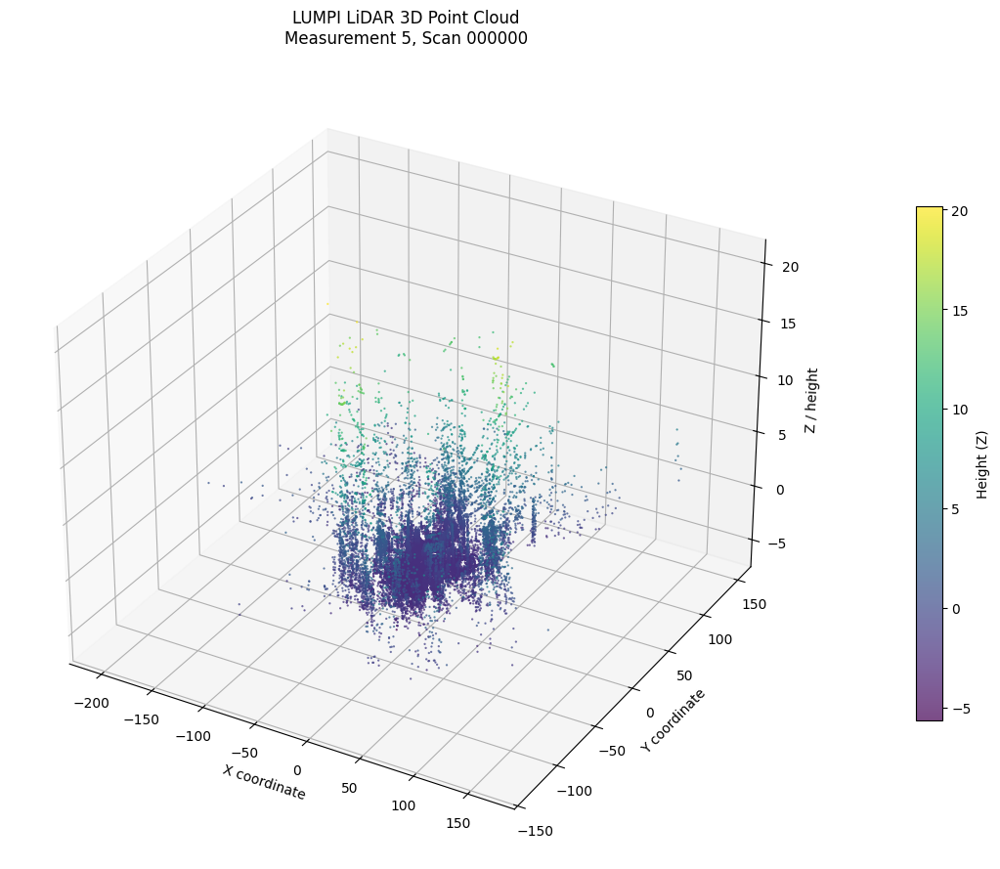

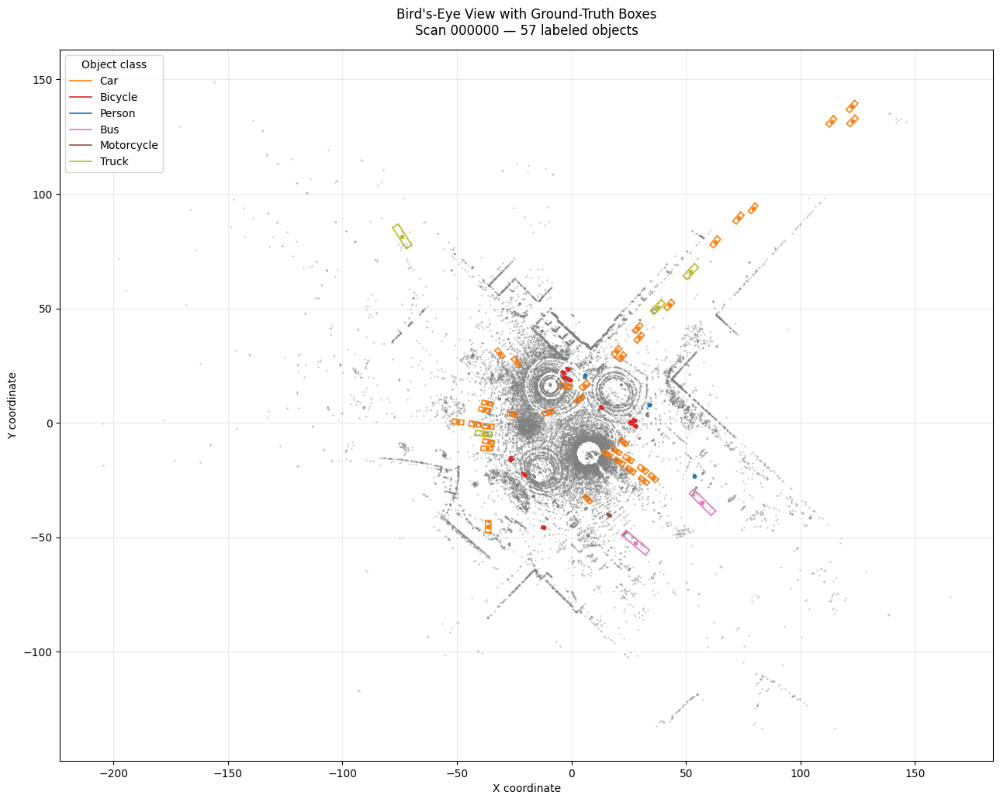


Visualization files saved:
1. /kaggle/working/lumpi_visuals/lidar_3d_point_cloud.png
2. /kaggle/working/lumpi_visuals/lidar_bird_eye_ground_truth.png

Ground-truth class counts:
class_id
Car           36
Bicycle       11
Truck          4
Person         3
Bus            2
Motorcycle     1

Next milestone:
Generate candidate boxes from raw LiDAR points and
visualize predicted boxes separately from ground truth.


In [99]:

# ============================================================
# LUMPI LiDAR VISUALIZATION PROTOTYPE
# 1. Load one LiDAR scan and its ground-truth labels
# 2. Plot the 3D point cloud, colored by height
# 3. Plot a bird's-eye view with labeled box footprints
# 4. Save both visualizations as PNG files
#
# Existing files required:
# /kaggle/working/test_data.zip
# /kaggle/working/Label.csv
# ============================================================

import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- CONFIGURATION ---------------------------

ZIP_PATH = "/kaggle/working/test_data.zip"
LABEL_PATH = "/kaggle/working/Label.csv"
OUTPUT_DIR = Path("/kaggle/working/lumpi_visuals")

MEASUREMENT = 5
SCAN_ID = 0
TIMESTAMP = SCAN_ID / 10.0
MAX_PLOT_POINTS = 30000
RANDOM_SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "Person",
    1: "Car",
    2: "Bicycle",
    3: "Motorcycle",
    4: "Bus",
    5: "Truck",
    6: "Unknown",
}

CLASS_COLORS = plt.cm.tab10(np.linspace(0, 1, 7))

# -------------------- VALIDATE INPUT FILES --------------------

for path in [ZIP_PATH, LABEL_PATH]:
    if not Path(path).exists():
        raise FileNotFoundError(f"Required file not found: {path}")

# -------------------- LOAD PLY SCAN ---------------------------

member = (
    f"test_data/Measurement{MEASUREMENT}/lidar/"
    f"{SCAN_ID:06d}.ply"
)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    if member not in archive.namelist():
        raise FileNotFoundError(f"Scan not found inside ZIP: {member}")

    with archive.open(member) as file:
        header_lines = []

        while True:
            line = file.readline()

            if not line:
                raise ValueError("PLY header ended unexpectedly.")

            header_lines.append(line)

            if line.strip() == b"end_header":
                break

        header = b"".join(header_lines).decode("ascii")
        raw = file.read()

# Read vertex count from PLY header.
vertex_line = next(
    line for line in header.splitlines()
    if line.startswith("element vertex ")
)

n_points = int(vertex_line.split()[-1])

# This dataset's known PLY format uses 23-byte point records:
# float32 XYZ (12 bytes), followed by other point attributes.
record_size = 23

if len(raw) != n_points * record_size:
    raise ValueError(
        f"Unexpected point-data size: {len(raw):,} bytes; "
        f"expected {n_points * record_size:,} bytes."
    )

xyz = np.ndarray(
    shape=(n_points, 3),
    dtype="<f4",
    buffer=raw,
    offset=0,
    strides=(record_size, 4),
).copy()

# Remove any invalid coordinates.
xyz = xyz[np.isfinite(xyz).all(axis=1)]

if len(xyz) == 0:
    raise ValueError("No finite XYZ points were found.")

# -------------------- LOAD GROUND-TRUTH LABELS ----------------

labels = pd.read_csv(LABEL_PATH)

box_columns = [
    "3D box: center x",
    "y",
    "z",
    "length",
    " width ",
    "height.1",
    "heading",
]

required_columns = ["time", "score", "class_id"] + box_columns
missing_columns = [c for c in required_columns if c not in labels.columns]

if missing_columns:
    raise ValueError(f"Missing label columns: {missing_columns}")

frame = labels[
    np.isclose(labels["time"], TIMESTAMP) &
    (labels["score"] == 4)
].dropna(subset=box_columns + ["class_id"]).copy()

print("=" * 60)
print("LUMPI LiDAR VISUALIZATION")
print("=" * 60)
print("Scan file:", member)
print("Timestamp:", TIMESTAMP)
print("Finite XYZ points:", f"{len(xyz):,}")
print("Corrected ground-truth boxes:", len(frame))
print("XYZ minimum:", np.round(xyz.min(axis=0), 2))
print("XYZ maximum:", np.round(xyz.max(axis=0), 2))

# -------------------- SUBSAMPLE FOR DISPLAY -------------------

rng = np.random.default_rng(RANDOM_SEED)
sample_count = min(MAX_PLOT_POINTS, len(xyz))

indices = rng.choice(
    len(xyz),
    size=sample_count,
    replace=False,
)

plot_points = xyz[indices]

# -------------------- VISUALIZATION 1: 3D POINT CLOUD ---------

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    plot_points[:, 0],
    plot_points[:, 1],
    plot_points[:, 2],
    c=plot_points[:, 2],
    cmap="viridis",
    s=0.4,
    alpha=0.7,
)

ax.set_title(
    f"LUMPI LiDAR 3D Point Cloud\n"
    f"Measurement {MEASUREMENT}, Scan {SCAN_ID:06d}",
    pad=18,
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_zlabel("Z / height")

fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.65,
    pad=0.1,
    label="Height (Z)",
)

plt.tight_layout()

cloud_path = OUTPUT_DIR / "lidar_3d_point_cloud.png"
fig.savefig(cloud_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# -------------------- VISUALIZATION 2: BIRD'S-EYE VIEW --------

fig, ax = plt.subplots(figsize=(13, 11))

ax.scatter(
    plot_points[:, 0],
    plot_points[:, 1],
    s=0.4,
    c="gray",
    alpha=0.4,
    label="LiDAR points",
)

legend_handles = {}

for _, row in frame.iterrows():
    cx = float(row["3D box: center x"])
    cy = float(row["y"])
    length = float(row["length"])
    width = float(row[" width "])
    heading = float(row["heading"])
    class_id = int(row["class_id"])

    # Rectangle in the box's local XY coordinate system.
    corners = np.array([
        [-length / 2, -width / 2],
        [ length / 2, -width / 2],
        [ length / 2,  width / 2],
        [-length / 2,  width / 2],
        [-length / 2, -width / 2],
    ])

    # Assumed heading convention: rotation around the Z axis.
    cosine = np.cos(heading)
    sine = np.sin(heading)

    rotation = np.array([
        [cosine, -sine],
        [sine, cosine],
    ])

    corners = corners @ rotation.T
    corners += np.array([cx, cy])

    class_name = CLASS_NAMES.get(class_id, f"Class {class_id}")
    color = CLASS_COLORS[class_id % len(CLASS_COLORS)]

    line, = ax.plot(
        corners[:, 0],
        corners[:, 1],
        color=color,
        linewidth=1.2,
    )

    # Mark the box center.
    ax.scatter(
        cx,
        cy,
        color=color,
        s=10,
    )

    if class_name not in legend_handles:
        legend_handles[class_name] = line

ax.set_title(
    f"Bird's-Eye View with Ground-Truth Boxes\n"
    f"Scan {SCAN_ID:06d} — {len(frame)} labeled objects",
    pad=14,
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.25)

if legend_handles:
    ax.legend(
        legend_handles.values(),
        legend_handles.keys(),
        title="Object class",
        loc="best",
    )

plt.tight_layout()

bev_path = OUTPUT_DIR / "lidar_bird_eye_ground_truth.png"
fig.savefig(bev_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# -------------------- SUMMARY ---------------------------------

print("\nVisualization files saved:")
print(f"1. {cloud_path}")
print(f"2. {bev_path}")

print("\nGround-truth class counts:")
if len(frame):
    class_counts = (
        frame["class_id"]
        .astype(int)
        .map(lambda x: CLASS_NAMES.get(x, f"Class {x}"))
        .value_counts()
    )
    print(class_counts.to_string())
else:
    print("No corrected ground-truth boxes found for this timestamp.")

print("\nNext milestone:")
print("Generate candidate boxes from raw LiDAR points and")
print("visualize predicted boxes separately from ground truth.")

# NOTE:
# These are ground-truth visualizations, NOT detector predictions.
# The scan-to-timestamp correspondence and box-heading convention
# are assumptions that should be verified before formal evaluation.

Raw points: 278748
Downsampled points: 101222
Ground-truth boxes: 57
DBSCAN clusters before size/dimension filtering: 457
Candidate boxes retained: 161


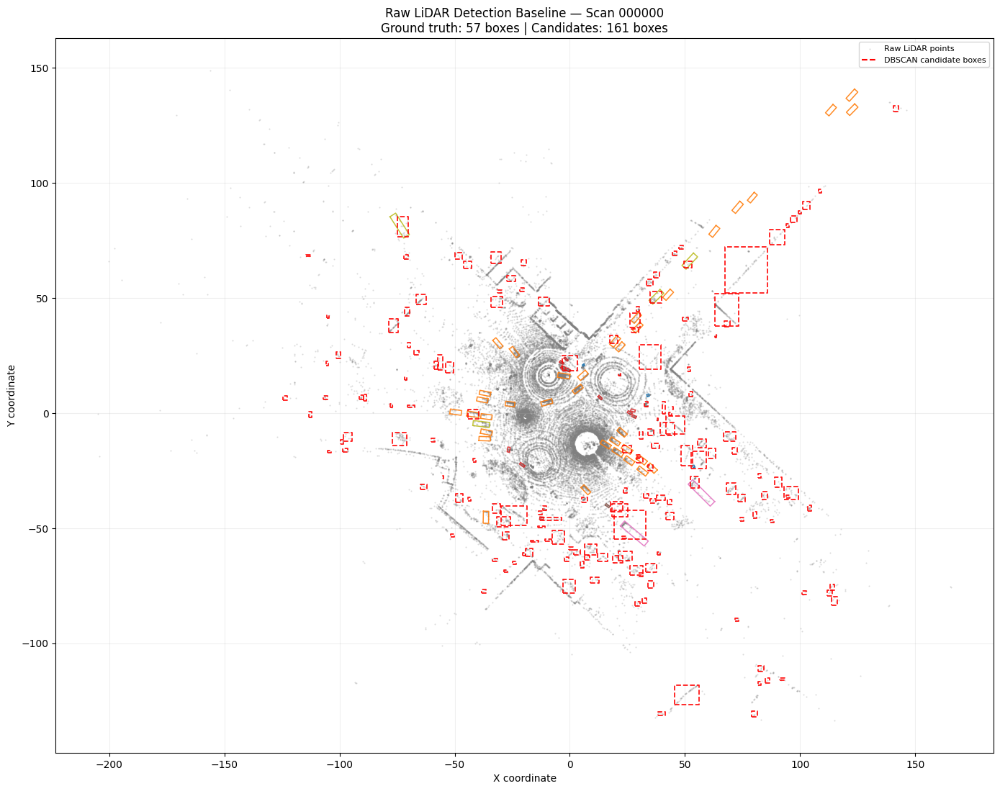


Saved comparison image: /kaggle/working/lumpi_visuals/dbscan_predictions_vs_ground_truth.png
Saved candidate table: /kaggle/working/lumpi_visuals/dbscan_candidate_boxes.csv

Largest candidate clusters:
 cluster_id  point_count          x          y     z        dx        dy   dz
        157          361  26.010000 -48.480000 -0.85 13.690000 12.670000 3.26
        211          357 -24.240000 -44.560001 -1.58 11.120000  8.640000 1.55
         37          271  76.650002  62.250000  1.75 18.690001 19.950001 7.63
        244          255 -74.000000 -11.310000  0.97  6.140000  5.850000 4.95
        214          224 -28.799999 -47.340000 -0.89  6.100000  4.430000 2.92
         43          216  68.070000  44.759998  1.93 10.280000 14.020000 6.67
         21          186   0.040000  21.780001 -0.52  6.470000  6.680000 3.59
        185          181   9.130000 -59.310001 -0.33  5.400000  4.480000 2.07
         53          168  34.959999  24.440001 -2.16  9.510000 10.500000 0.27
        241      

In [100]:

# ============================================================
# LUMPI: FIRST RAW-POINT DETECTION BASELINE
# DBSCAN clustering -> candidate 3D boxes -> ground-truth overlay
# ============================================================

import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# -------------------- CONFIGURATION ---------------------------

ZIP_PATH = "/kaggle/working/test_data.zip"
LABEL_PATH = "/kaggle/working/Label.csv"
OUT_DIR = Path("/kaggle/working/lumpi_visuals")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MEASUREMENT = 5
SCAN_ID = 0
TIMESTAMP = SCAN_ID / 10.0

# DBSCAN settings; these are starting values to tune.
VOXEL_SIZE = 0.15       # meters; voxel downsampling resolution
EPS = 0.8               # neighborhood radius in XY plane
MIN_SAMPLES = 8         # DBSCAN core-point threshold
MIN_CLUSTER_POINTS = 15
MAX_CLUSTER_POINTS = 20000

CLASS_NAMES = {
    0: "Person", 1: "Car", 2: "Bicycle", 3: "Motorcycle",
    4: "Bus", 5: "Truck", 6: "Unknown"
}
CLASS_COLORS = plt.cm.tab10(np.linspace(0, 1, 7))

# -------------------- LOAD RAW XYZ ----------------------------

member = (
    f"test_data/Measurement{MEASUREMENT}/lidar/"
    f"{SCAN_ID:06d}.ply"
)

with zipfile.ZipFile(ZIP_PATH) as archive:
    with archive.open(member) as f:
        header_lines = []
        while True:
            line = f.readline()
            if not line:
                raise ValueError("PLY header ended unexpectedly")
            header_lines.append(line)
            if line.strip() == b"end_header":
                break
        header = b"".join(header_lines).decode("ascii")
        raw = f.read()

n_points = int(next(
    line.split()[-1]
    for line in header.splitlines()
    if line.startswith("element vertex ")
))

record_size = 23
if len(raw) != n_points * record_size:
    raise ValueError("Unexpected PLY record size")

xyz = np.ndarray(
    shape=(n_points, 3),
    dtype="<f4",
    buffer=raw,
    offset=0,
    strides=(record_size, 4)
).copy()

xyz = xyz[np.isfinite(xyz).all(axis=1)]

# -------------------- LOAD GROUND TRUTH -----------------------

labels = pd.read_csv(LABEL_PATH)

box_cols = [
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]

gt = labels[
    np.isclose(labels["time"], TIMESTAMP) &
    (labels["score"] == 4)
].dropna(subset=box_cols + ["class_id"]).copy()

# -------------------- VOXEL DOWNSAMPLING ----------------------
# Use one representative point per XY voxel, retaining its XYZ.
# This reduces the cost of clustering dense LiDAR scans.

xy_voxels = np.floor(xyz[:, :2] / VOXEL_SIZE).astype(np.int32)
_, unique_indices = np.unique(
    xy_voxels, axis=0, return_index=True
)
downsampled = xyz[np.sort(unique_indices)]

print("Raw points:", len(xyz))
print("Downsampled points:", len(downsampled))
print("Ground-truth boxes:", len(gt))

# -------------------- DBSCAN CLUSTERING -----------------------
# Cluster by XY only because a vehicle's LiDAR points may span
# multiple heights. Z is retained for 3D box estimation.

cluster_labels = DBSCAN(
    eps=EPS,
    min_samples=MIN_SAMPLES,
    algorithm="kd_tree",
    n_jobs=-1
).fit_predict(downsampled[:, :2])

candidate_boxes = []
cluster_ids = sorted(set(cluster_labels) - {-1})

for cluster_id in cluster_ids:
    points = downsampled[cluster_labels == cluster_id]

    if not (MIN_CLUSTER_POINTS <= len(points) <= MAX_CLUSTER_POINTS):
        continue

    # Axis-aligned 3D bounding box for a transparent baseline.
    mins = points.min(axis=0)
    maxs = points.max(axis=0)
    dims = maxs - mins
    center = (mins + maxs) / 2.0

    # Ignore extremely small clusters and very large scene regions.
    if dims[0] < 0.15 or dims[1] < 0.15 or dims[2] < 0.15:
        continue
    if dims[0] > 20 or dims[1] > 20 or dims[2] > 8:
        continue

    candidate_boxes.append({
        "cluster_id": int(cluster_id),
        "point_count": len(points),
        "x": center[0],
        "y": center[1],
        "z": center[2],
        "dx": dims[0],
        "dy": dims[1],
        "dz": dims[2],
    })

pred = pd.DataFrame(candidate_boxes)

print("DBSCAN clusters before size/dimension filtering:", len(cluster_ids))
print("Candidate boxes retained:", len(pred))

# -------------------- VISUALIZE PREDICTED VS GROUND TRUTH -----

fig, ax = plt.subplots(figsize=(14, 12))

# Background raw points (subsample for plotting).
rng = np.random.default_rng(42)
plot_n = min(40000, len(xyz))
plot_idx = rng.choice(len(xyz), plot_n, replace=False)
plot_xyz = xyz[plot_idx]

ax.scatter(
    plot_xyz[:, 0], plot_xyz[:, 1],
    s=0.3, color="gray", alpha=0.25,
    label="Raw LiDAR points"
)

# Ground truth: solid colored rectangles.
gt_legend = {}

for _, r in gt.iterrows():
    cx = float(r["3D box: center x"])
    cy = float(r["y"])
    length = float(r["length"])
    width = float(r[" width "])
    heading = float(r["heading"])
    cls = int(r["class_id"])

    corners = np.array([
        [-length/2, -width/2],
        [ length/2, -width/2],
        [ length/2,  width/2],
        [-length/2,  width/2],
        [-length/2, -width/2]
    ])

    c, s = np.cos(heading), np.sin(heading)
    rotation = np.array([[c, -s], [s, c]])
    corners = corners @ rotation.T + np.array([cx, cy])

    name = CLASS_NAMES.get(cls, f"Class {cls}")
    line, = ax.plot(
        corners[:, 0], corners[:, 1],
        color=CLASS_COLORS[cls],
        linewidth=1.1,
        alpha=0.9
    )
    gt_legend.setdefault(name, line)

# Predictions: red dashed axis-aligned rectangles.
for _, r in pred.iterrows():
    cx, cy = r["x"], r["y"]
    dx, dy = r["dx"], r["dy"]

    corners = np.array([
        [cx-dx/2, cy-dy/2],
        [cx+dx/2, cy-dy/2],
        [cx+dx/2, cy+dy/2],
        [cx-dx/2, cy+dy/2],
        [cx-dx/2, cy-dy/2]
    ])

    ax.plot(
        corners[:, 0], corners[:, 1],
        color="red",
        linestyle="--",
        linewidth=1.3,
        alpha=0.9
    )

# Proxy legend item for candidate predictions.
ax.plot([], [], "r--", linewidth=1.5, label="DBSCAN candidate boxes")

ax.set_title(
    f"Raw LiDAR Detection Baseline — Scan {SCAN_ID:06d}\n"
    f"Ground truth: {len(gt)} boxes | "
    f"Candidates: {len(pred)} boxes"
)
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)

handles, names = ax.get_legend_handles_labels()
ax.legend(handles, names, loc="best", fontsize=8)

plt.tight_layout()

comparison_path = OUT_DIR / "dbscan_predictions_vs_ground_truth.png"
fig.savefig(comparison_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# -------------------- SAVE CANDIDATE TABLE --------------------

csv_path = OUT_DIR / "dbscan_candidate_boxes.csv"
pred.to_csv(csv_path, index=False)

print("\nSaved comparison image:", comparison_path)
print("Saved candidate table:", csv_path)

if len(pred):
    print("\nLargest candidate clusters:")
    print(
        pred.sort_values("point_count", ascending=False)
            .head(10)
            .round(2)
            .to_string(index=False)
    )
else:
    print(
        "\nNo candidate boxes survived filtering. "
        "We will tune DBSCAN parameters if needed."
    )

print(
    "\nInterpretation: red dashed boxes are unsupervised proposals; "
    "colored solid boxes are ground-truth annotations. "
    "Visual overlap is only a first diagnostic, not a detection score."
)

DBSCAN 3D DETECTION EVALUATION
Measurement: 5
Scan: 0
Ground-truth boxes: 57
Candidate boxes: 161
Maximum candidate-to-ground-truth IoU: 0.4875

Metrics:
 IoU threshold  TP  FP  FN  Precision  Recall    F1
          0.25   6 155  51     0.0373  0.1053 0.055
          0.50   0 161  57     0.0000  0.0000 0.000


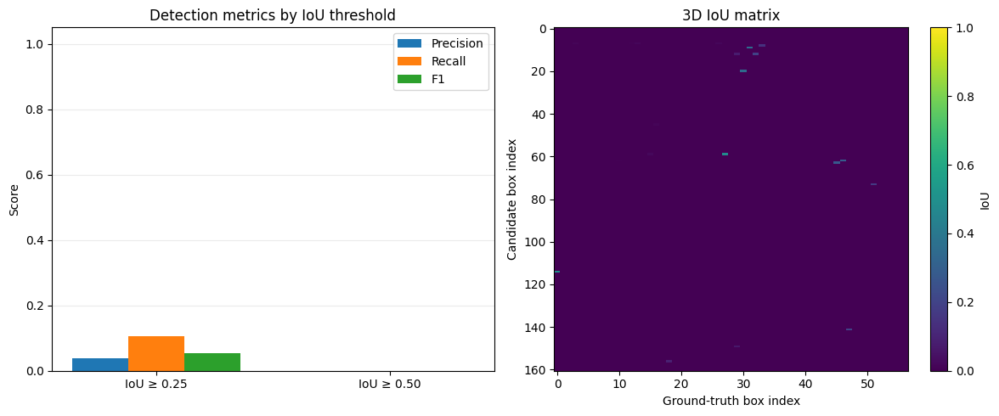


Saved metrics: /kaggle/working/lumpi_visuals/dbscan_detection_metrics.csv
Saved evaluation plot: /kaggle/working/lumpi_visuals/dbscan_detection_evaluation.png

Caution: single scan only; no class-aware matching; axis-aligned IoU; greedy matching. These are diagnostic baseline metrics, not official benchmark results.


In [101]:
# ============================================================
# STEP 32 — EVALUATE DBSCAN CANDIDATE BOXES
# Axis-aligned 3D IoU, matching, metrics, and visualization
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- CONFIGURATION ---------------------------

OUT_DIR = Path("/kaggle/working/lumpi_visuals")
PRED_PATH = OUT_DIR / "dbscan_candidate_boxes.csv"
LABEL_PATH = "/kaggle/working/Label.csv"

MEASUREMENT = 5
SCAN_ID = 0
TIMESTAMP = SCAN_ID / 10.0

IOU_THRESHOLDS = [0.25, 0.50]

# -------------------- LOAD DATA -------------------------------

if not PRED_PATH.exists():
    raise FileNotFoundError(f"Candidate file not found: {PRED_PATH}")

pred = pd.read_csv(PRED_PATH)
labels = pd.read_csv(LABEL_PATH)

box_cols = [
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]

gt = labels[
    np.isclose(labels["time"], TIMESTAMP) &
    (labels["score"] == 4)
].dropna(subset=box_cols + ["class_id"]).copy()

# Convert ground-truth boxes into axis-aligned bounds.
# This deliberately ignores heading in this first evaluation.
gt_boxes = []

for _, r in gt.iterrows():
    cx = float(r["3D box: center x"])
    cy = float(r["y"])
    cz = float(r["z"])

    dx = float(r["length"])
    dy = float(r[" width "])
    dz = float(r["height.1"])

    if min(dx, dy, dz) <= 0:
        continue

    gt_boxes.append({
        "xmin": cx - dx / 2,
        "xmax": cx + dx / 2,
        "ymin": cy - dy / 2,
        "ymax": cy + dy / 2,
        "zmin": cz - dz / 2,
        "zmax": cz + dz / 2,
        "class_id": int(r["class_id"]),
    })

gt_df = pd.DataFrame(gt_boxes)

# Candidate DBSCAN boxes are already axis-aligned.
pred_boxes = []

for _, r in pred.iterrows():
    cx, cy, cz = float(r["x"]), float(r["y"]), float(r["z"])
    dx, dy, dz = float(r["dx"]), float(r["dy"]), float(r["dz"])

    if min(dx, dy, dz) <= 0:
        continue

    pred_boxes.append({
        "xmin": cx - dx / 2,
        "xmax": cx + dx / 2,
        "ymin": cy - dy / 2,
        "ymax": cy + dy / 2,
        "zmin": cz - dz / 2,
        "zmax": cz + dz / 2,
        "point_count": int(r["point_count"]),
    })

pred_df = pd.DataFrame(pred_boxes)

print("=" * 60)
print("DBSCAN 3D DETECTION EVALUATION")
print("=" * 60)
print("Measurement:", MEASUREMENT)
print("Scan:", SCAN_ID)
print("Ground-truth boxes:", len(gt_df))
print("Candidate boxes:", len(pred_df))

# -------------------- 3D IOU FUNCTION -------------------------

def box_iou_3d(a, b):
    """Axis-aligned 3D IoU for boxes represented by min/max bounds."""

    ix = max(
        0.0,
        min(a["xmax"], b["xmax"]) -
        max(a["xmin"], b["xmin"])
    )
    iy = max(
        0.0,
        min(a["ymax"], b["ymax"]) -
        max(a["ymin"], b["ymin"])
    )
    iz = max(
        0.0,
        min(a["zmax"], b["zmax"]) -
        max(a["zmin"], b["zmin"])
    )

    intersection = ix * iy * iz

    vol_a = (
        (a["xmax"] - a["xmin"]) *
        (a["ymax"] - a["ymin"]) *
        (a["zmax"] - a["zmin"])
    )

    vol_b = (
        (b["xmax"] - b["xmin"]) *
        (b["ymax"] - b["ymin"]) *
        (b["zmax"] - b["zmin"])
    )

    union = vol_a + vol_b - intersection

    return intersection / union if union > 0 else 0.0


# -------------------- COMPUTE IOU MATRIX ----------------------

iou_matrix = np.zeros((len(pred_df), len(gt_df)), dtype=float)

for i in range(len(pred_df)):
    for j in range(len(gt_df)):
        iou_matrix[i, j] = box_iou_3d(
            pred_df.iloc[i],
            gt_df.iloc[j]
        )

if iou_matrix.size:
    print("Maximum candidate-to-ground-truth IoU:",
          round(float(iou_matrix.max()), 4))
else:
    print("No box pairs available for IoU calculation.")

# -------------------- GREEDY ONE-TO-ONE MATCHING --------------

def match_boxes(iou, threshold):
    """
    Greedy one-to-one matching:
    each candidate and ground-truth box can be matched at most once.
    """
    if iou.size == 0:
        return []

    pairs = []
    used_pred = set()
    used_gt = set()

    # Consider highest-IoU pairs first.
    order = np.argsort(iou.ravel())[::-1]

    for flat_index in order:
        i, j = np.unravel_index(flat_index, iou.shape)

        if iou[i, j] < threshold:
            break

        if i in used_pred or j in used_gt:
            continue

        used_pred.add(i)
        used_gt.add(j)
        pairs.append((i, j, float(iou[i, j])))

    return pairs


# -------------------- CALCULATE METRICS -----------------------

results = []

for threshold in IOU_THRESHOLDS:
    matches = match_boxes(iou_matrix, threshold)

    tp = len(matches)
    fp = len(pred_df) - tp
    fn = len(gt_df) - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    results.append({
        "IoU threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    })

metrics = pd.DataFrame(results)

print("\nMetrics:")
print(metrics.round(4).to_string(index=False))

metrics_path = OUT_DIR / "dbscan_detection_metrics.csv"
metrics.to_csv(metrics_path, index=False)

# -------------------- VISUALIZATION: METRICS ------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x = np.arange(len(metrics))
width = 0.24

axes[0].bar(
    x - width,
    metrics["Precision"],
    width,
    label="Precision"
)
axes[0].bar(
    x,
    metrics["Recall"],
    width,
    label="Recall"
)
axes[0].bar(
    x + width,
    metrics["F1"],
    width,
    label="F1"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [f"IoU ≥ {t:.2f}" for t in metrics["IoU threshold"]]
)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Score")
axes[0].set_title("Detection metrics by IoU threshold")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

# IoU heatmap: candidate boxes versus ground truth.
if iou_matrix.size:
    im = axes[1].imshow(
        iou_matrix,
        aspect="auto",
        interpolation="nearest",
        vmin=0,
        vmax=1
    )
    axes[1].set_xlabel("Ground-truth box index")
    axes[1].set_ylabel("Candidate box index")
    axes[1].set_title("3D IoU matrix")
    fig.colorbar(im, ax=axes[1], label="IoU")
else:
    axes[1].text(
        0.5, 0.5,
        "No box pairs to display",
        ha="center",
        va="center"
    )
    axes[1].set_axis_off()

plt.tight_layout()

plot_path = OUT_DIR / "dbscan_detection_evaluation.png"
fig.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved metrics:", metrics_path)
print("Saved evaluation plot:", plot_path)

print(
    "\nCaution: single scan only; no class-aware matching; "
    "axis-aligned IoU; greedy matching. These are diagnostic "
    "baseline metrics, not official benchmark results."
)

Original points: 278748
Points above ground threshold: 116949
Points after voxel downsampling: 86741
DBSCAN clusters before filtering: 1150
Retained candidate boxes: 500
Saved: /kaggle/working/lumpi_visuals/dbscan_3d_candidate_boxes.csv


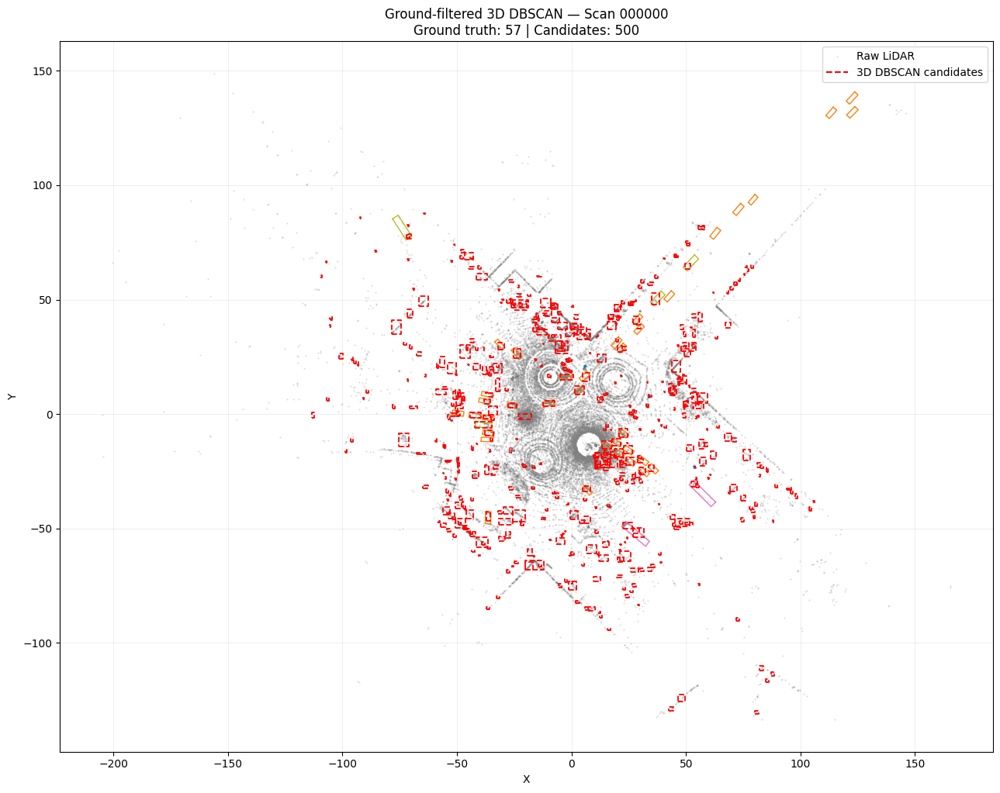

Saved visualization: /kaggle/working/lumpi_visuals/dbscan_3d_vs_ground_truth.png

Largest retained candidates:
 cluster_id  point_count      x      y     z   dx   dy   dz
        584          865 -20.40  -1.02  0.47 5.82 2.48 4.54
        157          815  -2.18  16.16 -1.10 5.66 2.43 1.40
        215          767   3.51  10.38 -1.25 3.92 3.64 1.10
        504          766  -9.93   4.67 -1.19 4.88 2.56 1.23
        344          740  15.47 -13.53 -1.08 4.00 3.36 1.44
        657          735 -25.83   3.88 -1.01 3.81 2.16 1.57
        866          462 -23.75  26.32 -1.20 3.24 4.09 1.21
        308          462  22.60  -8.28 -1.22 3.55 3.55 1.17
         80          454  -4.30  29.15  2.28 5.33 5.23 3.18
        211          435  33.17   3.76  0.01 1.09 1.47 3.61


In [102]:
# ============================================================
# STEP 33 — GROUND-FILTERED 3D DBSCAN DETECTION
# ============================================================

import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# ---------------- CONFIGURATION ----------------

ZIP_PATH = "/kaggle/working/test_data.zip"
LABEL_PATH = "/kaggle/working/Label.csv"
OUT_DIR = Path("/kaggle/working/lumpi_visuals")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MEASUREMENT = 5
SCAN_ID = 0
TIMESTAMP = SCAN_ID / 10.0

VOXEL_SIZE = 0.12
GROUND_Z_THRESHOLD = -1.8

EPS_3D = 0.65
MIN_SAMPLES = 6
MIN_CLUSTER_POINTS = 12

# Broad initial bounds, not learned class dimensions.
MIN_DIMS = np.array([0.20, 0.20, 0.25])
MAX_DIMS = np.array([12.0, 6.0, 5.0])

CLASS_NAMES = {
    0: "Person", 1: "Car", 2: "Bicycle",
    3: "Motorcycle", 4: "Bus", 5: "Truck", 6: "Unknown"
}
COLORS = plt.cm.tab10(np.linspace(0, 1, 7))

# ---------------- LOAD PLY ---------------------

member = (
    f"test_data/Measurement{MEASUREMENT}/lidar/"
    f"{SCAN_ID:06d}.ply"
)

with zipfile.ZipFile(ZIP_PATH) as archive:
    with archive.open(member) as f:
        header_lines = []
        while True:
            line = f.readline()
            if not line:
                raise ValueError("Unexpected end of PLY header")
            header_lines.append(line)
            if line.strip() == b"end_header":
                break

        header = b"".join(header_lines).decode("ascii")
        raw = f.read()

n_points = int(next(
    line.split()[-1]
    for line in header.splitlines()
    if line.startswith("element vertex ")
))

record_size = 23

if len(raw) != n_points * record_size:
    raise ValueError("Unexpected PLY point-data size")

xyz = np.ndarray(
    shape=(n_points, 3),
    dtype="<f4",
    buffer=raw,
    offset=0,
    strides=(record_size, 4)
).copy()

xyz = xyz[np.isfinite(xyz).all(axis=1)]

# ---------------- APPROXIMATE GROUND FILTER ----
# This fixed Z threshold is only a quick baseline.
# It may remove valid low points or retain sloped ground.

nonground = xyz[xyz[:, 2] > GROUND_Z_THRESHOLD]

print("Original points:", len(xyz))
print("Points above ground threshold:", len(nonground))

if len(nonground) == 0:
    raise ValueError("Ground filter removed every point.")

# ---------------- VOXEL DOWNSAMPLING ------------

voxel_keys = np.floor(nonground / VOXEL_SIZE).astype(np.int32)

_, unique_idx = np.unique(
    voxel_keys,
    axis=0,
    return_index=True
)

points = nonground[np.sort(unique_idx)]

print("Points after voxel downsampling:", len(points))

# ---------------- 3D DBSCAN ---------------------

cluster_ids = DBSCAN(
    eps=EPS_3D,
    min_samples=MIN_SAMPLES,
    algorithm="kd_tree",
    n_jobs=-1
).fit_predict(points)

unique_clusters = sorted(set(cluster_ids) - {-1})
candidate_rows = []

for cluster_id in unique_clusters:
    cluster = points[cluster_ids == cluster_id]

    if len(cluster) < MIN_CLUSTER_POINTS:
        continue

    lo = cluster.min(axis=0)
    hi = cluster.max(axis=0)
    dims = hi - lo

    # Filter implausibly small or large clusters.
    if np.any(dims < MIN_DIMS):
        continue

    if np.any(dims > MAX_DIMS):
        continue

    center = (lo + hi) / 2

    candidate_rows.append({
        "cluster_id": int(cluster_id),
        "point_count": int(len(cluster)),
        "x": float(center[0]),
        "y": float(center[1]),
        "z": float(center[2]),
        "dx": float(dims[0]),
        "dy": float(dims[1]),
        "dz": float(dims[2]),
    })

pred3d = pd.DataFrame(candidate_rows)

candidate_path = OUT_DIR / "dbscan_3d_candidate_boxes.csv"
pred3d.to_csv(candidate_path, index=False)

print("DBSCAN clusters before filtering:", len(unique_clusters))
print("Retained candidate boxes:", len(pred3d))
print("Saved:", candidate_path)

# ---------------- LOAD GROUND TRUTH --------------

labels = pd.read_csv(LABEL_PATH)

box_cols = [
    "3D box: center x", "y", "z",
    "length", " width ", "height.1", "heading"
]

gt = labels[
    np.isclose(labels["time"], TIMESTAMP) &
    (labels["score"] == 4)
].dropna(subset=box_cols + ["class_id"]).copy()

# ---------------- VISUALIZE ----------------------

rng = np.random.default_rng(42)
plot_n = min(35000, len(xyz))
plot_idx = rng.choice(len(xyz), plot_n, replace=False)
plot_xyz = xyz[plot_idx]

fig, ax = plt.subplots(figsize=(13, 11))

ax.scatter(
    plot_xyz[:, 0],
    plot_xyz[:, 1],
    s=0.3,
    color="gray",
    alpha=0.25,
    label="Raw LiDAR"
)

# Ground-truth oriented footprints in class colors.
for _, r in gt.iterrows():
    cx = float(r["3D box: center x"])
    cy = float(r["y"])
    length = float(r["length"])
    width = float(r[" width "])
    heading = float(r["heading"])
    cls = int(r["class_id"])

    corners = np.array([
        [-length/2, -width/2],
        [ length/2, -width/2],
        [ length/2,  width/2],
        [-length/2,  width/2],
        [-length/2, -width/2],
    ])

    c, s = np.cos(heading), np.sin(heading)
    rot = np.array([[c, -s], [s, c]])
    corners = corners @ rot.T + [cx, cy]

    ax.plot(
        corners[:, 0],
        corners[:, 1],
        color=COLORS[cls],
        linewidth=1.0
    )

# New candidate boxes in red dashed lines.
for _, r in pred3d.iterrows():
    cx, cy = r["x"], r["y"]
    dx, dy = r["dx"], r["dy"]

    corners = np.array([
        [cx-dx/2, cy-dy/2],
        [cx+dx/2, cy-dy/2],
        [cx+dx/2, cy+dy/2],
        [cx-dx/2, cy+dy/2],
        [cx-dx/2, cy-dy/2],
    ])

    ax.plot(
        corners[:, 0],
        corners[:, 1],
        "r--",
        linewidth=1.3
    )

ax.plot([], [], "r--", label="3D DBSCAN candidates")
ax.set_title(
    f"Ground-filtered 3D DBSCAN — Scan {SCAN_ID:06d}\n"
    f"Ground truth: {len(gt)} | Candidates: {len(pred3d)}"
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend(loc="best")

plt.tight_layout()

image_path = OUT_DIR / "dbscan_3d_vs_ground_truth.png"
fig.savefig(image_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved visualization:", image_path)

if len(pred3d):
    print("\nLargest retained candidates:")
    print(
        pred3d.sort_values("point_count", ascending=False)
        .head(10)
        .round(2)
        .to_string(index=False)
    )
else:
    print("No candidates retained. Parameters may need adjustment.")

In [104]:

# ============================================================
# LUMPI — STEP 34
# Evaluate 3D DBSCAN candidate boxes against ground truth
# Measurement5 / Scan 000000
# ============================================================

import os
import zipfile
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. File paths
# ------------------------------------------------------------
ZIP_PATH = "/kaggle/working/test_data.zip"
CANDIDATE_PATH = (
    "/kaggle/working/lumpi_visuals/dbscan_3d_candidate_boxes.csv"
)
OUTPUT_DIR = "/kaggle/working/lumpi_visuals"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Load candidate boxes
# ------------------------------------------------------------
pred = pd.read_csv(CANDIDATE_PATH)

required_pred_cols = ["x", "y", "z", "dx", "dy", "dz"]
missing = [c for c in required_pred_cols if c not in pred.columns]

if missing:
    raise ValueError(
        f"Candidate CSV is missing columns: {missing}\n"
        f"Available columns: {pred.columns.tolist()}"
    )

pred = pred.dropna(subset=required_pred_cols).copy()

for c in required_pred_cols:
    pred[c] = pd.to_numeric(pred[c], errors="coerce")

pred = pred.dropna(subset=required_pred_cols)
pred = pred[
    (pred["dx"] > 0) & (pred["dy"] > 0) & (pred["dz"] > 0)
].copy()

# ------------------------------------------------------------
# 3. Load labels from Measurement5
# ------------------------------------------------------------
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    label_members = [
        name for name in z.namelist()
        if name.endswith("Measurement5/Label.csv")
    ]

    if not label_members:
        raise FileNotFoundError(
            "Measurement5/Label.csv was not found inside test_data.zip"
        )

    with z.open(label_members[0]) as f:
        labels = pd.read_csv(f)

# IMPORTANT:
# Duplicate column names such as "width" are renamed by position.
# This matches the 17-column schema observed in your error output.
if labels.shape[1] != 17:
    raise ValueError(
        f"Expected 17 label columns but found {labels.shape[1]}.\n"
        f"Actual columns: {labels.columns.tolist()}"
    )

labels.columns = [
    "time",
    "object_id",
    "rect_x",
    "rect_y",
    "rect_width",
    "rect_height",
    "score",
    "class_id",
    "visibility",
    "center_x",
    "center_y",
    "center_z",
    "length",
    "box_width",
    "box_height",
    "heading",
    "extra",
]

# Convert required columns to numeric values.
numeric_cols = [
    "time", "score", "center_x", "center_y", "center_z",
    "length", "box_width", "box_height", "heading"
]

for c in numeric_cols:
    labels[c] = pd.to_numeric(labels[c], errors="coerce")

# ------------------------------------------------------------
# 4. Select ground-truth boxes for scan timestamp 0.0
# ------------------------------------------------------------
# Assumptions to verify later:
#   - Scan 000000 corresponds to timestamp 0.0.
#   - score == 4 identifies corrected ground-truth boxes.

gt = labels[
    np.isclose(labels["time"], 0.0)
    & (labels["score"] == 4)
].copy()

gt = gt.dropna(
    subset=[
        "center_x", "center_y", "center_z",
        "length", "box_width", "box_height"
    ]
)

gt = gt[
    (gt["length"] > 0)
    & (gt["box_width"] > 0)
    & (gt["box_height"] > 0)
].copy()

print("=" * 60)
print("LUMPI — 3D DBSCAN EVALUATION")
print("=" * 60)
print("Candidate boxes:", len(pred))
print("Ground-truth boxes:", len(gt))

if len(pred) == 0 or len(gt) == 0:
    raise ValueError(
        "Predictions or ground-truth boxes are empty. "
        "Check the candidate CSV, timestamp, and score filter."
    )

# ------------------------------------------------------------
# 5. Convert boxes to axis-aligned corners
# ------------------------------------------------------------
# NOTE:
# This approximation ignores each GT box's heading.
# It is useful for diagnostics, but not an official 3D IoU score.

p_center = pred[["x", "y", "z"]].to_numpy(dtype=float)
p_dims = pred[["dx", "dy", "dz"]].to_numpy(dtype=float)

g_center = gt[
    ["center_x", "center_y", "center_z"]
].to_numpy(dtype=float)

g_dims = gt[
    ["length", "box_width", "box_height"]
].to_numpy(dtype=float)

p_half = p_dims / 2.0
g_half = g_dims / 2.0

p_min = p_center - p_half
p_max = p_center + p_half

g_min = g_center - g_half
g_max = g_center + g_half

# ------------------------------------------------------------
# 6. Calculate pairwise 3D IoU
# ------------------------------------------------------------
ious = np.zeros((len(pred), len(gt)), dtype=np.float64)

g_volume = np.prod(np.maximum(g_max - g_min, 0), axis=1)

for i in range(len(pred)):
    intersection_min = np.maximum(p_min[i], g_min)
    intersection_max = np.minimum(p_max[i], g_max)

    intersection_dims = np.maximum(
        intersection_max - intersection_min, 0
    )

    intersection_volume = np.prod(intersection_dims, axis=1)

    pred_volume = np.prod(
        np.maximum(p_max[i] - p_min[i], 0)
    )

    union = pred_volume + g_volume - intersection_volume

    valid = union > 0
    ious[i, valid] = (
        intersection_volume[valid] / union[valid]
    )

print("\nMaximum IoU overall:", round(float(ious.max()), 4))
print(
    "Ground-truth boxes with best IoU >= 0.25:",
    int(np.sum(ious.max(axis=0) >= 0.25))
)
print(
    "Ground-truth boxes with best IoU >= 0.50:",
    int(np.sum(ious.max(axis=0) >= 0.50))
)

# ------------------------------------------------------------
# 7. Greedy one-to-one detection matching
# ------------------------------------------------------------
def evaluate_threshold(iou_matrix, threshold):
    pairs = np.argwhere(iou_matrix >= threshold)

    # Process candidate/GT pairs from highest IoU to lowest.
    pairs = sorted(
        pairs.tolist(),
        key=lambda pair: iou_matrix[pair[0], pair[1]],
        reverse=True
    )

    matched_pred = set()
    matched_gt = set()

    for pred_idx, gt_idx in pairs:
        if (
            pred_idx not in matched_pred
            and gt_idx not in matched_gt
        ):
            matched_pred.add(pred_idx)
            matched_gt.add(gt_idx)

    tp = len(matched_pred)
    fp = len(pred) - tp
    fn = len(gt) - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "IoU_threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }

results = pd.DataFrame([
    evaluate_threshold(ious, 0.25),
    evaluate_threshold(ious, 0.50),
])

print("\nDetection metrics:")
print(results.round(4).to_string(index=False))

# ------------------------------------------------------------
# 8. Save evaluation results
# ------------------------------------------------------------
metrics_path = os.path.join(
    OUTPUT_DIR, "dbscan_3d_detection_metrics.csv"
)

results.to_csv(metrics_path, index=False)

# Save best overlap for each GT box.
gt_diagnostic = gt.copy()
gt_diagnostic["best_candidate_iou"] = ious.max(axis=0)

gt_diagnostic_path = os.path.join(
    OUTPUT_DIR, "dbscan_3d_gt_overlap_diagnostic.csv"
)

gt_diagnostic.to_csv(gt_diagnostic_path, index=False)

# Save the strongest candidate match for each GT box.
best_candidate_idx = ious.argmax(axis=0)

gt_diagnostic["best_candidate_index"] = best_candidate_idx
gt_diagnostic["best_candidate_cluster_id"] = (
    pred.iloc[best_candidate_idx]["cluster_id"].to_numpy()
    if "cluster_id" in pred.columns
    else best_candidate_idx
)

gt_diagnostic.to_csv(gt_diagnostic_path, index=False)

print("\nSaved files:")
print(metrics_path)
print(gt_diagnostic_path)

print("\nEvaluation complete.")
print(
    "Reminder: this is approximate axis-aligned IoU, "
    "not official benchmark evaluation."
)

LUMPI — 3D DBSCAN EVALUATION
Candidate boxes: 500
Ground-truth boxes: 57

Maximum IoU overall: 0.73
Ground-truth boxes with best IoU >= 0.25: 30
Ground-truth boxes with best IoU >= 0.50: 8

Detection metrics:
 IoU_threshold  TP  FP  FN  Precision  Recall     F1
          0.25  30 470  27      0.060  0.5263 0.1077
          0.50   8 492  49      0.016  0.1404 0.0287

Saved files:
/kaggle/working/lumpi_visuals/dbscan_3d_detection_metrics.csv
/kaggle/working/lumpi_visuals/dbscan_3d_gt_overlap_diagnostic.csv

Evaluation complete.
Reminder: this is approximate axis-aligned IoU, not official benchmark evaluation.


In [106]:

# ================================================================
# LUMPI RESEARCH ENGINE — REVISED VERSION
# PART 1 OF 4: CONFIGURATION, VALIDATION, DATA LOADING
# ================================================================

from __future__ import annotations

import os
import sys
import json
import math
import time
import random
import hashlib
import zipfile
import logging
import platform
import traceback

from pathlib import Path
from datetime import datetime, timezone
from dataclasses import dataclass, asdict
from typing import Any, Optional, Sequence

import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN
from scipy.spatial import cKDTree


# ----------------------- CONFIGURATION ---------------------------

@dataclass
class LumpiConfig:
    zip_path: str = "/kaggle/working/test_data.zip"
    measurement: str = "Measurement5"
    output_dir: str = "/kaggle/working/lumpi_research_engine"

    timestamp_step: float = 0.1
    corrected_score: Optional[float] = 4.0

    height_threshold: float = -1.8
    voxel_size: float = 0.12

    dbscan_eps: float = 0.65
    dbscan_min_samples: int = 6

    min_cluster_points: int = 12
    max_cluster_points: int = 20000

    min_length: float = 0.20
    min_width: float = 0.20
    min_height: float = 0.25

    max_length: float = 12.0
    max_width: float = 6.0
    max_height: float = 5.0

    iou_thresholds: tuple = (0.25, 0.50)

    random_seed: int = 42
    save_plots: bool = True
    verbose: bool = True


CFG = LumpiConfig()


# ----------------------- LOGGING --------------------------------

def utc_timestamp():
    return datetime.now(timezone.utc).isoformat()


def ensure_directory(path):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def make_logger(output_dir, verbose=True):
    output_dir = ensure_directory(output_dir)

    logger = logging.getLogger("LUMPI")
    logger.setLevel(logging.DEBUG)
    logger.handlers.clear()
    logger.propagate = False

    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s"
    )

    file_handler = logging.FileHandler(
        output_dir / "run.log",
        encoding="utf-8"
    )
    file_handler.setFormatter(formatter)
    file_handler.setLevel(logging.DEBUG)

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setFormatter(formatter)
    console_handler.setLevel(
        logging.INFO if verbose else logging.WARNING
    )

    logger.addHandler(file_handler)
    logger.addHandler(console_handler)

    return logger


def set_random_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)


# ----------------------- SAFE CONVERSION ------------------------

def safe_float(value):
    """
    Convert a single value to a finite float.

    Returns None for:
      - multi-value arrays or Series
      - missing values
      - non-numeric values
      - NaN and infinity

    This prevents the sequence-related np.isfinite crash.
    """
    try:
        array = np.asarray(value)

        if array.size != 1:
            return None

        result = float(array.reshape(-1)[0])

        if not np.isfinite(result):
            return None

        return result

    except (TypeError, ValueError, OverflowError):
        return None


def safe_int(value):
    number = safe_float(value)

    if number is None:
        return None

    if not number.is_integer():
        return None

    return int(number)


def json_safe(value):
    if isinstance(value, dict):
        return {
            str(k): json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float) and not math.isfinite(value):
        return None

    return value


def write_json(path, data):
    path = Path(path)
    ensure_directory(path.parent)

    with path.open("w", encoding="utf-8") as handle:
        json.dump(
            json_safe(data),
            handle,
            indent=2,
            allow_nan=False
        )


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


# ----------------------- ZIP VALIDATION -------------------------

def check_archive(zip_path):
    zip_path = Path(zip_path)

    if not zip_path.exists():
        raise FileNotFoundError(
            f"Dataset archive not found: {zip_path}"
        )

    if not zipfile.is_zipfile(zip_path):
        raise ValueError(
            f"File is not a valid ZIP archive: {zip_path}"
        )

    with zipfile.ZipFile(zip_path, "r") as archive:
        bad_member = archive.testzip()

        if bad_member is not None:
            raise zipfile.BadZipFile(
                f"Corrupt ZIP member: {bad_member}"
            )

        return archive.namelist()


def find_zip_member(archive, suffix):
    """
    Find a unique ZIP member by its ending path.

    The measurement directory is included in the suffix to avoid
    accidentally reading another measurement's scan.
    """
    suffix = suffix.replace("\\", "/").strip("/").lower()

    matches = [
        name
        for name in archive.namelist()
        if name.replace("\\", "/").lower().endswith(suffix)
    ]

    if not matches:
        raise FileNotFoundError(
            f"No archive member ends with {suffix!r}"
        )

    if len(matches) > 1:
        raise RuntimeError(
            f"Ambiguous archive member {suffix!r}: "
            f"{matches[:10]}"
        )

    return matches[0]


def list_scan_indices(archive, measurement):
    prefix = measurement.strip("/") + "/"
    indices = []

    for name in archive.namelist():
        normalized = name.replace("\\", "/")

        if not normalized.startswith(prefix):
            continue

        filename = normalized.rsplit("/", 1)[-1]

        if not filename.lower().endswith(".ply"):
            continue

        stem = filename[:-4]

        if stem.isdigit():
            indices.append(int(stem))

    indices = sorted(set(indices))

    if not indices:
        raise FileNotFoundError(
            f"No numbered PLY scans found in {measurement}/"
        )

    return indices


# ----------------------- BINARY PLY PARSER ----------------------

PLY_DTYPE = np.dtype([
    ("x", "<f4"),
    ("y", "<f4"),
    ("z", "<f4"),
    ("time", "<u4"),
    ("id", "u1"),
    ("intensity", "u1"),
    ("ray", "u1"),
    ("azimuth", "<u2"),
    ("distance", "<u2"),
])

assert PLY_DTYPE.itemsize == 23, (
    "Unexpected PLY record size. Verify the dataset schema."
)


def read_ply_bytes(raw, source="<memory>"):
    """
    Parse the dataset's binary little-endian PLY format.

    Supports LF and CRLF header endings. Reads only the declared
    vertex records and validates payload length.
    """
    marker = b"end_header"
    marker_index = raw.find(marker)

    if marker_index < 0:
        raise ValueError(
            f"PLY header terminator not found: {source}"
        )

    header_end = marker_index + len(marker)

    # Consume the newline after end_header.
    if raw[header_end:header_end + 2] == b"\r\n":
        header_end += 2
    elif raw[header_end:header_end + 1] == b"\n":
        header_end += 1
    else:
        raise ValueError(
            f"Missing newline after PLY header: {source}"
        )

    header = raw[:header_end].decode(
        "ascii",
        errors="replace"
    )

    if "format binary_little_endian" not in header:
        raise ValueError(
            f"Unsupported PLY format in {source}"
        )

    vertex_count = None

    for line in header.splitlines():
        fields = line.strip().split()

        if (
            len(fields) == 3
            and fields[0] == "element"
            and fields[1] == "vertex"
        ):
            vertex_count = int(fields[2])
            break

    if vertex_count is None or vertex_count < 0:
        raise ValueError(
            f"Invalid or missing vertex count: {source}"
        )

    expected_bytes = vertex_count * PLY_DTYPE.itemsize
    available_bytes = len(raw) - header_end

    if available_bytes < expected_bytes:
        raise ValueError(
            f"Truncated PLY: {source}; expected "
            f"{expected_bytes} payload bytes, found "
            f"{available_bytes}"
        )

    records = np.frombuffer(
        raw,
        dtype=PLY_DTYPE,
        count=vertex_count,
        offset=header_end
    )

    xyz = np.column_stack([
        records["x"],
        records["y"],
        records["z"]
    ])

    return xyz.astype(np.float32, copy=False)


def load_scan(archive, measurement, scan_index):
    suffix = (
        f"{measurement}/{scan_index:06d}.ply"
    )

    member = find_zip_member(archive, suffix)

    with archive.open(member, "r") as handle:
        raw = handle.read()

    return read_ply_bytes(raw, member)


# ----------------------- LABEL SCHEMA ---------------------------

# Label.csv has 17 columns and may have duplicate original names.
# Rename strictly by column position rather than ambiguous names.

LABEL_COLUMNS = [
    "time",
    "object_id",
    "rect_left",
    "rect_top",
    "rect_width",
    "rect_height",
    "score",
    "class_id",
    "visibility",
    "center_x",
    "center_y",
    "center_z",
    "box_length",
    "box_width",
    "box_height",
    "heading",
    "extra",
]

CLASS_NAMES = {
    0: "Person",
    1: "Car",
    2: "Bicycle",
    3: "Motorcycle",
    4: "Bus",
    5: "Truck",
    6: "Unknown",
}


def load_labels(archive, measurement):
    suffix = f"{measurement}/Label.csv"
    member = find_zip_member(archive, suffix)

    with archive.open(member, "r") as handle:
        labels = pd.read_csv(handle)

    if labels.shape[1] != len(LABEL_COLUMNS):
        raise ValueError(
            f"Expected {len(LABEL_COLUMNS)} columns in {member}; "
            f"found {labels.shape[1]}. Do not continue until "
            "the label schema has been inspected."
        )

    labels.columns = LABEL_COLUMNS

    numeric_columns = [
        "time",
        "score",
        "class_id",
        "visibility",
        "center_x",
        "center_y",
        "center_z",
        "box_length",
        "box_width",
        "box_height",
        "heading",
    ]

    for column in numeric_columns:
        labels[column] = pd.to_numeric(
            labels[column],
            errors="coerce"
        )

    return labels


def labels_for_timestamp(
    labels,
    timestamp,
    corrected_score=4.0,
    tolerance=1e-4
):
    """
    Select labels matching the assumed scan timestamp.

    The score filter is configurable because score == 4 must be
    verified against official dataset documentation.
    """
    timestamp = safe_float(timestamp)

    if timestamp is None:
        return labels.iloc[0:0].copy()

    selected = labels[
        np.isfinite(labels["time"].to_numpy(dtype=float))
        & (
            np.abs(
                labels["time"].to_numpy(dtype=float)
                - timestamp
            ) <= tolerance
        )
    ].copy()

    if corrected_score is not None:
        selected = selected[
            selected["score"] == corrected_score
        ]

    required = [
        "center_x",
        "center_y",
        "center_z",
        "box_length",
        "box_width",
        "box_height",
        "heading",
        "class_id",
    ]

    selected = selected.dropna(subset=required)

    dimension_values = selected[
        ["box_length", "box_width", "box_height"]
    ].to_numpy(dtype=float)

    selected = selected[
        np.isfinite(dimension_values).all(axis=1)
        & (dimension_values > 0).all(axis=1)
    ]

    return selected.reset_index(drop=True)


# ----------------------- INITIAL DIAGNOSTICS --------------------

def environment_report():
    report = {
        "python": sys.version,
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "timestamp_utc": utc_timestamp(),
    }

    try:
        import sklearn
        report["scikit_learn"] = sklearn.__version__
    except Exception:
        report["scikit_learn"] = "unavailable"

    try:
        import scipy
        report["scipy"] = scipy.__version__
    except Exception:
        report["scipy"] = "unavailable"

    return report


def validate_config(cfg):
    if cfg.timestamp_step <= 0:
        raise ValueError("timestamp_step must be positive")

    if cfg.voxel_size <= 0:
        raise ValueError("voxel_size must be positive")

    if cfg.dbscan_eps <= 0:
        raise ValueError("dbscan_eps must be positive")

    if cfg.dbscan_min_samples < 1:
        raise ValueError("dbscan_min_samples must be at least 1")

    if cfg.min_cluster_points < 1:
        raise ValueError("min_cluster_points must be at least 1")

    if cfg.max_cluster_points < cfg.min_cluster_points:
        raise ValueError(
            "max_cluster_points must be >= min_cluster_points"
        )

    for threshold in cfg.iou_thresholds:
        if not 0 < threshold <= 1:
            raise ValueError(
                f"Invalid IoU threshold: {threshold}"
            )


# ----------------------- PART 1 SELF-CHECK -----------------------

validate_config(CFG)
set_random_seeds(CFG.random_seed)

print("LUMPI Part 1 loaded successfully.")
print("Configuration:")
print(json.dumps(asdict(CFG), indent=2))
print("\nEnvironment:")
print(json.dumps(environment_report(), indent=2))

print(
    "\nNext: Part 2 adds preprocessing, clustering proposals, "
    "and safe bounding-box evaluation."
)

LUMPI Part 1 loaded successfully.
Configuration:
{
  "zip_path": "/kaggle/working/test_data.zip",
  "measurement": "Measurement5",
  "output_dir": "/kaggle/working/lumpi_research_engine",
  "timestamp_step": 0.1,
  "corrected_score": 4.0,
  "height_threshold": -1.8,
  "voxel_size": 0.12,
  "dbscan_eps": 0.65,
  "dbscan_min_samples": 6,
  "min_cluster_points": 12,
  "max_cluster_points": 20000,
  "min_length": 0.2,
  "min_width": 0.2,
  "min_height": 0.25,
  "max_length": 12.0,
  "max_width": 6.0,
  "max_height": 5.0,
  "iou_thresholds": [
    0.25,
    0.5
  ],
  "random_seed": 42,
  "save_plots": true,
  "verbose": true
}

Environment:
{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "timestamp_utc": "2026-10-15T04:13:43.659452+00:00",
  "scikit_learn": "1.6.1",
  "scipy": "1.16.3"
}

Next: Part 2 adds preprocessing, clustering proposals, and safe bounding-box evaluation

In [107]:

# ================================================================
# LUMPI RESEARCH ENGINE
# PART 2 OF 4: PREPROCESSING, CLUSTERING, BOX GEOMETRY
# ================================================================

from collections import Counter


# ----------------------- POINT-CLOUD CLEANING -------------------

def clean_point_cloud(points):
    """
    Keep finite XYZ coordinates only.
    Returns an N x 3 float32 array.
    """
    points = np.asarray(points)

    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError(
            f"Expected N x 3 XYZ array; got {points.shape}"
        )

    finite_mask = np.isfinite(points).all(axis=1)
    return points[finite_mask].astype(np.float32, copy=False)


def filter_by_height(points, height_threshold):
    points = clean_point_cloud(points)

    if len(points) == 0:
        return points

    return points[
        points[:, 2] > float(height_threshold)
    ]


def voxel_downsample(points, voxel_size):
    """
    Replace all points in each occupied voxel with their centroid.
    Uses NumPy only and avoids allocating a dense 3D grid.
    """
    points = clean_point_cloud(points)

    voxel_size = safe_float(voxel_size)

    if voxel_size is None or voxel_size <= 0:
        raise ValueError("voxel_size must be a positive scalar")

    if len(points) == 0:
        return np.empty((0, 3), dtype=np.float32)

    voxel_keys = np.floor(
        points.astype(np.float64) / voxel_size
    ).astype(np.int64)

    unique_keys, inverse = np.unique(
        voxel_keys,
        axis=0,
        return_inverse=True
    )

    counts = np.bincount(
        inverse,
        minlength=len(unique_keys)
    )

    sums = np.zeros(
        (len(unique_keys), 3),
        dtype=np.float64
    )

    np.add.at(sums, inverse, points)

    centroids = sums / counts[:, None]

    return centroids.astype(np.float32)


def preprocess_point_cloud(points, cfg=CFG):
    """
    Return processed points plus counts at each stage.
    """
    original_count = int(len(points))

    finite_points = clean_point_cloud(points)
    finite_count = int(len(finite_points))

    height_points = filter_by_height(
        finite_points,
        cfg.height_threshold
    )
    height_count = int(len(height_points))

    sampled_points = voxel_downsample(
        height_points,
        cfg.voxel_size
    )

    statistics = {
        "original_points": original_count,
        "finite_points": finite_count,
        "points_after_height_filter": height_count,
        "points_after_voxel_sampling": int(len(sampled_points)),
    }

    return sampled_points, statistics


# ----------------------- BOX VALIDATION -------------------------

def normalize_box_values(
    cx, cy, cz, length, width, height, heading=0.0
):
    """
    Convert all inputs to finite scalar floats.

    Returns a dictionary, or None if any field is invalid.
    This explicitly avoids np.isfinite() on mixed sequences.
    """
    raw_values = {
        "cx": cx,
        "cy": cy,
        "cz": cz,
        "length": length,
        "width": width,
        "height": height,
        "heading": heading,
    }

    values = {}

    for name, raw_value in raw_values.items():
        converted = safe_float(raw_value)

        if converted is None:
            return None

        values[name] = converted

    if (
        values["length"] <= 0
        or values["width"] <= 0
        or values["height"] <= 0
    ):
        return None

    return values


def ground_truth_boxes(frame_labels):
    """
    Convert selected label rows into validated box dictionaries.

    Input columns are the normalized Part 1 names, not the original
    duplicate CSV headers.
    """
    boxes = []
    rejected = 0

    required = [
        "center_x", "center_y", "center_z",
        "box_length", "box_width", "box_height",
        "heading", "class_id"
    ]

    for _, row in frame_labels.iterrows():
        values = normalize_box_values(
            row["center_x"],
            row["center_y"],
            row["center_z"],
            row["box_length"],
            row["box_width"],
            row["box_height"],
            row["heading"],
        )

        class_id = safe_int(row["class_id"])

        if values is None or class_id is None:
            rejected += 1
            continue

        box = {
            **values,
            "class_id": class_id,
            "class_name": CLASS_NAMES.get(
                class_id, "Unmapped"
            ),
        }

        boxes.append(box)

    return boxes, {
        "ground_truth_boxes_valid": len(boxes),
        "ground_truth_boxes_rejected": rejected,
    }


# ----------------------- DBSCAN PROPOSALS -----------------------

def cluster_to_candidate(points, cluster_id):
    """
    Create an axis-aligned proposal from cluster extrema.

    Heading is not estimated here. These proposals are diagnostic,
    not oriented 3D detections.
    """
    points = clean_point_cloud(points)

    if len(points) == 0:
        return None

    lower = np.min(points, axis=0)
    upper = np.max(points, axis=0)
    dimensions = upper - lower
    center = (lower + upper) / 2.0

    candidate = {
        "candidate_id": int(cluster_id),
        "cx": float(center[0]),
        "cy": float(center[1]),
        "cz": float(center[2]),
        "length": float(dimensions[0]),
        "width": float(dimensions[1]),
        "height": float(dimensions[2]),
        "point_count": int(len(points)),
    }

    if not all(
        np.isfinite(candidate[key])
        for key in (
            "cx", "cy", "cz",
            "length", "width", "height"
        )
    ):
        return None

    return candidate


def candidate_is_valid(candidate, cfg=CFG):
    if candidate is None:
        return False

    try:
        return (
            cfg.min_length <= candidate["length"] <= cfg.max_length
            and cfg.min_width <= candidate["width"] <= cfg.max_width
            and cfg.min_height <= candidate["height"] <= cfg.max_height
            and cfg.min_cluster_points
                <= candidate["point_count"]
                <= cfg.max_cluster_points
        )
    except (KeyError, TypeError, ValueError):
        return False


def generate_dbscan_proposals(points, cfg=CFG):
    """
    Generate cluster proposals using configured DBSCAN parameters.

    Important: sklearn DBSCAN can consume substantial memory when
    eps is large or points are dense. Voxel sampling should be
    performed first.
    """
    points = clean_point_cloud(points)

    if len(points) < cfg.dbscan_min_samples:
        return [], {
            "cluster_count": 0,
            "noise_points": int(len(points)),
            "retained_proposals": 0,
            "status": "too_few_points",
        }

    model = DBSCAN(
        eps=float(cfg.dbscan_eps),
        min_samples=int(cfg.dbscan_min_samples),
        n_jobs=-1,
    )

    cluster_labels = model.fit_predict(points)

    non_noise_labels = np.unique(
        cluster_labels[cluster_labels >= 0]
    )

    proposals = []

    for cluster_id in non_noise_labels:
        cluster_points = points[
            cluster_labels == cluster_id
        ]

        point_count = len(cluster_points)

        if not (
            cfg.min_cluster_points
            <= point_count
            <= cfg.max_cluster_points
        ):
            continue

        candidate = cluster_to_candidate(
            cluster_points,
            int(cluster_id)
        )

        if candidate_is_valid(candidate, cfg):
            proposals.append(candidate)

    statistics = {
        "cluster_count": int(len(non_noise_labels)),
        "noise_points": int(
            np.sum(cluster_labels == -1)
        ),
        "retained_proposals": int(len(proposals)),
        "status": "ok",
    }

    return proposals, statistics


# ----------------------- 3D AXIS-ALIGNED IoU --------------------

def axis_aligned_iou_3d(box_a, box_b):
    """
    Calculate approximate 3D IoU for six values:
      [cx, cy, cz, length, width, height]

    Heading is ignored. Do not interpret this as oriented 3D IoU.
    """
    try:
        a = np.asarray(box_a, dtype=np.float64).reshape(-1)
        b = np.asarray(box_b, dtype=np.float64).reshape(-1)
    except (TypeError, ValueError):
        return 0.0

    if a.size != 6 or b.size != 6:
        return 0.0

    if not np.isfinite(a).all() or not np.isfinite(b).all():
        return 0.0

    da = a[3:6]
    db = b[3:6]

    if np.any(da <= 0) or np.any(db <= 0):
        return 0.0

    a_min = a[:3] - da / 2.0
    a_max = a[:3] + da / 2.0

    b_min = b[:3] - db / 2.0
    b_max = b[:3] + db / 2.0

    intersection_dimensions = np.maximum(
        np.minimum(a_max, b_max)
        - np.maximum(a_min, b_min),
        0.0
    )

    intersection_volume = float(
        np.prod(intersection_dimensions)
    )

    volume_a = float(np.prod(da))
    volume_b = float(np.prod(db))

    union_volume = (
        volume_a + volume_b - intersection_volume
    )

    if union_volume <= 0:
        return 0.0

    return intersection_volume / union_volume


def candidate_box_vector(box):
    """
    Convert a proposal or GT dictionary to the six-value IoU form.
    """
    keys = [
        "cx", "cy", "cz",
        "length", "width", "height"
    ]

    values = [safe_float(box.get(key)) for key in keys]

    if any(value is None for value in values):
        return None

    return values


# ----------------------- PART 2 SELF-TESTS ----------------------

def run_part2_self_tests():
    # The original crash scenario: sequence values must be rejected.
    assert safe_float([1.0, 2.0]) is None
    assert safe_float(np.array([1.0, 2.0])) is None
    assert safe_float(pd.Series([1.0, 2.0])) is None

    # Scalar values should work.
    assert safe_float(1.5) == 1.5
    assert safe_float(np.float64(2.5)) == 2.5
    assert safe_float(float("nan")) is None

    # Identical boxes have IoU 1.
    box = [0, 0, 0, 2, 2, 2]
    assert abs(axis_aligned_iou_3d(box, box) - 1.0) < 1e-12

    # Disjoint boxes have IoU 0.
    distant_box = [10, 10, 10, 2, 2, 2]
    assert axis_aligned_iou_3d(box, distant_box) == 0.0

    # Basic voxel downsampling sanity test.
    points = np.array([
        [0.01, 0.01, 0.01],
        [0.02, 0.02, 0.02],
        [1.01, 1.01, 1.01],
    ], dtype=np.float32)

    sampled = voxel_downsample(points, 0.1)
    assert sampled.shape == (2, 3)

    print("Part 2 self-tests passed.")


run_part2_self_tests()

print("LUMPI Part 2 loaded successfully.")
print("Next: Part 3 adds per-frame processing and evaluation.")

Part 2 self-tests passed.
LUMPI Part 2 loaded successfully.
Next: Part 3 adds per-frame processing and evaluation.


In [109]:

# ============================================================
# LUMPI PART 4 — EXPERIMENT RUNNER AND REPRODUCIBLE OUTPUTS
# Requires Parts 1, 2, and 3 to have run successfully.
# ============================================================

import gc
import inspect
import traceback
from pathlib import Path
from datetime import datetime, timezone

# ---------- 1. Resolve the dataset configuration safely ----------

def _resolve_archive_path(cfg=CFG):
    """Find the configured ZIP archive without assuming a field name."""
    candidates = []

    for name, value in vars(cfg).items():
        if isinstance(value, (str, Path)):
            s = str(value)
            if s.lower().endswith(".zip"):
                candidates.append((name, Path(s)))

    # Prefer a path that exists.
    for name, path in candidates:
        if path.is_file():
            return str(path)

    # Common Kaggle default used in this experiment.
    default_path = Path("/kaggle/working/test_data.zip")
    if default_path.is_file():
        return str(default_path)

    details = [(name, str(path)) for name, path in candidates]
    raise FileNotFoundError(
        "Could not resolve the dataset ZIP. "
        f"Configured ZIP candidates: {details}. "
        f"Fallback checked: {default_path}"
    )


def _resolve_measurement_name(cfg=CFG):
    """Resolve Measurement5 unless the configuration specifies otherwise."""
    for name, value in vars(cfg).items():
        if isinstance(value, str) and value.startswith("Measurement"):
            return value
    return "Measurement5"


def _call_loader_compatibly(func, archive_path, measurement_name):
    """
    Call a project loader using its declared parameter names.
    Falls back to the common (archive, measurement) signature.
    """
    sig = inspect.signature(func)
    kwargs = {}

    archive_aliases = {
        "archive", "archive_path", "zip_path", "zip_file",
        "zip_path_or_buf", "path"
    }
    measurement_aliases = {
        "measurement", "measurement_name", "measurement_id",
        "sequence", "sequence_name", "folder"
    }

    unresolved = []
    for param_name, param in sig.parameters.items():
        if param.kind in (
            inspect.Parameter.VAR_POSITIONAL,
            inspect.Parameter.VAR_KEYWORD,
        ):
            continue

        key = param_name.lower()
        if key in archive_aliases:
            kwargs[param_name] = archive_path
        elif key in measurement_aliases:
            kwargs[param_name] = measurement_name
        elif param.default is inspect.Parameter.empty:
            unresolved.append(param_name)

    if not unresolved:
        return func(**kwargs)

    # Compatibility fallback for common loader signatures.
    try:
        return func(archive_path, measurement_name)
    except TypeError as first_error:
        try:
            return func(archive_path)
        except TypeError:
            raise RuntimeError(
                f"Unable to call {func.__name__}{sig}. "
                f"Unresolved required parameters: {unresolved}"
            ) from first_error


# ---------- 2. Output locations ----------

OUTPUT_DIR = Path("/kaggle/working/lumpi_experiment")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FRAME_DIR = OUTPUT_DIR / "frames"
FRAME_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)


# ---------- 3. Experiment runner ----------

def run_lumpi_experiment(
    max_frames=1,
    start_index=0,
    save_frame_details=True,
):
    """
    Run LUMPI detection diagnostics.

    Recommended first run:
        run_lumpi_experiment(max_frames=1)

    Full run after inspecting the first-frame outputs:
        run_lumpi_experiment(max_frames=31)

    max_frames=None processes all discovered scan indices from start_index.
    """
    archive_path = _resolve_archive_path(CFG)
    measurement_name = _resolve_measurement_name(CFG)

    print("\nLUMPI experiment starting")
    print("Archive:", archive_path)
    print("Measurement:", measurement_name)
    print("Output:", OUTPUT_DIR)
    print("Requested frames:", max_frames)
    print("Start index:", start_index)

    # Validate the dataset before starting the frame loop.
    preflight = preflight_dataset(CFG)
    print("\nPreflight result:")
    print(json.dumps(json_safe(preflight), indent=2, default=str))

    # Load labels once; scans are loaded and processed individually.
    labels = _call_loader_compatibly(
        load_labels, archive_path, measurement_name
    )

    if labels is None or len(labels) == 0:
        raise ValueError(
            "Label loader returned no labels. "
            "Check the archive, measurement name, and label CSV."
        )

    # Discover scan indices using the project's existing helper.
    try:
        scan_indices = list_scan_indices(archive_path, measurement_name)
    except TypeError:
        scan_indices = list_scan_indices(archive_path)

    scan_indices = sorted(
        int(i) for i in scan_indices if int(i) >= int(start_index)
    )

    if max_frames is not None:
        scan_indices = scan_indices[:int(max_frames)]

    if not scan_indices:
        raise RuntimeError(
            "No scan indices found for the requested run. "
            "Inspect list_scan_indices() and the archive structure."
        )

    print(f"\nScans scheduled: {len(scan_indices)}")
    print("Indices:", scan_indices)

    frame_summaries = []
    frame_metrics = []
    all_matches = []
    failed_frames = []

    run_metadata = {
        "experiment": "LUMPI DBSCAN detection diagnostic",
        "started_utc": datetime.now(timezone.utc).isoformat(),
        "archive_path": archive_path,
        "measurement": measurement_name,
        "max_frames_requested": max_frames,
        "start_index": start_index,
        "scan_indices": scan_indices,
        "timestamp_mapping_assumption": (
            "timestamp = scan_index * CFG.timestamp_step; "
            "must be independently verified"
        ),
        "ground_truth_score_assumption": (
            "Any score filter used by the existing ground_truth_boxes() "
            "function must be verified against official dataset documentation."
        ),
        "metric_warning": (
            "Diagnostic approximate axis-aligned 3D IoU; not an official "
            "benchmark score unless the official evaluation protocol matches."
        ),
        "configuration": json_safe(vars(CFG)),
        "environment": json_safe(environment_report()),
    }

    write_json(OUTPUT_DIR / "run_metadata.json", run_metadata)

    for position, scan_index in enumerate(scan_indices, start=1):
        print(
            f"\n[{position}/{len(scan_indices)}] "
            f"Processing scan {scan_index:06d} ..."
        )

        try:
            result = process_frame(
                archive=archive_path,
                labels=labels,
                scan_index=scan_index,
                cfg=CFG,
                save_predictions=save_frame_details,
            )

            # Extract outputs produced by Part 3.
            summary = result.get("summary", {})
            metrics = result.get("metrics", [])
            predictions = result.get("predictions", [])
            ground_truth = result.get("ground_truth", [])
            matches = result.get("matches", [])

            # Make each frame's summary identifiable.
            if isinstance(summary, dict):
                summary = dict(summary)
                summary["scan_index"] = int(scan_index)
                frame_summaries.append(summary)

            # Normalize metric rows to a list of dictionaries.
            if isinstance(metrics, pd.DataFrame):
                metric_rows = metrics.to_dict(orient="records")
            elif isinstance(metrics, dict):
                metric_rows = [metrics]
            elif isinstance(metrics, (list, tuple)):
                metric_rows = list(metrics)
            else:
                metric_rows = []

            for row in metric_rows:
                if isinstance(row, dict):
                    row = dict(row)
                    row["scan_index"] = int(scan_index)
                    frame_metrics.append(row)

            # Save frame-level details for auditability.
            if save_frame_details:
                frame_path = FRAME_DIR / f"scan_{scan_index:06d}"
                frame_path.mkdir(parents=True, exist_ok=True)

                for name, value in (
                    ("predictions", predictions),
                    ("ground_truth", ground_truth),
                    ("matches", matches),
                ):
                    if isinstance(value, pd.DataFrame):
                        df = value.copy()
                    elif isinstance(value, list):
                        df = pd.DataFrame(value)
                    elif isinstance(value, dict):
                        df = pd.DataFrame([value])
                    else:
                        df = pd.DataFrame()

                    df.to_csv(frame_path / f"{name}.csv", index=False)

                write_json(
                    frame_path / "summary.json",
                    {
                        "scan_index": int(scan_index),
                        "summary": json_safe(summary),
                        "metrics": json_safe(metric_rows),
                    },
                )

            if isinstance(matches, pd.DataFrame):
                match_rows = matches.to_dict(orient="records")
            elif isinstance(matches, dict):
                match_rows = [matches]
            elif isinstance(matches, (list, tuple)):
                match_rows = list(matches)
            else:
                match_rows = []

            for row in match_rows:
                if isinstance(row, dict):
                    row = dict(row)
                    row["scan_index"] = int(scan_index)
                    all_matches.append(row)

            print(
                f"  Completed scan {scan_index:06d}; "
                f"metric rows={len(metric_rows)}"
            )

        except Exception as exc:
            error_record = {
                "scan_index": int(scan_index),
                "error_type": type(exc).__name__,
                "error": str(exc),
                "traceback": traceback.format_exc(),
            }
            failed_frames.append(error_record)

            # Persist failure information immediately so a later crash
            # does not erase the diagnostic.
            write_json(
                OUTPUT_DIR / "failed_frames.json",
                failed_frames,
            )
            print(
                f"  ERROR on scan {scan_index:06d}: "
                f"{type(exc).__name__}: {exc}"
            )
            print("  Traceback saved in failed_frames.json")

        finally:
            gc.collect()

        # Save incremental tables after every attempted frame.
        pd.DataFrame(frame_summaries).to_csv(
            OUTPUT_DIR / "frame_summaries.csv", index=False
        )
        pd.DataFrame(frame_metrics).to_csv(
            OUTPUT_DIR / "frame_metrics.csv", index=False
        )
        pd.DataFrame(all_matches).to_csv(
            OUTPUT_DIR / "matched_detections.csv", index=False
        )

    # Aggregate metrics only when metric rows were returned.
    metrics_df = pd.DataFrame(frame_metrics)
    if not metrics_df.empty:
        try:
            aggregate = aggregate_metrics(metrics_df)
            write_json(
                OUTPUT_DIR / "aggregate_metrics.json",
                json_safe(aggregate),
            )
            print("\nAggregate metrics:")
            print(json.dumps(json_safe(aggregate), indent=2, default=str))
        except Exception as exc:
            print(
                "\nAggregate helper could not summarize the returned "
                f"metrics: {type(exc).__name__}: {exc}"
            )
            print("Raw per-frame metrics remain saved in frame_metrics.csv")

    run_summary = {
        "completed_utc": datetime.now(timezone.utc).isoformat(),
        "requested_scan_count": len(scan_indices),
        "successful_scan_count": len(frame_summaries),
        "failed_scan_count": len(failed_frames),
        "processed_scan_indices": [
            row.get("scan_index") for row in frame_summaries
        ],
        "failed_scan_indices": [
            row["scan_index"] for row in failed_frames
        ],
        "output_directory": str(OUTPUT_DIR),
        "interpretation": (
            "Diagnostic experiment only; not proof of novelty or "
            "official benchmark performance."
        ),
    }

    write_json(OUTPUT_DIR / "run_summary.json", run_summary)
    write_json(OUTPUT_DIR / "failed_frames.json", failed_frames)

    print("\n========================================")
    print("LUMPI EXPERIMENT FINISHED")
    print(json.dumps(run_summary, indent=2, default=str))
    print("========================================")

    return {
        "summary": run_summary,
        "frame_summaries": pd.DataFrame(frame_summaries),
        "frame_metrics": pd.DataFrame(frame_metrics),
        "matches": pd.DataFrame(all_matches),
        "failures": failed_frames,
        "output_dir": str(OUTPUT_DIR),
    }


print("LUMPI Part 4 loaded successfully.")
print("Start with: results = run_lumpi_experiment(max_frames=1)")

Output directory: /kaggle/working/lumpi_experiment
LUMPI Part 4 loaded successfully.
Start with: results = run_lumpi_experiment(max_frames=1)


In [112]:

import re
import zipfile
import inspect

def list_scan_indices(archive, measurement):
    owns_archive = not isinstance(archive, zipfile.ZipFile)
    zf = zipfile.ZipFile(str(archive), "r") if owns_archive else archive

    try:
        measurement = str(measurement).strip("/\\")
        pattern = re.compile(
            rf"(?:^|/){re.escape(measurement)}/(?:[^/]+/)*(\d+)\.ply$",
            re.IGNORECASE,
        )

        indices = []
        for member in zf.namelist():
            normalized = member.replace("\\", "/")
            match = pattern.search(normalized)
            if match:
                indices.append(int(match.group(1)))

        indices = sorted(set(indices))
        if not indices:
            examples = [
                name for name in zf.namelist()
                if measurement.lower() in name.lower()
                and name.lower().endswith(".ply")
            ][:10]
            raise FileNotFoundError(
                f"No numbered PLY scans found for {measurement!r}. "
                f"Matching archive paths: {examples}"
            )
        return indices
    finally:
        if owns_archive:
            zf.close()


print("Updated scan discovery.")
with zipfile.ZipFile("/kaggle/working/test_data.zip", "r") as zf:
    indices = list_scan_indices(zf, "Measurement5")
print("Scan count:", len(indices))
print("Indices:", indices)

print("\n--- find_zip_member signature and source ---")
print(inspect.signature(find_zip_member))
print(inspect.getsource(find_zip_member))

print("\n--- load_scan signature and source ---")
print(inspect.signature(load_scan))
print(inspect.getsource(load_scan))

Updated scan discovery.
Scan count: 31
Indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]

--- find_zip_member signature and source ---
(archive, suffix)
def find_zip_member(archive, suffix):
    """
    Find a unique ZIP member by its ending path.

    The measurement directory is included in the suffix to avoid
    accidentally reading another measurement's scan.
    """
    suffix = suffix.replace("\\", "/").strip("/").lower()

    matches = [
        name
        for name in archive.namelist()
        if name.replace("\\", "/").lower().endswith(suffix)
    ]

    if not matches:
        raise FileNotFoundError(
            f"No archive member ends with {suffix!r}"
        )

    if len(matches) > 1:
        raise RuntimeError(
            f"Ambiguous archive member {suffix!r}: "
            f"{matches[:10]}"
        )

    return matches[0]


--- load_scan signature and source ---
(archive, measurement, scan_i

In [113]:

import zipfile

def load_scan(archive, measurement, scan_index):
    """
    Load a scan from a ZIP archive, allowing nested folders such as:
    test_data/Measurement5/lidar/000000.ply
    """
    measurement = str(measurement).strip("/\\").replace("\\", "/")
    filename = f"{int(scan_index):06d}.ply".lower()

    matches = [
        name for name in archive.namelist()
        if name.replace("\\", "/").lower().endswith(
            f"{measurement.lower()}/lidar/{filename}"
        )
    ]

    # Fallback for datasets without the lidar subdirectory.
    if not matches:
        matches = [
            name for name in archive.namelist()
            if name.replace("\\", "/").lower().endswith(
                f"{measurement.lower()}/{filename}"
            )
        ]

    if not matches:
        examples = [
            name for name in archive.namelist()
            if measurement.lower() in name.lower()
            and name.lower().endswith(filename)
        ][:10]
        raise FileNotFoundError(
            f"Cannot find scan {scan_index} for {measurement}. "
            f"Possible matches: {examples}"
        )

    if len(matches) > 1:
        raise RuntimeError(
            f"Ambiguous scan {scan_index}: {matches[:10]}"
        )

    member = matches[0]
    with archive.open(member, "r") as handle:
        raw = handle.read()

    return read_ply_bytes(raw, member)


# Inspect actual label paths before changing label-loading behavior.
with zipfile.ZipFile("/kaggle/working/test_data.zip", "r") as zf:
    label_paths = [
        name for name in zf.namelist()
        if name.lower().endswith("label.csv")
        and "measurement5" in name.lower()
    ]
    print("Measurement5 label paths:", label_paths)

    # Verify that the patched scan loader can read one real scan.
    points = load_scan(zf, "Measurement5", 0)
    print("Scan 0 loaded. Shape:", getattr(points, "shape", None))
    print("Scan 0 type:", type(points).__name__)

Measurement5 label paths: ['test_data/Measurement5/Label.csv']
Scan 0 loaded. Shape: (278748, 3)
Scan 0 type: ndarray


In [115]:

# ============================================================
# LUMPI CLEAN DIAGNOSTIC RUNNER
# Self-contained: ZIP discovery, PLY parsing, labels, DBSCAN,
# and approximate axis-aligned 3D IoU evaluation.
# ============================================================

import os, re, gc, json, time, zipfile, traceback
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

ZIP_PATH = "/kaggle/working/test_data.zip"
MEASUREMENT = "Measurement5"
SCAN_INDEX = 0
OUT = Path("/kaggle/working/lumpi_clean_run")
OUT.mkdir(parents=True, exist_ok=True)

# Conservative settings for a diagnostic baseline, not tuned results.
Z_MIN = -1.8
VOXEL_SIZE = 0.12
DBSCAN_EPS = 0.65
DBSCAN_MIN_SAMPLES = 6
MAX_CLUSTER_POINTS = 200000

def require(condition, message):
    if not condition:
        raise RuntimeError(message)

# 1) Discover actual archive paths.
require(os.path.isfile(ZIP_PATH), f"ZIP file not found: {ZIP_PATH}")

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    names = zf.namelist()

    def norm(name):
        return name.replace("\\", "/").lstrip("/")

    scan_re = re.compile(
        rf"(?:^|/){re.escape(MEASUREMENT)}/lidar/(\d+)\.ply$",
        re.IGNORECASE,
    )
    scan_members = {}
    for name in names:
        m = scan_re.search(norm(name))
        if m:
            scan_members[int(m.group(1))] = name

    require(scan_members, f"No lidar scans found for {MEASUREMENT}.")
    require(SCAN_INDEX in scan_members,
            f"Scan {SCAN_INDEX} not found. Available: {sorted(scan_members)[:5]}")

    label_candidates = [
        name for name in names
        if norm(name).lower().endswith(f"{MEASUREMENT.lower()}/label.csv")
    ]
    require(label_candidates, f"Label.csv not found for {MEASUREMENT}.")
    require(len(label_candidates) == 1,
            f"Ambiguous Label.csv paths: {label_candidates}")

    print("Archive scan count:", len(scan_members))
    print("Scan member:", scan_members[SCAN_INDEX])
    print("Labels member:", label_candidates[0])

    with zf.open(scan_members[SCAN_INDEX]) as f:
        ply_bytes = f.read()
    with zf.open(label_candidates[0]) as f:
        label_bytes = f.read()

# 2) Parse the binary PLY. The known record layout is 23 bytes:
# float x,y,z; uint time; uchar id,intensity,ray; ushort azimuth,distance.
header_end = ply_bytes.find(b"end_header")
require(header_end >= 0, "PLY header terminator not found.")
line_end = ply_bytes.find(b"\n", header_end)
require(line_end >= 0, "PLY header has no newline after end_header.")

header = ply_bytes[:line_end + 1].decode("ascii", errors="replace")
require("binary_little_endian" in header.lower(),
        "This cell expects binary_little_endian PLY files.")

vertex_match = re.search(r"element\s+vertex\s+(\d+)", header)
require(vertex_match, "Could not find PLY vertex count.")
n_vertices = int(vertex_match.group(1))

# Validate expected fields to avoid silently misreading another format.
expected_fields = [
    "property float x", "property float y", "property float z"
]
for field in expected_fields:
    require(field in header, f"Expected PLY field missing: {field}")

ply_dtype = np.dtype({
    "names": ["x", "y", "z", "time", "id", "intensity",
              "ray", "azimuth", "distance"],
    "formats": ["<f4", "<f4", "<f4", "<u4", "u1", "u1",
                "u1", "<u2", "<u2"],
    "offsets": [0, 4, 8, 12, 16, 17, 18, 19, 21],
    "itemsize": 23,
})

payload = ply_bytes[line_end + 1:]
expected_bytes = n_vertices * ply_dtype.itemsize
require(len(payload) >= expected_bytes,
        f"PLY payload too short: {len(payload)} vs {expected_bytes}")

records = np.frombuffer(payload[:expected_bytes], dtype=ply_dtype)
points = np.column_stack((records["x"], records["y"], records["z"])).astype(
    np.float32, copy=False
)
del records, payload, ply_bytes
gc.collect()

finite = np.isfinite(points).all(axis=1)
points = points[finite]
print("Finite XYZ points:", len(points))

# 3) Read and normalize labels by column position.
labels = pd.read_csv(
    __import__("io").BytesIO(label_bytes),
    header=0,
    low_memory=False,
)
del label_bytes

require(labels.shape[1] >= 16,
        f"Expected at least 16 label columns, got {labels.shape[1]}")

# The supplied CSV has duplicate column names; use positions.
# 0=time, 1=object id, 7=class_id, 6=score,
# 9:12=center xyz, 12:15=length,width,height, 15=heading.
labels = labels.copy()
labels["_time"] = pd.to_numeric(labels.iloc[:, 0], errors="coerce")
labels["_score"] = pd.to_numeric(labels.iloc[:, 6], errors="coerce")
labels["_class"] = pd.to_numeric(labels.iloc[:, 7], errors="coerce")
for i, col in enumerate(["_cx", "_cy", "_cz", "_length", "_width", "_height"]):
    labels[col] = pd.to_numeric(labels.iloc[:, 9 + i], errors="coerce")
labels["_heading"] = pd.to_numeric(labels.iloc[:, 15], errors="coerce")

# Explicit assumption: scan i corresponds to timestamp i * 0.1.
timestamp = SCAN_INDEX * 0.1
frame_labels = labels[
    np.isclose(labels["_time"], timestamp, atol=1e-5)
    & (labels["_score"] == 4)
].copy()

gt = []
for _, row in frame_labels.iterrows():
    vals = [row[k] for k in
            ["_cx", "_cy", "_cz", "_length", "_width", "_height"]]
    if not np.isfinite(vals).all():
        continue
    cx, cy, cz, length, width, height = map(float, vals)
    if min(length, width, height) <= 0:
        continue
    gt.append({
        "cx": cx, "cy": cy, "cz": cz,
        "length": length, "width": width, "height": height,
        "class_id": int(row["_class"]) if np.isfinite(row["_class"]) else -1,
    })

print("Label rows:", len(labels), "| Selected GT boxes:", len(gt))
print("Timestamp assumption:", timestamp, "| score filter: 4")

# 4) Filter, voxel-downsample, cluster and form axis-aligned proposals.
filtered = points[points[:, 2] > Z_MIN]
require(len(filtered) > 0, "No points remain after height filtering.")

voxel_keys = np.floor(filtered / VOXEL_SIZE).astype(np.int32)
_, first_indices = np.unique(voxel_keys, axis=0, return_index=True)
down = filtered[np.sort(first_indices)]

print("After height filter:", len(filtered))
print("After voxel downsampling:", len(down))

require(len(down) <= MAX_CLUSTER_POINTS,
        f"{len(down)} points exceed safety cap {MAX_CLUSTER_POINTS}. "
        "Increase the cap deliberately if memory permits.")

cluster_labels = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=DBSCAN_MIN_SAMPLES,
    n_jobs=-1,
).fit_predict(down)

proposals = []
for cluster_id in np.unique(cluster_labels):
    if cluster_id == -1:
        continue
    cluster = down[cluster_labels == cluster_id]
    if len(cluster) < 3:
        continue

    lo = cluster.min(axis=0)
    hi = cluster.max(axis=0)
    dims = hi - lo
    length, width, height = map(float, dims)
    cx, cy, cz = map(float, (lo + hi) / 2)

    # Broad physical plausibility filter; not learned or benchmark-tuned.
    if not (0.25 <= length <= 15.0
            and 0.25 <= width <= 6.0
            and 0.25 <= height <= 6.0):
        continue

    proposals.append({
        "proposal_id": len(proposals),
        "cx": cx, "cy": cy, "cz": cz,
        "length": length, "width": width, "height": height,
        "point_count": int(len(cluster)),
    })

print("DBSCAN clusters including noise:", len(np.unique(cluster_labels)))
print("Retained proposals:", len(proposals))

# 5) Approximate axis-aligned 3D IoU and greedy one-to-one matching.
def bounds(box):
    c = np.array([box["cx"], box["cy"], box["cz"]], dtype=float)
    d = np.array([box["length"], box["width"], box["height"]], dtype=float)
    return c - d / 2, c + d / 2

def iou3d(a, b):
    alo, ahi = bounds(a)
    blo, bhi = bounds(b)
    inter_dims = np.maximum(0.0, np.minimum(ahi, bhi) - np.maximum(alo, blo))
    inter = float(np.prod(inter_dims))
    va = float(np.prod(ahi - alo))
    vb = float(np.prod(bhi - blo))
    union = va + vb - inter
    return inter / union if union > 0 else 0.0

pair_scores = [
    (iou3d(p, g), pi, gi)
    for pi, p in enumerate(proposals)
    for gi, g in enumerate(gt)
]
pair_scores.sort(reverse=True)

metrics = []
match_rows = []
for threshold in (0.25, 0.50):
    used_p, used_g, matches = set(), set(), []
    for score, pi, gi in pair_scores:
        if score < threshold:
            break
        if pi not in used_p and gi not in used_g:
            used_p.add(pi)
            used_g.add(gi)
            matches.append((pi, gi, score))

    tp = len(matches)
    fp = len(proposals) - tp
    fn = len(gt) - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    metrics.append({
        "scan_index": SCAN_INDEX,
        "timestamp_assumed": timestamp,
        "iou_threshold": threshold,
        "ground_truth_boxes": len(gt),
        "proposals": len(proposals),
        "TP": tp, "FP": fp, "FN": fn,
        "precision": precision, "recall": recall, "F1": f1,
    })

    for pi, gi, score in matches:
        match_rows.append({
            "iou_threshold": threshold,
            "proposal_id": proposals[pi]["proposal_id"],
            "gt_index": gi,
            "iou_axis_aligned_approx": score,
        })

# 6) Save outputs and state limitations explicitly.
pred_df = pd.DataFrame(proposals)
gt_df = pd.DataFrame(gt)
metrics_df = pd.DataFrame(metrics)
matches_df = pd.DataFrame(match_rows)

pred_df.to_csv(OUT / "predictions_scan0.csv", index=False)
gt_df.to_csv(OUT / "ground_truth_scan0.csv", index=False)
metrics_df.to_csv(OUT / "metrics_scan0.csv", index=False)
matches_df.to_csv(OUT / "matches_scan0.csv", index=False)

metadata = {
    "archive": ZIP_PATH,
    "measurement": MEASUREMENT,
    "scan_index": SCAN_INDEX,
    "timestamp_assumption": "scan_index * 0.1 seconds",
    "ground_truth_score_filter": 4,
    "voxel_size": VOXEL_SIZE,
    "height_min": Z_MIN,
    "dbscan_eps": DBSCAN_EPS,
    "dbscan_min_samples": DBSCAN_MIN_SAMPLES,
    "evaluation": "approximate axis-aligned 3D IoU; heading ignored",
    "warning": "Diagnostic baseline only; not official benchmark evaluation.",
}
with open(OUT / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\n=== LUMPI CLEAN RUN COMPLETE ===")
print(metrics_df.to_string(index=False))
print("\nOutputs:", OUT)
print("Saved: predictions_scan0.csv, ground_truth_scan0.csv,")
print("       metrics_scan0.csv, matches_scan0.csv, metadata.json")

Archive scan count: 31
Scan member: test_data/Measurement5/lidar/000000.ply
Labels member: test_data/Measurement5/Label.csv
Finite XYZ points: 278748
Label rows: 2082 | Selected GT boxes: 57
Timestamp assumption: 0.0 | score filter: 4
After height filter: 116949
After voxel downsampling: 86741
DBSCAN clusters including noise: 1151
Retained proposals: 838

=== LUMPI CLEAN RUN COMPLETE ===
 scan_index  timestamp_assumed  iou_threshold  ground_truth_boxes  proposals  TP  FP  FN  precision   recall       F1
          0                0.0           0.25                  57        838  30 808  27   0.035800 0.526316 0.067039
          0                0.0           0.50                  57        838   8 830  49   0.009547 0.140351 0.017877

Outputs: /kaggle/working/lumpi_clean_run
Saved: predictions_scan0.csv, ground_truth_scan0.csv,
       metrics_scan0.csv, matches_scan0.csv, metadata.json


In [118]:

# ============================================================
# LUMPI — CELL 1 OF 3
# Verify scan files, annotation timestamps, and label structure
# ============================================================

import zipfile
import io
import os
import json
import numpy as np
import pandas as pd

ZIP_PATH = "/kaggle/working/test_data.zip"
MEASUREMENT = "Measurement5"

assert os.path.exists(ZIP_PATH), f"Dataset ZIP not found: {ZIP_PATH}"

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    members = zf.namelist()

    # Find the 31 LiDAR scans, allowing for a parent directory.
    scan_members = sorted(
        [
            m for m in members
            if m.replace("\\", "/").endswith(
                f"/{MEASUREMENT}/lidar/"
            ) is False
            and f"/{MEASUREMENT}/lidar/" in (
                "/" + m.replace("\\", "/").lstrip("/")
            )
            and m.lower().endswith(".ply")
        ],
        key=lambda p: int(
            os.path.basename(p).replace(".ply", "")
        )
    )

    label_candidates = [
        m for m in members
        if m.replace("\\", "/").endswith(
            f"{MEASUREMENT}/Label.csv"
        )
    ]

    assert len(scan_members) == 31, (
        f"Expected 31 scans, found {len(scan_members)}"
    )
    assert label_candidates, (
        f"Could not find Label.csv for {MEASUREMENT}"
    )

    label_member = label_candidates[0]
    labels = pd.read_csv(zf.open(label_member))

    print("=== DATASET VERIFICATION ===")
    print("Measurement:", MEASUREMENT)
    print("Scan count:", len(scan_members))
    print("First scan:", scan_members[0])
    print("Last scan:", scan_members[-1])
    print("Label file:", label_member)
    print("Label shape:", labels.shape)

    # Preserve original columns: duplicate names are meaningful here.
    print("\n=== LABEL COLUMNS BY POSITION ===")
    for i, col in enumerate(labels.columns):
        print(f"{i:2d}: {col}")

    # Timestamp distribution.
    time_col = labels.iloc[:, 0]
    numeric_time = pd.to_numeric(time_col, errors="coerce")

    print("\n=== ANNOTATION TIMESTAMP SUMMARY ===")
    print("Missing/non-numeric timestamps:", int(numeric_time.isna().sum()))
    print("Unique timestamp count:", int(numeric_time.nunique()))
    print("First 25 sorted timestamps:")
    print(
        np.sort(numeric_time.dropna().unique())[:25].tolist()
    )

    print("\n=== LABEL COUNTS BY TIMESTAMP ===")
    counts = (
        pd.DataFrame({"timestamp": numeric_time})
        .dropna()
        .groupby("timestamp")
        .size()
        .reset_index(name="label_rows")
        .sort_values("timestamp")
    )
    print(counts.head(35).to_string(index=False))

    # Compare annotation timestamps with the provisional 0.1-second
    # scan-index assumption. This is a diagnostic, not proof of alignment.
    scan_index = np.arange(len(scan_members))
    assumed_times = scan_index / 10.0
    observed_times = np.sort(numeric_time.dropna().unique())

    print("\n=== PROVISIONAL ALIGNMENT CHECK ===")
    print("Assumed scan times:", assumed_times[:10].tolist())
    print("Observed annotation times:", observed_times[:10].tolist())

    if len(observed_times):
        nearest_diffs = [
            float(np.min(np.abs(observed_times - t)))
            for t in assumed_times
        ]
        print(
            "Scans with an annotation timestamp within 1e-6:",
            int(np.sum(np.array(nearest_diffs) < 1e-6)),
            "of", len(assumed_times)
        )
    else:
        print("No valid annotation timestamps available.")

    # Save a compact audit report for the next cells.
    audit = {
        "measurement": MEASUREMENT,
        "scan_count": len(scan_members),
        "label_rows": int(len(labels)),
        "label_columns": [str(c) for c in labels.columns],
        "unique_annotation_timestamps": int(numeric_time.nunique()),
        "first_scan": scan_members[0],
        "last_scan": scan_members[-1],
        "label_file": label_member,
        "provisional_timestamp_rule": "scan_index / 10.0; unverified"
    }

    out_dir = "/kaggle/working/lumpi_clean_run"
    os.makedirs(out_dir, exist_ok=True)

    with open(os.path.join(out_dir, "timestamp_audit.json"), "w") as f:
        json.dump(audit, f, indent=2)

    counts.to_csv(
        os.path.join(out_dir, "annotation_timestamp_counts.csv"),
        index=False
    )

print("\nCELL 1 COMPLETE")
print("Audit saved to /kaggle/working/lumpi_clean_run/")

=== DATASET VERIFICATION ===
Measurement: Measurement5
Scan count: 31
First scan: test_data/Measurement5/lidar/000000.ply
Last scan: test_data/Measurement5/lidar/000030.ply
Label file: test_data/Measurement5/Label.csv
Label shape: (2082, 17)

=== LABEL COLUMNS BY POSITION ===
 0: time
 1: object id
 2:  2d rectangle: top left x
 3: top left y
 4:  width
 5: height
 6: score
 7: class_id
 8: visibility
 9: 3D box: center x
10: y
11: z
12: length
13:  width 
14: height.1
15: heading
16: [optional arbitarry many double: shape parameter or point index or embeddings]

=== ANNOTATION TIMESTAMP SUMMARY ===
Missing/non-numeric timestamps: 0
Unique timestamp count: 31
First 25 sorted timestamps:
[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4]

=== LABEL COUNTS BY TIMESTAMP ===
 timestamp  label_rows
       0.0          65
       0.1          66
       0.2          67
       0.3          68
       0.4          67
     

In [119]:

# ============================================================
# LUMPI — CELL 2 OF 3
# Evaluate the existing DBSCAN baseline across all 31 scans
# ============================================================

import os
import zipfile
import json
import traceback
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

ZIP_PATH = "/kaggle/working/test_data.zip"
MEASUREMENT = "Measurement5"
OUT_DIR = "/kaggle/working/lumpi_clean_run"

# Keep the established baseline settings unchanged.
Z_MIN = -1.8
VOXEL_SIZE = 0.12
DBSCAN_EPS = 0.65
DBSCAN_MIN_SAMPLES = 6
SCORE_FILTER = 4
IOU_THRESHOLDS = (0.25, 0.50)

os.makedirs(OUT_DIR, exist_ok=True)

def parse_ply_xyz(blob):
    marker = b"end_header"
    pos = blob.find(marker)
    if pos < 0:
        raise ValueError("PLY header terminator missing")

    end = blob.find(b"\n", pos)
    if end < 0:
        raise ValueError("PLY header newline missing")

    header = blob[:end + 1].decode("ascii", errors="replace")
    n = None
    fmt = None

    for line in header.splitlines():
        parts = line.strip().split()
        if len(parts) >= 3 and parts[0] == "format":
            fmt = parts[1]
        if len(parts) == 3 and parts[:2] == ["element", "vertex"]:
            n = int(parts[2])

    if fmt != "binary_little_endian" or n is None:
        raise ValueError(f"Unexpected PLY header: format={fmt}, vertices={n}")

    # Dataset record layout: 23 bytes per vertex; x, y, z are first.
    record_size = 23
    data = memoryview(blob)[end + 1:]
    if len(data) < n * record_size:
        raise ValueError("PLY data shorter than declared vertex count")

    dtype = np.dtype({
        "names": ["x", "y", "z"],
        "formats": ["<f4", "<f4", "<f4"],
        "offsets": [0, 4, 8],
        "itemsize": record_size
    })
    records = np.frombuffer(data[:n * record_size], dtype=dtype)
    return np.column_stack(
        (records["x"], records["y"], records["z"])
    ).astype(np.float32, copy=False)


def get_ground_truth(labels, timestamp):
    times = pd.to_numeric(labels.iloc[:, 0], errors="coerce").to_numpy()
    scores = pd.to_numeric(labels.iloc[:, 6], errors="coerce").to_numpy()
    mask = np.isclose(times, timestamp, atol=1e-6, rtol=0) & (
        scores == SCORE_FILTER
    )

    boxes = []
    for _, row in labels.loc[mask].iterrows():
        # Positional columns avoid duplicate CSV header ambiguity.
        values = pd.to_numeric(
            row.iloc[9:16], errors="coerce"
        ).to_numpy(dtype=float)

        if len(values) != 7 or not np.all(np.isfinite(values)):
            continue

        cx, cy, cz, length, width, height, heading = values
        if min(length, width, height) <= 0:
            continue

        boxes.append({
            "object_id": row.iloc[1],
            "class_id": row.iloc[7],
            "cx": cx, "cy": cy, "cz": cz,
            "length": length, "width": width, "height": height,
            "heading": heading
        })

    return boxes


def voxel_downsample(points, voxel_size):
    keys = np.floor(points / voxel_size).astype(np.int32)
    _, first = np.unique(keys, axis=0, return_index=True)
    return points[np.sort(first)]


def get_proposals(xyz):
    xyz = xyz[np.all(np.isfinite(xyz), axis=1)]
    finite_count = len(xyz)
    xyz = xyz[xyz[:, 2] > Z_MIN]
    height_count = len(xyz)

    if height_count == 0:
        return [], finite_count, height_count, 0, 0

    down = voxel_downsample(xyz, VOXEL_SIZE)
    if len(down) == 0:
        return [], finite_count, height_count, 0, 0

    cluster_ids = DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=DBSCAN_MIN_SAMPLES,
        n_jobs=-1
    ).fit_predict(down)

    clusters = sorted(set(cluster_ids.tolist()) - {-1})
    proposals = []

    for cid in clusters:
        pts = down[cluster_ids == cid]
        if len(pts) < DBSCAN_MIN_SAMPLES:
            continue

        lo = pts.min(axis=0)
        hi = pts.max(axis=0)
        dims = hi - lo

        if np.any(dims < 0.20):
            continue

        proposals.append({
            "proposal_id": len(proposals),
            "cx": float((lo[0] + hi[0]) / 2),
            "cy": float((lo[1] + hi[1]) / 2),
            "cz": float((lo[2] + hi[2]) / 2),
            "length": float(dims[0]),
            "width": float(dims[1]),
            "height": float(dims[2]),
            "point_count": int(len(pts))
        })

    return proposals, finite_count, height_count, len(down), len(clusters)


def iou_axis_aligned_3d(a, b):
    # Preliminary approximation: ignores heading/orientation.
    amin = np.array([a["cx"], a["cy"], a["cz"]]) - np.array(
        [a["length"], a["width"], a["height"]]) / 2
    amax = np.array([a["cx"], a["cy"], a["cz"]]) + np.array(
        [a["length"], a["width"], a["height"]]) / 2

    bmin = np.array([b["cx"], b["cy"], b["cz"]]) - np.array(
        [b["length"], b["width"], b["height"]]) / 2
    bmax = np.array([b["cx"], b["cy"], b["cz"]]) + np.array(
        [b["length"], b["width"], b["height"]]) / 2

    intersection_dims = np.maximum(
        0, np.minimum(amax, bmax) - np.maximum(amin, bmin)
    )
    intersection = float(np.prod(intersection_dims))
    va = float(a["length"] * a["width"] * a["height"])
    vb = float(b["length"] * b["width"] * b["height"])
    union = va + vb - intersection
    return intersection / union if union > 0 else 0.0


def evaluate(gt, proposals, threshold):
    pairs = []
    for gi, g in enumerate(gt):
        for pi, p in enumerate(proposals):
            iou = iou_axis_aligned_3d(g, p)
            if iou >= threshold:
                pairs.append((iou, gi, pi))

    pairs.sort(reverse=True)
    used_gt, used_pred = set(), set()
    matched = []

    for iou, gi, pi in pairs:
        if gi not in used_gt and pi not in used_pred:
            used_gt.add(gi)
            used_pred.add(pi)
            matched.append((gi, pi, iou))

    tp = len(matched)
    fp = len(proposals) - tp
    fn = len(gt) - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return tp, fp, fn, precision, recall, f1, matched


assert os.path.isfile(ZIP_PATH), f"ZIP not found: {ZIP_PATH}"

rows = []
match_rows = []
errors = []

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    names = zf.namelist()
    normalized_names = [n.replace("\\", "/") for n in names]

    scan_members = []
    for scan_idx in range(31):
        suffix = f"/{MEASUREMENT}/lidar/{scan_idx:06d}.ply"
        found = [
            original for original, normalized in zip(names, normalized_names)
            if normalized.endswith(suffix)
        ]
        if not found:
            raise FileNotFoundError(f"Missing scan {scan_idx}: *{suffix}")
        scan_members.append(found[0])

    label_matches = [
        original for original, normalized in zip(names, normalized_names)
        if normalized.endswith(f"{MEASUREMENT}/Label.csv")
    ]
    if not label_matches:
        raise FileNotFoundError("Measurement5/Label.csv not found")

    labels = pd.read_csv(zf.open(label_matches[0]))

    for scan_idx, member in enumerate(scan_members):
        timestamp = round(scan_idx / 10.0, 1)

        try:
            xyz = parse_ply_xyz(zf.read(member))
            gt = get_ground_truth(labels, timestamp)
            proposals, finite_n, height_n, voxel_n, cluster_n = (
                get_proposals(xyz)
            )

            row = {
                "scan_index": scan_idx,
                "timestamp": timestamp,
                "ground_truth_boxes": len(gt),
                "proposals": len(proposals),
                "finite_points": finite_n,
                "height_filtered_points": height_n,
                "voxel_points": voxel_n,
                "clusters": cluster_n,
                "status": "ok"
            }

            for threshold in IOU_THRESHOLDS:
                result = evaluate(gt, proposals, threshold)
                tp, fp, fn, precision, recall, f1, matched = result
                prefix = f"iou_{threshold:.2f}"

                row.update({
                    f"{prefix}_TP": tp,
                    f"{prefix}_FP": fp,
                    f"{prefix}_FN": fn,
                    f"{prefix}_precision": precision,
                    f"{prefix}_recall": recall,
                    f"{prefix}_F1": f1
                })

                for gi, pi, iou in matched:
                    match_rows.append({
                        "scan_index": scan_idx,
                        "timestamp": timestamp,
                        "iou_threshold": threshold,
                        "gt_index": gi,
                        "gt_object_id": gt[gi]["object_id"],
                        "gt_class_id": gt[gi]["class_id"],
                        "proposal_id": proposals[pi]["proposal_id"],
                        "iou": iou
                    })

            rows.append(row)
            print(
                f"Scan {scan_idx:02d}/30 | GT={len(gt):3d} | "
                f"proposals={len(proposals):4d} | "
                f"F1@0.25={row['iou_0.25_F1']:.3f} | "
                f"F1@0.50={row['iou_0.50_F1']:.3f}"
            )

        except Exception as exc:
            errors.append({
                "scan_index": scan_idx,
                "member": member,
                "error": repr(exc),
                "traceback": traceback.format_exc()
            })
            rows.append({
                "scan_index": scan_idx,
                "timestamp": timestamp,
                "status": "error",
                "error": repr(exc)
            })
            print(f"Scan {scan_idx:02d}/30 ERROR: {exc}")

frame_df = pd.DataFrame(rows)
matches_df = pd.DataFrame(match_rows)
frame_df.to_csv(os.path.join(OUT_DIR, "metrics_all_scans.csv"), index=False)
matches_df.to_csv(os.path.join(OUT_DIR, "matches_all_scans.csv"), index=False)

with open(os.path.join(OUT_DIR, "errors_all_scans.json"), "w") as f:
    json.dump(errors, f, indent=2)

ok = frame_df[frame_df["status"] == "ok"].copy()
summary = {
    "measurement": MEASUREMENT,
    "scans_attempted": 31,
    "scans_successful": int(len(ok)),
    "scans_failed": int(len(errors)),
    "ground_truth_boxes_total": int(ok["ground_truth_boxes"].sum()) if len(ok) else 0,
    "proposals_total": int(ok["proposals"].sum()) if len(ok) else 0,
    "settings": {
        "z_min": Z_MIN,
        "voxel_size": VOXEL_SIZE,
        "dbscan_eps": DBSCAN_EPS,
        "dbscan_min_samples": DBSCAN_MIN_SAMPLES,
        "score_filter": SCORE_FILTER,
        "timestamp_mapping": "scan index / 10.0",
        "iou_note": "axis-aligned approximation; heading ignored",
        "matching": "greedy one-to-one"
    }
}

for threshold in IOU_THRESHOLDS:
    prefix = f"iou_{threshold:.2f}"
    tp = int(ok[f"{prefix}_TP"].sum()) if len(ok) else 0
    fp = int(ok[f"{prefix}_FP"].sum()) if len(ok) else 0
    fn = int(ok[f"{prefix}_FN"].sum()) if len(ok) else 0
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0

    summary[prefix] = {
        "TP": tp, "FP": fp, "FN": fn,
        "micro_precision": p,
        "micro_recall": r,
        "micro_F1": f1,
        "mean_frame_F1": float(ok[f"{prefix}_F1"].mean()) if len(ok) else None
    }

with open(os.path.join(OUT_DIR, "summary_all_scans.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("\n================ SUMMARY ================")
print(json.dumps(summary, indent=2))
print("\nSaved results under:", OUT_DIR)
print(" - metrics_all_scans.csv")
print(" - matches_all_scans.csv")
print(" - summary_all_scans.json")
print(" - errors_all_scans.json")
print("\nCELL 2 COMPLETE")

Scan 00/30 | GT= 57 | proposals= 935 | F1@0.25=0.060 | F1@0.50=0.016
Scan 01/30 | GT= 58 | proposals= 913 | F1@0.25=0.064 | F1@0.50=0.016
Scan 02/30 | GT= 58 | proposals= 892 | F1@0.25=0.072 | F1@0.50=0.015
Scan 03/30 | GT= 58 | proposals= 897 | F1@0.25=0.069 | F1@0.50=0.017
Scan 04/30 | GT= 58 | proposals= 910 | F1@0.25=0.066 | F1@0.50=0.017
Scan 05/30 | GT= 58 | proposals= 909 | F1@0.25=0.066 | F1@0.50=0.014
Scan 06/30 | GT= 58 | proposals= 922 | F1@0.25=0.069 | F1@0.50=0.018
Scan 07/30 | GT= 58 | proposals= 930 | F1@0.25=0.071 | F1@0.50=0.010
Scan 08/30 | GT= 58 | proposals= 918 | F1@0.25=0.066 | F1@0.50=0.014
Scan 09/30 | GT= 58 | proposals= 911 | F1@0.25=0.068 | F1@0.50=0.012
Scan 10/30 | GT= 58 | proposals= 922 | F1@0.25=0.063 | F1@0.50=0.010
Scan 11/30 | GT= 58 | proposals= 907 | F1@0.25=0.066 | F1@0.50=0.012
Scan 12/30 | GT= 58 | proposals= 925 | F1@0.25=0.065 | F1@0.50=0.016
Scan 13/30 | GT= 58 | proposals= 904 | F1@0.25=0.062 | F1@0.50=0.015
Scan 14/30 | GT= 58 | proposals= 8

In [120]:

# ============================================================
# LUMPI — CELL 3 OF 3
# Consolidate evidence and produce the final judgment report
# ============================================================

import os
import json
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/lumpi_clean_run"

metrics_path = os.path.join(OUT_DIR, "metrics_all_scans.csv")
summary_path = os.path.join(OUT_DIR, "summary_all_scans.json")
audit_path = os.path.join(OUT_DIR, "timestamp_audit.json")
errors_path = os.path.join(OUT_DIR, "errors_all_scans.json")

for path in (metrics_path, summary_path, audit_path, errors_path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required output missing: {path}\n"
            "Run Cells 1 and 2 successfully before Cell 3."
        )

metrics = pd.read_csv(metrics_path)
with open(summary_path) as f:
    summary = json.load(f)
with open(audit_path) as f:
    audit = json.load(f)
with open(errors_path) as f:
    errors = json.load(f)

valid = metrics[metrics["status"] == "ok"].copy()

print("=" * 65)
print("LUMPI — FINAL EVIDENCE REPORT")
print("=" * 65)

print("\n1. EXECUTION AND DATA")
print(f"Scans attempted:       {summary['scans_attempted']}")
print(f"Scans successful:      {summary['scans_successful']}")
print(f"Scans failed:          {summary['scans_failed']}")
print(f"Annotation timestamps: {audit['unique_annotation_timestamps']}")
print(f"Ground-truth boxes:    {summary['ground_truth_boxes_total']}")
print(f"Proposals generated:   {summary['proposals_total']}")

if errors:
    print("\nERRORS:")
    for item in errors:
        print(item["scan_index"], item["error"])
else:
    print("Processing errors: none")

print("\n2. AGGREGATE DETECTION PERFORMANCE")
for key in ("iou_0.25", "iou_0.50"):
    result = summary[key]
    print(f"\nIoU threshold: {key.replace('iou_', '')}")
    print(f"TP={result['TP']}, FP={result['FP']}, FN={result['FN']}")
    print(f"Precision: {result['micro_precision']:.4f}")
    print(f"Recall:    {result['micro_recall']:.4f}")
    print(f"Micro F1:  {result['micro_F1']:.4f}")
    print(f"Mean frame F1: {result['mean_frame_F1']:.4f}")

print("\n3. FRAME-TO-FRAME CONSISTENCY")
for col in ("iou_0.25_F1", "iou_0.50_F1", "proposals"):
    if col in valid.columns and len(valid):
        values = pd.to_numeric(valid[col], errors="coerce").dropna()
        if len(values):
            print(
                f"{col}: mean={values.mean():.4f}, "
                f"std={values.std():.4f}, "
                f"min={values.min():.4f}, max={values.max():.4f}"
            )

if "iou_0.25_F1" in valid.columns and len(valid):
    print("\nBest 5 frames by F1@0.25:")
    print(
        valid.nlargest(5, "iou_0.25_F1")[
            ["scan_index", "ground_truth_boxes", "proposals", "iou_0.25_F1"]
        ].to_string(index=False)
    )
    print("\nWorst 5 frames by F1@0.25:")
    print(
        valid.nsmallest(5, "iou_0.25_F1")[
            ["scan_index", "ground_truth_boxes", "proposals", "iou_0.25_F1"]
        ].to_string(index=False)
    )

# Make the project judgment explicit and reproducible.
f1_025 = summary["iou_0.25"]["micro_F1"]
f1_050 = summary["iou_0.50"]["micro_F1"]
precision_025 = summary["iou_0.25"]["micro_precision"]
recall_025 = summary["iou_0.25"]["micro_recall"]
successful = summary["scans_successful"]
attempted = summary["scans_attempted"]

if successful < attempted:
    verdict = "INCOMPLETE EVALUATION"
    decision = (
        "Resolve scan failures before interpreting aggregate performance."
    )
elif f1_025 < 0.10 and precision_025 < 0.10:
    verdict = "PROTOTYPE ONLY — BASELINE NOT COMPETITIVE"
    decision = (
        "Do not present the current DBSCAN method as a successful detector. "
        "Keep the working data pipeline and evaluation artifacts, but do not "
        "spend effort on cosmetic parameter tuning alone. First validate the "
        "annotation score semantics and box geometry, then choose a materially "
        "better detection approach or a narrower research question."
    )
else:
    verdict = "PRELIMINARY BASELINE — FURTHER VALIDATION REQUIRED"
    decision = (
        "The baseline warrants further investigation, but these results alone "
        "do not establish a novel or PhD-level contribution."
    )

report = {
    "verdict": verdict,
    "decision": decision,
    "scan_successful": successful,
    "scan_attempted": attempted,
    "micro_f1_iou_025": f1_025,
    "micro_f1_iou_050": f1_050,
    "precision_iou_025": precision_025,
    "recall_iou_025": recall_025,
    "limitations": [
        "IoU is an axis-aligned approximation and ignores heading.",
        "The meaning of score == 4 still needs authoritative verification.",
        "Matching annotation timestamps does not alone prove scan-label alignment.",
        "Only Measurement5 has been evaluated in this run.",
        "No comparison with strong published detection baselines has been made.",
        "Novelty has not been established by a literature review."
    ],
    "research_status": (
        "Working preliminary prototype and full 31-frame baseline evaluation; "
        "not yet a validated novel detector or a demonstrated PhD contribution."
    )
}

report_path = os.path.join(OUT_DIR, "final_judgment_report.json")
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 65)
print("FINAL JUDGMENT:", verdict)
print("=" * 65)
print(decision)
print("\nResearch status:")
print(report["research_status"])

print("\nLimitations to resolve:")
for limitation in report["limitations"]:
    print("-", limitation)

print("\nReport saved to:", report_path)
print("CELL 3 COMPLETE — ALL THREE PLANNED CELLS ARE DONE.")

LUMPI — FINAL EVIDENCE REPORT

1. EXECUTION AND DATA
Scans attempted:       31
Scans successful:      31
Scans failed:          0
Annotation timestamps: 31
Ground-truth boxes:    1792
Proposals generated:   28242
Processing errors: none

2. AGGREGATE DETECTION PERFORMANCE

IoU threshold: 0.25
TP=1028, FP=27214, FN=764
Precision: 0.0364
Recall:    0.5737
Micro F1:  0.0685
Mean frame F1: 0.0685

IoU threshold: 0.50
TP=251, FP=27991, FN=1541
Precision: 0.0089
Recall:    0.1401
Micro F1:  0.0167
Mean frame F1: 0.0167

3. FRAME-TO-FRAME CONSISTENCY
iou_0.25_F1: mean=0.0685, std=0.0042, min=0.0605, max=0.0775
iou_0.50_F1: mean=0.0167, std=0.0033, min=0.0101, max=0.0251
proposals: mean=911.0323, std=16.8829, min=869.0000, max=935.0000

Best 5 frames by F1@0.25:
 scan_index  ground_truth_boxes  proposals  iou_0.25_F1
         23                  58        897     0.077487
         22                  58        887     0.076190
         21                  58        915     0.076053
         24